# Optimización y auditoría de un clasificador de enfermedades en hojas de tomate: MLP vs CNN

**Asignatura:** TLY1102 — Técnicas Avanzadas de Machine Learning I
**Evaluación:** Parcial N°3 — Presentación y defensa técnica del proyecto
**Continuidad:** EP1 (MLP) → EP2 (CNN) → **EP3: pipeline integrado, regularización, optimización de hiperparámetros y auditoría de ambos modelos.** Se mantienen la variante del grupo, la partición exacta de la EP1 y la semilla 1102.

Este notebook es la continuación de las actividades **3.4 (Pipeline Integrado)** y **3.5 (Refinamiento técnico)**: reutiliza sus funciones (`cargar_datos`, `analizar_dataset`, `preprocesar`, `construir_modelo`, `entrenar`, `evaluar_metricas`, `evaluar_aprendizaje`, `explicar_modelo`, `generar_reporte`, `optimizar_modelo`, `main`) adaptadas a PlantVillage, y reutiliza el código de la EP2 (Grad-CAM, medición del atajo de fondo, comparación pareada). No se construye la solución desde cero: se **optimiza, se audita y se justifica**.

### Dónde está cada punto de la pauta

| Indicador de la pauta | Sección |
|---|---|
| Pipeline integrado (carga → EDA → preprocesamiento → modelo → entrenamiento → regularización → evaluación → auditoría → optimización) | 2 (arquitectura), 3 (funciones), 4 (etapas 1–3) |
| Técnicas de regularización y su impacto en las curvas | 6 |
| Optimización con experimentos controlados y estrategias de búsqueda | 7 |
| Evaluación con múltiples métricas y selección de la configuración | 7.6, 8 |
| Sesgos en los datos y en los resultados | 4.2, 9.3, 9.5 |
| IA explicable (Grad-CAM y LIME) | 9.1, 9.2 |
| Comparación MLP optimizado vs CNN final | 8, 10 |
| Justificación del modelo final | 10 |
| Evaluación crítica del pipeline | 11 |
| Conclusiones | 13 |

---

## Cómo ejecutarlo

**Opción A — local, dentro del repositorio.** Deja el dataset en `data/PlantVillage/<clase>/*.jpg` (o el zip en `data/raw/PlantVillage.zip`) y ejecuta todas las celdas. Las rutas se detectan solas.

**Opción B — Google Colab.** (1) Opcional: `Entorno de ejecución → Cambiar tipo de entorno → T4 GPU`. (2) Sube `PlantVillage.zip` al panel de archivos. (3) `Entorno de ejecución → Ejecutar todas`. Los artefactos de la EP1/EP2 (partición, modelos y métricas) se obtienen clonando el repositorio del grupo.

> **Tiempo.** Con `REUTILIZAR_RESULTADOS = True` (valor por defecto) los experimentos ya ejecutados se leen de `models/ep3_experimentos/`. Si además están sus pesos (`models/ep3_experimentos/pesos/`, que no se suben al repositorio por pesar 1,7 GB), el notebook corre en pocos minutos; si no, reentrena solo los ~10 modelos que necesita cargar (≈ 25 min en CPU, pocos minutos con GPU). Con `False` se reentrena todo: 2 h 42 min en un equipo de 2 núcleos sin GPU, bastante menos en Colab con GPU.
>
> **Cómo se ejecutó esta versión.** Primero se ejecutó completa con la caché vacía, **entrenando los 63 experimentos desde cero** (2 h 42 min). Después se agregó la sección 9.5 y el notebook se volvió a ejecutar completo leyendo esa caché; por eso las líneas de los experimentos dicen `(caché)`. Los tiempos de entrenamiento que aparecen en las tablas son los medidos en la primera ejecución.
>
> **Reproducibilidad.** Semilla única 1102 y operaciones deterministas de TensorFlow en CPU: en el mismo hardware se obtienen los mismos números. En otro hardware (por ejemplo, GPU) pueden variar en torno a ±1 punto porcentual; por eso las decisiones se toman con la **media de tres semillas** (sección 7.6) y no con una sola ejecución.

## 0. Configuración del entorno

In [1]:
# Solo se instala lo que falte (en Colab normalmente falta solo 'lime').
import importlib.util

REQUERIDOS = {"tensorflow": "tensorflow", "sklearn": "scikit-learn", "seaborn": "seaborn",
              "pandas": "pandas", "matplotlib": "matplotlib", "PIL": "pillow", "scipy": "scipy",
              "skimage": "scikit-image", "lime": "lime"}
faltantes = [pip for modulo, pip in REQUERIDOS.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando:", ", ".join(faltantes))
    %pip install -q {" ".join(faltantes)}
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


In [2]:
import hashlib
import json
import os
import random
import re
import subprocess
import time
import warnings
import zipfile
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # oculta avisos internos de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
import keras                                   # Keras 3 (el mismo que usa tf.keras en TF ≥ 2.16)
from keras import layers
from keras.models import Sequential, Model
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from scipy import ndimage as ndi
from scipy.stats import binomtest
from skimage.color import rgb2hsv
from skimage.segmentation import mark_boundaries
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
lime_image.tqdm = lambda iterable, **kwargs: iterable   # sin barra de progreso por cada explicación LIME

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

# ---- Semilla única: la MISMA de la EP1 y la EP2 -----------------------------
SEED = 1102


def fijar_semilla(semilla=SEED):
    """Fija las semillas de Python, NumPy y TensorFlow/Keras."""
    random.seed(semilla)
    np.random.seed(semilla)
    keras.utils.set_random_seed(semilla)
    os.environ["PYTHONHASHSEED"] = str(semilla)


fijar_semilla(SEED)
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    # En CPU se activan las operaciones deterministas: misma semilla → mismos números.
    tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Semilla:", SEED)
print("GPU:", [g.name for g in gpus] if gpus else "no (CPU, operaciones deterministas activadas)")

TensorFlow: 2.21.0 | Keras: 3.15.1
Semilla: 1102
GPU: no (CPU, operaciones deterministas activadas)


In [3]:
# ---- Variante heredada de la EP1 (no cambia: es la base de la comparación) ----
SELECTED_CLASSES = [
    "Tomato_healthy",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Bacterial_spot",
]
CORTO = [c.replace("Tomato_", "") for c in SELECTED_CLASSES]
NUM_CLASSES = len(SELECTED_CLASSES)
LABEL_TO_ID = {c: i for i, c in enumerate(SELECTED_CLASSES)}
ID_TO_LABEL = {i: c for c, i in LABEL_TO_ID.items()}
ID_SANA = LABEL_TO_ID["Tomato_healthy"]
IDX_ENFERMAS = [i for i in range(NUM_CLASSES) if i != ID_SANA]

MAX_IMAGES_PER_CLASS = 400
IMG_SIZE = (64, 64)
N_CHANNELS = 3
INPUT_SHAPE = (*IMG_SIZE, N_CHANNELS)
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

# ---- Protocolo común de entrenamiento (idéntico para MLP y CNN) ---------------
EPOCHS = 60            # tope de épocas (el mismo de la EP1 y la EP2)
PACIENCIA_ES = 8       # EarlyStopping sobre val_loss, restaurando la mejor época
PACIENCIA_LR = 4       # ReduceLROnPlateau: divide la tasa por 2 si val_loss se estanca

# ---- Optimización -------------------------------------------------------------
SEMILLAS = (1102, 1103, 1104)       # confirmación multi-semilla de los candidatos (7.6)
N_RANDOM = {"CNN": 6, "MLP": 8}     # configuraciones del Random Search (7.5)
UMBRAL_MEJORA = 0.01                # 1 pp de F1 macro en validación (≈ 3 imágenes de 300)
KPI_BRECHA = 0.10                   # brecha de generalización máxima aceptada (KPI de la EP3)

# ---- Interruptores --------------------------------------------------------------
REUTILIZAR_RESULTADOS = True        # lee de la caché los experimentos ya ejecutados
LIME_MUESTRAS = 500                 # perturbaciones por explicación LIME
LIME_POR_CLASE = 6                  # imágenes por clase para medir LIME (9.2)

print("Variante:", CORTO, "| entrada:", INPUT_SHAPE, "| semilla:", SEED)
print("Protocolo: hasta", EPOCHS, "épocas, EarlyStopping(paciencia", PACIENCIA_ES,
      "), ReduceLROnPlateau(paciencia", PACIENCIA_LR, ")")

Variante: ['healthy', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Bacterial_spot'] | entrada: (64, 64, 3) | semilla: 1102
Protocolo: hasta 60 épocas, EarlyStopping(paciencia 8 ), ReduceLROnPlateau(paciencia 4 )


### Rutas: dataset y artefactos de la EP1/EP2

Se reutiliza la lógica de la EP2: (1) carpeta ya descomprimida con las cinco clases o (2) `PlantVillage.zip` del que se extraen solo esas clases. Los artefactos de las evaluaciones anteriores (partición exacta, modelos `.keras`, métricas) se buscan en `models/`, en un `MLp-main.zip` subido o, en Colab, clonando el repositorio del grupo.

In [4]:
IN_COLAB = importlib.util.find_spec("google.colab") is not None
REPO_GRUPO = "https://github.com/flvck0/MLp.git"


def find_project_root(start=None):
    """Sube directorios hasta encontrar la raíz del proyecto (carpeta con data/ o models/)."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data").is_dir() or (candidate / "models" / "particion_train.csv").is_file():
            return candidate
    return current


PROJECT_ROOT = Path("/content") if IN_COLAB else find_project_root()


def rel(p):
    """Ruta relativa a la raíz del proyecto (para imprimir sin rutas personales)."""
    try:
        return Path(p).resolve().relative_to(PROJECT_ROOT.resolve()).as_posix()
    except ValueError:
        return str(p)


def es_raiz_valida(directorio):
    """True si el directorio contiene las cinco clases con imágenes dentro."""
    directorio = Path(directorio)
    if not directorio.is_dir():
        return False
    for clase in SELECTED_CLASSES:
        carpeta = directorio / clase
        if not carpeta.is_dir() or not any(p.suffix.lower() in IMAGE_EXTS for p in carpeta.iterdir()):
            return False
    return True


def extraer_clases(ruta_zip, destino):
    """Descomprime del zip solo las imágenes de las cinco clases de la variante."""
    destino, extraidas = Path(destino), 0
    with zipfile.ZipFile(ruta_zip) as zf:
        for info in zf.infolist():
            partes = Path(info.filename).parts
            if info.is_dir() or len(partes) < 2 or partes[-2] not in SELECTED_CLASSES:
                continue
            if Path(info.filename).suffix.lower() not in IMAGE_EXTS:
                continue
            salida = destino / partes[-2] / partes[-1]
            if not salida.exists():           # el zip de Kaggle trae el contenido duplicado
                salida.parent.mkdir(parents=True, exist_ok=True)
                salida.write_bytes(zf.read(info))
                extraidas += 1
    print(f"Imágenes extraídas: {extraidas}")
    return destino


def localizar_dataset():
    carpetas = [Path("/content/plantvillage/PlantVillage"), Path("/content/plantvillage"),
                PROJECT_ROOT / "data" / "PlantVillage", PROJECT_ROOT / "data"]
    if IN_COLAB:
        for p in sorted(Path("/content").iterdir()):
            if p.is_dir() and p.name != "drive":
                carpetas += [p, p / "PlantVillage"]
    raiz = next((c for c in carpetas if es_raiz_valida(c)), None)
    if raiz is None:
        zips = [PROJECT_ROOT / "data" / "raw" / "PlantVillage.zip", PROJECT_ROOT / "PlantVillage.zip"]
        if IN_COLAB:
            zips += [z for z in sorted(Path("/content").glob("*.zip")) if "plant" in z.name.lower()]
        zip_ok = next((z for z in zips if z.is_file()), None)
        assert zip_ok is not None, (
            "No se encontró el dataset. En Colab: sube PlantVillage.zip al panel de archivos. "
            "En local: deja el zip en data/raw/ o las carpetas en data/PlantVillage/.")
        print("Descomprimiendo:", rel(zip_ok))
        raiz = extraer_clases(zip_ok, Path("/content/plantvillage") if IN_COLAB
                              else PROJECT_ROOT / "data" / "PlantVillage")
    assert es_raiz_valida(raiz), f"{raiz} no contiene las cinco clases."
    return raiz


ARCHIVOS_PREVIOS = ["particion_train.csv", "particion_val.csv", "particion_test.csv",
                    "metricas_globales.csv", "metricas_globales_cnn.csv"]


def localizar_artefactos():
    """Carpeta models/ con los artefactos de la EP1 y la EP2."""
    candidatos = [PROJECT_ROOT / "models", Path("/content/MLp_ep1/models")]
    for c in candidatos:
        if all((c / a).is_file() for a in ARCHIVOS_PREVIOS):
            return c
    for z in sorted(PROJECT_ROOT.glob("MLp*.zip")):         # zip del repositorio subido a Colab
        destino = PROJECT_ROOT / "MLp_ep1"
        with zipfile.ZipFile(z) as zf:
            for info in zf.infolist():
                p = Path(info.filename)
                if not info.is_dir() and p.parent.name in ("models", "ep3_experimentos"):
                    salida = destino / "models" / (p.name if p.parent.name == "models"
                                                   else f"ep3_experimentos/{p.name}")
                    salida.parent.mkdir(parents=True, exist_ok=True)
                    salida.write_bytes(zf.read(info))
        if all((destino / "models" / a).is_file() for a in ARCHIVOS_PREVIOS):
            return destino / "models"
    if IN_COLAB:
        destino = Path("/content/MLp_ep1")
        if not destino.is_dir():
            print("Clonando el repositorio del grupo:", REPO_GRUPO)
            subprocess.run(["git", "clone", "--depth", "1", REPO_GRUPO, str(destino)], check=False)
        if all((destino / "models" / a).is_file() for a in ARCHIVOS_PREVIOS):
            return destino / "models"
    raise FileNotFoundError("No se encontraron los artefactos de la EP1/EP2 (carpeta models/).")


DATA_ROOT = localizar_dataset()
ARTEFACTOS_DIR = localizar_artefactos()

# ---- Carpetas de salida (prefijo/sufijo ep3 para no pisar la EP1 ni la EP2) -----
IMAGES_DIR = PROJECT_ROOT / "images"
MODELS_DIR = PROJECT_ROOT / "models"
CACHE_DIR = MODELS_DIR / "ep3_experimentos"          # un .json por experimento
PESOS_DIR = CACHE_DIR / "pesos"                      # pesos de los candidatos (no se suben al repo)
for d in (IMAGES_DIR, MODELS_DIR, CACHE_DIR, PESOS_DIR):
    d.mkdir(parents=True, exist_ok=True)
CACHE_DIRS = list(dict.fromkeys([CACHE_DIR, ARTEFACTOS_DIR / "ep3_experimentos"]))

print("Entorno   :", "Google Colab" if IN_COLAB else "local")
print("Dataset   :", rel(DATA_ROOT))
print("EP1/EP2   :", rel(ARTEFACTOS_DIR))
print("Figuras   :", rel(IMAGES_DIR), "| Modelos:", rel(MODELS_DIR), "| Caché:", rel(CACHE_DIR))

Entorno   : local
Dataset   : data/PlantVillage
EP1/EP2   : models
Figuras   : images | Modelos: models | Caché: models/ep3_experimentos


## 1. Problema, objetivos y KPIs

### 1.1 De dónde venimos

| Evaluación | Modelo | Resultado en la prueba (300 imágenes) | Conclusión principal |
|---|---|---|---|
| EP1 | MLP `Flatten → 256 → 128 → 5` | accuracy 82,33 %, F1 macro 81,92 % | El techo del MLP es **arquitectónico**: al aplanar la imagen se pierde la vecindad entre píxeles. |
| EP2 | CNN de 3 bloques `32 → 64 → 128` | accuracy 91,00 %, F1 macro 91,05 % | La CNN supera al MLP (McNemar p = 0,0002) con un tercio de los parámetros, pero Grad-CAM mostró un **atajo de fondo** en Leaf_Mold. |

La EP2 dejó propuestas concretas que esta evaluación pone a prueba con experimentos:

| Hallazgo o propuesta de la EP2 | Qué se prueba en la EP3 | Sección |
|---|---|---|
| La capa densa tras `Flatten` concentra el 91,7 % de los parámetros | Cabeza `GlobalAveragePooling2D`, regularización L2, número de neuronas | 7 |
| Inestabilidad puntual de la validación (época 18), BatchNorm con lotes pequeños | Tasa de aprendizaje y tamaño de lote | 7 |
| 5 errores con confianza ≥ 0,90 (sobreconfianza) | *Label smoothing* y error de calibración (ECE) | 7, 8 |
| Leaf_Mold reconocida en parte por el color del fondo | Aumento de color (brillo, contraste, balance de blancos) y una auditoría causal del fondo | 7, 9.3 |
| Una sola partición y 300 imágenes de prueba (1 imagen = 0,33 pp) | Confirmación con 3 semillas y una **prueba ampliada** con todas las imágenes no usadas | 7.6, 8.7 |
| El MLP nunca se optimizó con el mismo rigor que la CNN | El MLP pasa por el **mismo** pipeline, la misma ablación y la misma búsqueda | 6, 7 |

### 1.2 Problema de negocio

El tomate es un cultivo de alto valor y muy vulnerable a enfermedades foliares. El diagnóstico depende de la inspección visual de un agrónomo: lento, difícil de escalar y variable según la experiencia. Un tizón tardío detectado tarde puede arrasar un cultivo en días. Si una fotografía de la hoja permite reconocer la enfermedad, el productor puede priorizar qué sectores revisar y tratar solo donde hace falta, en vez de fumigar todo el campo.

**Problema de clasificación:** dada la imagen de una hoja de tomate, asignarla a una de cinco clases (`healthy`, `Early_blight`, `Late_blight`, `Leaf_Mold`, `Bacterial_spot`).

### 1.3 Objetivos de la EP3

**General:** optimizar y auditar un MLP y una CNN dentro de un pipeline integrado y reproducible, y seleccionar con evidencia experimental el modelo más adecuado para el problema, considerando desempeño, generalización, explicabilidad e implicancias éticas.

**Específicos:**
1. Reorganizar el trabajo de la EP1 y la EP2 en un pipeline modular con funciones documentadas.
2. Medir el aporte de cada técnica de regularización (Dropout, BatchNorm, aumento de datos, EarlyStopping, L2) con curvas de aprendizaje y métricas.
3. Optimizar los hiperparámetros de ambos modelos con experimentos controlados (un hiperparámetro a la vez) y Random Search, confirmando los candidatos con varias semillas.
4. Evaluar los modelos finales con accuracy, precision, recall, F1, ROC-AUC, matriz de confusión y calibración, en la prueba oficial y en una prueba ampliada.
5. Auditar el comportamiento con Grad-CAM y LIME, identificar sesgos del dataset y medir su efecto en los resultados.
6. Comparar objetivamente el MLP optimizado y la CNN final y justificar la recomendación.

### 1.4 KPIs

Los umbrales se fijaron **antes** de ejecutar los experimentos. Los dos primeros exigen al menos igualar a la CNN de la EP2; los demás miden lo que la EP2 no podía medir bien (estabilidad, sesgo y errores costosos sobre muchas más imágenes).

| KPI | Meta | Por qué importa |
|---|---|---|
| F1 macro en la prueba oficial | ≥ 0,91 (CNN de la EP2) | La optimización no debe empeorar el modelo anterior. |
| F1 macro en la prueba ampliada | ≥ 0,90 | Estimación mucho más estable (miles de imágenes, no 300). |
| Recall de clases enfermas (prueba oficial) | ≥ 0,90 | Una enferma no detectada queda sin tratar y sigue contagiando. |
| Enfermas clasificadas como sanas (prueba ampliada) | ≤ 1 % | Es el error de mayor costo para el productor. |
| Brecha de generalización (accuracy entrenamiento − prueba) | ≤ 0,10 | Más exigente que el 0,15 de la EP1/EP2. |
| Estabilidad entre semillas (desviación estándar del F1 de validación) | ≤ 0,02 | Un resultado que depende de la semilla no es confiable. |
| Diferencia de recall entre orígenes de captura de una misma clase (prueba ampliada) | ≤ 0,15 | KPI de **sesgo**: el modelo no debería funcionar mucho peor según dónde se tomó la foto. |

### 1.5 Metodología (CRISP-DM)

| Fase | Dónde |
|---|---|
| Comprensión del negocio | Sección 1 |
| Comprensión de los datos | Sección 4.2 (EDA y auditoría de datos) |
| Preparación de los datos | Sección 4.3 |
| Modelado | Secciones 5, 6 y 7 (líneas base, regularización, optimización) |
| Evaluación | Secciones 8, 9 y 10 (métricas, auditoría, comparación) |
| Despliegue | Fuera de alcance; se discuten requisitos y riesgos en las secciones 11 y 13 |

### 1.6 Consideraciones éticas

- **Errores asimétricos:** una enferma clasificada como sana tiene un costo real (pérdida de cosecha, contagio); por eso se monitorea aparte del accuracy.
- **Sesgo de captura:** PlantVillage son hojas fotografiadas en laboratorio sobre fondo uniforme y, como se verá en 4.2, cada clase proviene de sesiones de captura distintas. Un buen desempeño aquí no garantiza el mismo desempeño en un huerto.
- **Uso responsable:** la salida es un apoyo a la inspección, no un reemplazo del agrónomo. Conviene exponer la confianza y derivar los casos dudosos.
- **Transparencia:** las decisiones del modelo se auditan con XAI para detectar si acierta por la razón correcta.

## 2. Arquitectura del Pipeline Integrado

El pipeline tiene **nueve etapas**, cada una implementada como una función con una sola responsabilidad. Cada etapa entrega su salida a la siguiente, y la etapa de optimización vuelve a llamar a las etapas 4–7 tantas veces como configuraciones haya que comparar.

Figura guardada: ep3_00_pipeline.png


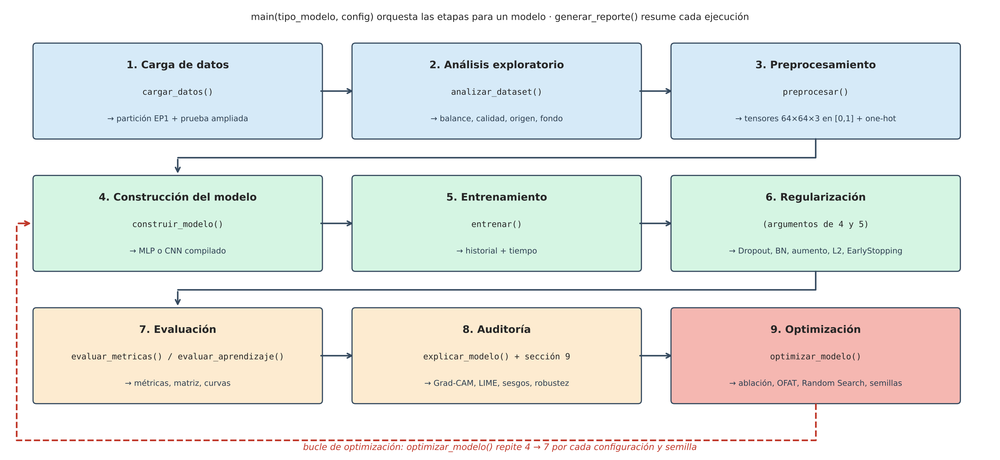

In [5]:
def dibujar_pipeline():
    """Diagrama del pipeline integrado: etapas, funciones y flujo de datos."""
    etapas = [
        ("1. Carga de datos", "cargar_datos()", "partición EP1 + prueba ampliada"),
        ("2. Análisis exploratorio", "analizar_dataset()", "balance, calidad, origen, fondo"),
        ("3. Preprocesamiento", "preprocesar()", "tensores 64×64×3 en [0,1] + one-hot"),
        ("4. Construcción del modelo", "construir_modelo()", "MLP o CNN compilado"),
        ("5. Entrenamiento", "entrenar()", "historial + tiempo"),
        ("6. Regularización", "(argumentos de 4 y 5)", "Dropout, BN, aumento, L2, EarlyStopping"),
        ("7. Evaluación", "evaluar_metricas() / evaluar_aprendizaje()", "métricas, matriz, curvas"),
        ("8. Auditoría", "explicar_modelo() + sección 9", "Grad-CAM, LIME, sesgos, robustez"),
        ("9. Optimización", "optimizar_modelo()", "ablación, OFAT, Random Search, semillas"),
    ]
    W, H = 4.3, 1.35
    pos = [(0.45 + 4.85 * (i % 3), 4.55 - 2.0 * (i // 3)) for i in range(9)]
    colores = ["#d6eaf8"] * 3 + ["#d5f5e3"] * 3 + ["#fdebd0"] * 2 + ["#f5b7b1"]
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.set_xlim(0, 15); ax.set_ylim(-0.25, 6.5); ax.axis("off")
    for (titulo, funcion, salida), (x, y), color in zip(etapas, pos, colores):
        ax.add_patch(mpatches.FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.05", fc=color, ec="#34495e", lw=1.2))
        ax.text(x + W / 2, y + 1.02, titulo, ha="center", fontsize=11, fontweight="bold")
        ax.text(x + W / 2, y + 0.62, funcion, ha="center", fontsize=9, family="monospace")
        ax.text(x + W / 2, y + 0.22, "→ " + salida, ha="center", fontsize=8.5, color="#2c3e50")
    flecha = dict(arrowstyle="->", lw=1.6, color="#34495e")
    for i in range(8):
        (x0, y0), (x1, y1) = pos[i], pos[i + 1]
        if y0 == y1:                                   # misma fila: flecha horizontal
            ax.annotate("", xy=(x1, y1 + H / 2), xytext=(x0 + W, y0 + H / 2), arrowprops=flecha)
        else:                                          # cambio de fila: conector en ángulo por el hueco
            ym = y0 - 0.33
            ax.plot([x0 + W / 2, x0 + W / 2, x1 + W / 2], [y0 - 0.05, ym, ym], color="#34495e", lw=1.6)
            ax.annotate("", xy=(x1 + W / 2, y1 + H + 0.05), xytext=(x1 + W / 2, ym), arrowprops=flecha)
    # Bucle de optimización: de la etapa 9 vuelve a la 4 (por fuera de las cajas)
    (x9, y9), (x4, y4) = pos[8], pos[3]
    rojo = dict(color="#c0392b", lw=1.8, ls="--")
    ax.plot([x9 + W / 2, x9 + W / 2, 0.15, 0.15], [y9 - 0.05, -0.05, -0.05, y4 + H / 2], **rojo)
    ax.annotate("", xy=(x4 - 0.05, y4 + H / 2), xytext=(0.15, y4 + H / 2),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#c0392b"))
    ax.text(7.5, -0.2, "bucle de optimización: optimizar_modelo() repite 4 → 7 por cada configuración y semilla",
            ha="center", fontsize=9.5, color="#c0392b", style="italic")
    ax.text(7.5, 6.3, "main(tipo_modelo, config) orquesta las etapas para un modelo · "
            "generar_reporte() resume cada ejecución", ha="center", fontsize=10)
    plt.tight_layout()
    save_fig("ep3_00_pipeline.png")
    plt.show()


def save_fig(nombre):
    """Guarda la figura actual en images/ para el informe y la presentación."""
    destino = IMAGES_DIR / nombre
    plt.savefig(destino, dpi=150, bbox_inches="tight")
    print("Figura guardada:", destino.name)


dibujar_pipeline()

| Etapa | Función | Entrada → salida | Propósito y justificación |
|---|---|---|---|
| 1. Carga | `cargar_datos()` | carpetas de imágenes + `particion_*.csv` de la EP1 → DataFrames `train/val/test/ampliada` | **Una sola fuente de verdad**: se lee la partición exacta de la EP1, de modo que las diferencias entre modelos se deban al modelo y no al muestreo. Además arma la prueba ampliada con las imágenes no muestreadas, filtrando duplicados y hojas repetidas para evitar fugas. |
| 2. EDA | `analizar_dataset()` | DataFrames → tablas y figuras | Conocer el dataset antes de modelar: balance, calidad, duplicados, origen de captura y color de fondo. Aquí se detectan los sesgos que luego se auditan. |
| 3. Preprocesamiento | `preprocesar()`, `construir_aumento()` | rutas → tensores `(N, 64, 64, 3)` en [0, 1] + etiquetas one-hot | Mismo preprocesamiento para ambos modelos (comparación justa). El aumento se define como capas del modelo para que **solo actúe al entrenar**. |
| 4. Construcción | `construir_modelo(tipo_modelo, ...)` | hiperparámetros → modelo compilado | Una sola interfaz para MLP y CNN; todos los hiperparámetros son argumentos, lo que permite optimizarlos sin tocar el código. |
| 5. Entrenamiento | `entrenar()` | modelo + tensores → historial, tiempo | Protocolo idéntico para todos los experimentos (tope de épocas, callbacks, lote). |
| 6. Regularización | argumentos de 4 y 5 | — | Dropout, BatchNorm, L2, aumento de datos, *label smoothing* (en el modelo) y EarlyStopping (en el entrenamiento). Se activan o desactivan por configuración para medir su efecto (sección 6). |
| 7. Evaluación | `evaluar_metricas()`, `evaluar_aprendizaje()` | modelo + datos → métricas, matriz, curvas, diagnóstico | Múltiples métricas: accuracy, precision, recall, F1, ROC-AUC, recall de enfermas, enfermas→sana, calibración (ECE). |
| 8. Auditoría | `explicar_modelo()` y funciones de 9.3 | modelo + imágenes → mapas XAI, sesgos, robustez | Grad-CAM (CNN), LIME (MLP y CNN), rendimiento por origen, intervención del fondo y perturbaciones. |
| 9. Optimización | `optimizar_modelo()`, `experimento()` | lista de configuraciones → tabla comparativa | Ejecuta 4→7 por cada configuración y semilla, guarda cada resultado en caché y compara solo con **validación**. |
| Orquestación | `main()`, `generar_reporte()` | tipo + configuración → reporte | Ejecuta el flujo completo para un modelo (estructura de la Actividad 3.4). |

**Principios de diseño**

1. **Validación para decidir, prueba solo al final.** Todas las comparaciones de las secciones 6 y 7 usan las 300 imágenes de validación. La prueba oficial y la ampliada se abren recién en la sección 8, con los modelos ya elegidos.
2. **Un cambio a la vez.** Cada experimento modifica un único hiperparámetro respecto de la base (experimentación controlada).
3. **Mismas condiciones para MLP y CNN.** Mismos datos, preprocesamiento, aumento, tope de épocas, callbacks, optimizador y semillas.
4. **Reproducibilidad.** Semilla única, operaciones deterministas y una caché (`models/ep3_experimentos/`) con la configuración, el historial y las métricas de cada experimento, identificados por un hash de la configuración.

## 3. Implementación del pipeline

Todas las funciones se definen aquí y se ejecutan a partir de la sección 4.

### 3.1 Utilidades

In [6]:
def es(x, d=4):
    """Número con coma decimal (informe en español)."""
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def nombre_valido(texto):
    """Keras solo acepta letras, dígitos, '.', '_', '/' y '-' en los nombres."""
    return re.sub(r"[^A-Za-z0-9_.\-]", "_", str(texto)).strip("_") or "modelo"


def codigo_crudo(nombre_archivo):
    """Prefijo de sesión que PlantVillage deja en el nombre del archivo (sin agrupar)."""
    sufijo = Path(nombre_archivo).stem.split("___", 1)[-1]
    m = re.match(r"^(.*?)\s*(?:[Ll]eaf\s*)?\d", sufijo)
    return (m.group(1).strip() if m else "") or "desconocido"


def origen_captura(nombre_archivo):
    """Origen de captura agrupado. Ej.: 'RS_Erly.B 8378.JPG' → 'RS_Erly.B'.

    Las subsesiones GHLB, GHLB2, GHLB2ES y GHLB_PS se agrupan como 'GHLB*'.
    """
    codigo = codigo_crudo(nombre_archivo)
    return "GHLB*" if codigo.startswith("GHLB") else codigo


def hoja_id(nombre_archivo):
    """Identificador de la hoja física cuando el nombre trae 'Leaf N' (si no, None).

    Ej.: 'GHLB_PS Leaf 1 Day 7' y 'GHLB_PS Leaf 1 Day 18' son la misma hoja en dos días.
    """
    sufijo = Path(nombre_archivo).stem.split("___", 1)[-1]
    m = re.search(r"[Ll]eaf\s*(\d+)", sufijo)
    return f"{codigo_crudo(nombre_archivo)}|{int(m.group(1))}" if m else None


def mascara_hoja(img):
    """Máscara booleana hoja/fondo (64×64) por color: saturación, brillo y tono verde-café.

    El fondo de PlantVillage es gris, negro o violáceo (poca saturación o tono azul);
    la hoja y sus lesiones van del verde al café. Se rellenan los huecos (lesiones
    oscuras) y se conserva el componente más grande.
    """
    hsv = rgb2hsv(np.clip(img, 0, 1))
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    m = (s > 0.18) & (v > 0.12) & (h > 0.02) & (h < 0.50)
    m = ndi.binary_opening(m, iterations=1)
    etiquetas, n = ndi.label(m)
    if n:
        tamanos = ndi.sum(m, etiquetas, range(1, n + 1))
        m = etiquetas == (int(np.argmax(tamanos)) + 1)
    m = ndi.binary_closing(m, iterations=2)
    return ndi.binary_fill_holes(m)


def ece(y_true, y_prob, n_bins=10):
    """Expected Calibration Error: diferencia media entre confianza y acierto (0 = calibrado)."""
    conf, ok = y_prob.max(axis=1), (y_prob.argmax(axis=1) == y_true)
    bordes, total = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(bordes[:-1], bordes[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(total)


def wilson(aciertos, n, z=1.96):
    """Intervalo de confianza de Wilson (95 %) para una proporción."""
    if n == 0:
        return (np.nan, np.nan)
    p = aciertos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centro - margen, centro + margen)


def mcnemar(y, pred_a, pred_b):
    """Prueba de McNemar exacta: solo cuentan las imágenes donde los modelos discrepan."""
    ok_a, ok_b = pred_a == y, pred_b == y
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return {"solo A acierta": b, "solo B acierta": c,
            "p": binomtest(b, b + c, 0.5).pvalue if b + c else 1.0}

### 3.2 Etapa 1 — `cargar_datos()`

Lee la partición exacta de la EP1 y construye la **prueba ampliada**: todas las imágenes de las cinco clases que no entraron al muestreo de 400 por clase. Para que esa prueba sea honesta se excluyen las imágenes que podrían filtrar información del entrenamiento:

- **duplicados exactos** (mismo contenido, distinto nombre) de una imagen de la muestra;
- **otras fotos de la misma hoja física** (el nombre trae `Leaf N`) que ya está en la muestra;
- imágenes con **posible error de etiqueta** (origen de captura que corresponde a otra clase o desconocido);
- duplicados exactos dentro de la propia prueba ampliada.

In [7]:
def listar_imagenes(data_root):
    """Inventario de todas las imágenes de las cinco clases con su origen, hoja y huella MD5."""
    filas = []
    for clase in SELECTED_CLASSES:
        for p in sorted((Path(data_root) / clase).iterdir()):
            if p.suffix.lower() in IMAGE_EXTS:
                filas.append({"path": str(p), "path_rel": f"{clase}/{p.name}", "label": clase})
    df = pd.DataFrame(filas)
    df["label_id"] = df["label"].map(LABEL_TO_ID).astype("int32")
    df["origen"] = df["path_rel"].map(origen_captura)
    df["hoja"] = df["path_rel"].map(hoja_id)
    df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df["path"]]
    # Un origen pertenece a la clase donde más aparece; si aparece en otra, la etiqueta es dudosa.
    dominante = pd.crosstab(df["origen"], df["label"]).idxmax(axis=1)
    df["sospechosa"] = (df["origen"] == "desconocido") | (df["origen"].map(dominante) != df["label"])
    return df


def cargar_datos():
    """Etapa 1 — Carga de datos.

    Returns
    -------
    dict con:
        'train', 'val', 'test' : partición exacta de la EP1 (1.400 / 300 / 300 imágenes).
        'ampliada'             : imágenes no muestreadas, filtradas (solo para auditar al final).
        'excluidas'            : imágenes no muestreadas que se descartaron y el motivo.
        'todas'                : inventario completo de las cinco clases.
    Cada DataFrame trae: path, path_rel, label, label_id, origen, hoja, md5, sospechosa.
    """
    todas = listar_imagenes(DATA_ROOT)
    datos = {}
    for nombre in ("train", "val", "test"):
        d = pd.read_csv(ARTEFACTOS_DIR / f"particion_{nombre}.csv").rename(columns={"path": "path_rel"})
        d = d.merge(todas.drop(columns=["label", "label_id"]), on="path_rel", how="left",
                    validate="one_to_one")
        assert d["path"].notna().all(), (
            f"{d['path'].isna().sum()} imágenes de particion_{nombre}.csv no están en el dataset. "
            "¿Es el mismo PlantVillage de la EP1?")
        assert (d["label"].map(LABEL_TO_ID) == d["label_id"]).all(), "label_id no coincide con la variante"
        datos[nombre] = d

    s_tr, s_va, s_te = (set(datos[n]["path_rel"]) for n in ("train", "val", "test"))
    assert not (s_tr & s_va or s_tr & s_te or s_va & s_te), "Hay imágenes repetidas entre subconjuntos"

    muestra = pd.concat([datos[n] for n in ("train", "val", "test")])
    todas["en_muestra"] = todas["path_rel"].isin(muestra["path_rel"])
    resto = todas[~todas["en_muestra"]].copy()
    resto["motivo"] = np.select(
        [resto["md5"].isin(set(muestra["md5"])),
         resto["hoja"].isin(set(muestra["hoja"].dropna())),
         resto["sospechosa"],
         resto["md5"].duplicated()],
        ["duplicado exacto de una imagen de la muestra",
         "otra foto de una hoja que está en la muestra",
         "posible error de etiqueta (origen de otra clase)",
         "duplicado dentro de la prueba ampliada"],
        default="")
    datos["ampliada"] = resto[resto["motivo"] == ""].drop(columns="motivo").reset_index(drop=True)
    datos["excluidas"] = resto[resto["motivo"] != ""].reset_index(drop=True)
    datos["todas"] = todas

    print(f"Inventario de las 5 clases : {len(todas):,} imágenes")
    print(f"Muestra de la EP1          : {len(datos['train'])} entrenamiento | {len(datos['val'])} "
          f"validación | {len(datos['test'])} prueba (sin solapamiento ✓)")
    print(f"Prueba ampliada            : {len(datos['ampliada']):,} imágenes no usadas por la EP1/EP2")
    print(f"Excluidas de la ampliada   : {len(datos['excluidas'])}")
    for motivo, n in datos["excluidas"]["motivo"].value_counts().items():
        print(f"   · {motivo}: {n}")
    return datos

### 3.3 Etapa 2 — `analizar_dataset()`

Reúne cuatro análisis, cada uno en su propia función para poder ejecutarlos y comentarlos por separado: reparto de clases, control de calidad (corruptas, duplicados, hojas repetidas, etiquetas dudosas), ejemplos por clase y origen, y **origen de captura y color de fondo** (fuente de sesgo).

In [8]:
def resumen_particion(datos, mostrar=True):
    """Imágenes por clase en cada subconjunto + gráfico de distribución."""
    reparto = pd.DataFrame({
        "entrenamiento": datos["train"]["label"].value_counts(),
        "validación": datos["val"]["label"].value_counts(),
        "prueba": datos["test"]["label"].value_counts(),
        "prueba ampliada": datos["ampliada"]["label"].value_counts(),
    }).reindex(SELECTED_CLASSES).fillna(0).astype(int)
    reparto.index = CORTO
    if mostrar:
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
        reparto[["entrenamiento", "validación", "prueba"]].plot(kind="bar", stacked=True, ax=axes[0],
                                                                color=["#2c7fb8", "#7fcdbb", "#edf8b1"])
        axes[0].set_title("Muestra de la EP1: 400 imágenes por clase (balanceada)")
        axes[0].set_ylabel("imágenes"); axes[0].tick_params(axis="x", rotation=20)
        reparto["prueba ampliada"].plot(kind="bar", ax=axes[1], color="#95a5a6")
        for i, v in enumerate(reparto["prueba ampliada"]):
            axes[1].text(i, v + 15, f"{v:,}".replace(",", "."), ha="center", fontsize=9)
        axes[1].set_title("Prueba ampliada (imágenes no muestreadas): desbalanceada")
        axes[1].tick_params(axis="x", rotation=20)
        plt.tight_layout(); save_fig("ep3_02_distribucion.png"); plt.show()
    out = reparto.copy()
    out.loc["TOTAL"] = out.sum()
    return out


def control_calidad(datos, mostrar=True):
    """Corruptas, modos de color, resoluciones, duplicados, hojas repetidas y etiquetas dudosas."""
    muestra = pd.concat([datos[s].assign(subconjunto=s) for s in ("train", "val", "test")], ignore_index=True)
    registros = []
    for p in muestra["path"]:
        try:
            with Image.open(p) as img:
                registros.append((img.mode, f"{img.width}x{img.height}", False))
        except Exception:
            registros.append((None, None, True))
    modos, resol, corrupta = zip(*registros)

    dup = muestra[muestra["md5"].duplicated(keep=False)]
    grupos_dup = dup.groupby("md5").agg(n=("path", "size"),
                                        subconjuntos=("subconjunto", lambda s: ", ".join(sorted(set(s)))))
    hojas = (muestra.dropna(subset=["hoja"]).groupby("hoja")
             .agg(fotos=("path", "size"), clase=("label", "first"),
                  subconjuntos=("subconjunto", lambda s: ", ".join(sorted(set(s))))))
    hojas_multi = hojas[hojas["fotos"] > 1]
    hojas_cruzadas = hojas_multi[hojas_multi["subconjuntos"].str.contains(",")]
    hojas_train = set(datos["train"]["hoja"].dropna())
    test_con_hermana = datos["test"]["hoja"].isin(hojas_train)
    sospechosas = muestra[muestra["sospechosa"]]

    res = {
        "corruptas": int(sum(corrupta)),
        "modos": pd.Series(modos).value_counts().to_dict(),
        "resoluciones": pd.Series(resol).value_counts().to_dict(),
        "grupos_duplicados": grupos_dup,
        "hojas_multi": hojas_multi,
        "hojas_cruzadas": hojas_cruzadas,
        "test_con_hermana_en_train": test_con_hermana,
        "sospechosas_muestra": sospechosas,
        "excluidas_ampliada": datos["excluidas"],
    }
    if mostrar:
        print("Imágenes corruptas                         :", res["corruptas"])
        print("Modos de color                             :", res["modos"])
        print("Resoluciones                               :", res["resoluciones"])
        print("Grupos de duplicados exactos en la muestra :", len(grupos_dup),
              f"({len(dup)} archivos; subconjuntos: {sorted(set(grupos_dup['subconjuntos']))})")
        print("Hojas fotografiadas más de una vez         :", len(hojas_multi),
              f"({int(hojas_multi['fotos'].sum())} fotos)")
        print("  de ellas, repartidas entre subconjuntos  :", len(hojas_cruzadas))
        print("Imágenes de prueba cuya hoja está en train :", int(test_con_hermana.sum()), "de", len(datos["test"]))
        print("Etiquetas dudosas dentro de la muestra     :", len(sospechosas))
        dudosas = pd.concat([sospechosas.assign(donde="muestra (" + sospechosas["subconjunto"] + ")"),
                             datos["excluidas"][datos["excluidas"]["motivo"].str.startswith("posible")]
                             .assign(donde="no muestreada")], ignore_index=True)
        if len(dudosas):
            fig, axes = plt.subplots(1, len(dudosas), figsize=(3.2 * len(dudosas), 3.6), squeeze=False)
            for ax, fila in zip(axes[0], dudosas.itertuples()):
                with Image.open(fila.path) as img:
                    ax.imshow(img)
                ax.set_title(f"etiqueta: {fila.label.replace('Tomato_', '')}\norigen: {fila.origen}\n{fila.donde}",
                             fontsize=9)
                ax.axis("off")
            plt.suptitle("Imágenes con posible error de etiqueta", y=1.04)
            plt.tight_layout(); save_fig("ep3_02_etiquetas_dudosas.png"); plt.show()
    return res


def ejemplos_por_origen(datos, n=5):
    """Una fila por combinación clase–origen: permite ver las diferencias de fondo y luz."""
    muestra = pd.concat([datos[s] for s in ("train", "val", "test")], ignore_index=True)
    grupos = [(c, o) for c in SELECTED_CLASSES
              for o in muestra.loc[muestra["label"] == c, "origen"].value_counts().index
              if (muestra["origen"] == o).sum() >= n]
    rng = np.random.RandomState(SEED)
    fig, axes = plt.subplots(len(grupos), n, figsize=(2.1 * n, 2.2 * len(grupos)))
    for r, (c, o) in enumerate(grupos):
        rutas = muestra.loc[(muestra["label"] == c) & (muestra["origen"] == o), "path"].to_numpy()
        for j, ruta in enumerate(rng.choice(rutas, n, replace=False)):
            with Image.open(ruta) as img:
                axes[r, j].imshow(img)
            axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
        axes[r, 0].set_ylabel(f"{c.replace('Tomato_', '')}\n{o}", fontsize=9)
    plt.suptitle("Ejemplos por clase y origen de captura (resolución original)", y=1.0)
    plt.tight_layout(); save_fig("ep3_02_ejemplos_origen.png"); plt.show()


def color_fondo(rutas, max_imagenes=80):
    """Color RGB medio (0-255) del fondo, usando la máscara de la hoja."""
    acumulado = []
    for ruta in list(rutas)[:max_imagenes]:
        with Image.open(ruta) as img:
            x = np.asarray(img.convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
        fondo = ~mascara_hoja(x)
        if fondo.sum() > 50:
            acumulado.append(x[fondo].mean(axis=0))
    return np.mean(acumulado, axis=0) * 255 if acumulado else np.full(3, np.nan)


def analizar_origen(datos, mostrar=True):
    """Cruce clase × origen de captura y color de fondo por origen."""
    muestra = pd.concat([datos[s] for s in ("train", "val", "test")], ignore_index=True)
    cruce = pd.crosstab(muestra["origen"], muestra["label"]).reindex(columns=SELECTED_CLASSES)
    cruce.columns = CORTO
    cruce = cruce.loc[cruce.sum(axis=1).sort_values(ascending=False).index]
    filas = []
    for (clase, origen), g in muestra.groupby(["label", "origen"]):
        if len(g) < 10:
            continue
        rgb = color_fondo(g["path"].sample(frac=1, random_state=SEED))
        filas.append({"clase": clase.replace("Tomato_", ""), "origen": origen, "imágenes": len(g),
                      "R": rgb[0], "G": rgb[1], "B": rgb[2], "B − R": rgb[2] - rgb[0]})
    fondo = pd.DataFrame(filas).round(1)
    if mostrar:
        fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
        sns.heatmap(cruce, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
        axes[0].set_title("Muestra de la EP1: imágenes por origen de captura y clase")
        axes[0].set_xlabel("clase"); axes[0].set_ylabel("origen (prefijo del archivo)")
        etiquetas = fondo["clase"] + "\n" + fondo["origen"]
        axes[1].bar(etiquetas, fondo["B − R"],
                    color=[tuple(np.clip(c / 255, 0, 1)) for c in fondo[["R", "G", "B"]].to_numpy()],
                    edgecolor="black")
        axes[1].axhline(0, color="black", lw=0.8)
        axes[1].set_title("Tinte del fondo por origen (B − R; barra pintada con el color medio del fondo)")
        axes[1].set_ylabel("azul − rojo (0-255)")
        axes[1].tick_params(axis="x", rotation=45, labelsize=8)
        plt.tight_layout(); save_fig("ep3_02_origen_fondo.png"); plt.show()
    return {"cruce": cruce, "fondo": fondo}


def analizar_dataset(datos, mostrar=True):
    """Etapa 2 — Análisis exploratorio y auditoría de los datos (llama a las funciones anteriores)."""
    resultado = {"reparto": resumen_particion(datos, mostrar),
                 "calidad": control_calidad(datos, mostrar),
                 "origen": analizar_origen(datos, mostrar)}
    if mostrar:
        ejemplos_por_origen(datos)
    return resultado

### 3.4 Etapa 3 — `preprocesar()` y aumento de datos

Mismo preprocesamiento de la EP1/EP2 (remuestreo bilineal a 64×64 y escalado a [0, 1]). Las etiquetas se pasan a **one-hot**, como en el pipeline de la Actividad 3.5, porque así la pérdida `CategoricalCrossentropy` admite *label smoothing* (la versión *sparse* no lo permite en Keras 3).

El aumento de datos se arma con `construir_aumento()` en tres intensidades, para poder compararlas en la optimización:

| Tipo | Capas | Qué simula |
|---|---|---|
| `ninguno` | — | Solo para la ablación |
| `geom` (EP1/EP2) | espejo horizontal + rotación ±18° | Orientación de la hoja |
| `geom+color` | `geom` + brillo ±15 %, contraste ±20 %, **balance de blancos** ±10 % por canal | Otra cámara u otra iluminación. Ataca el tinte del fondo propio de cada origen. |
| `geom+color+zoom` | `geom+color` + zoom ±10 % + traslación ±10 % | Encuadre distinto: la hoja no siempre centrada |

El balance de blancos no existe como capa en Keras, así que se implementa una capa propia (`BalanceBlancoAleatorio`): multiplica cada canal RGB por una ganancia aleatoria entre 0,9 y 1,1, solo durante el entrenamiento.

In [9]:
@keras.saving.register_keras_serializable(package="ep3")
class BalanceBlancoAleatorio(layers.Layer):
    """Multiplica cada canal RGB por una ganancia aleatoria en [1 − factor, 1 + factor].

    Simula fotos tomadas con otra cámara o bajo otra luz (cambia el tinte, no la forma).
    Solo actúa con training=True; en inferencia es la identidad.
    """

    def __init__(self, factor=0.10, seed=None, **kwargs):
        super().__init__(**kwargs)
        self.factor, self.seed = factor, seed
        self.generador = keras.random.SeedGenerator(seed)

    def call(self, x, training=None):
        if not training:
            return x
        n = keras.ops.shape(x)[0]
        ganancia = keras.random.uniform((n, 1, 1, 3), 1 - self.factor, 1 + self.factor, seed=self.generador)
        return keras.ops.clip(x * ganancia, 0.0, 1.0)

    def get_config(self):
        return {**super().get_config(), "factor": self.factor, "seed": self.seed}


def construir_aumento(tipo="geom"):
    """Lista de capas de aumento de datos (activas solo al entrenar)."""
    if tipo == "ninguno":
        return []
    capas = [layers.RandomFlip("horizontal", name="aug_espejo"),
             layers.RandomRotation(0.05, name="aug_rotacion")]          # ±0,05 vueltas ≈ ±18°
    if "color" in tipo:
        capas += [layers.RandomBrightness(0.15, value_range=(0, 1), name="aug_brillo"),
                  layers.RandomContrast(0.20, value_range=(0, 1), name="aug_contraste"),
                  BalanceBlancoAleatorio(0.10, name="aug_balance_blancos")]
    if "zoom" in tipo:
        capas += [layers.RandomZoom(0.10, name="aug_zoom"),
                  layers.RandomTranslation(0.10, 0.10, name="aug_traslacion")]
    return capas


def cargar_tensores(df):
    """Carga un subconjunto como tensor (N, 64, 64, 3) en [0, 1] (mismo remuestreo de la EP1)."""
    X = np.zeros((len(df), *INPUT_SHAPE), dtype=np.float32)
    for i, ruta in enumerate(df["path"]):
        with Image.open(ruta) as img:
            X[i] = np.asarray(img.convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    return X, df["label_id"].to_numpy(dtype=np.int32)


def preprocesar(datos, mostrar=True):
    """Etapa 3 — Preprocesamiento.

    Returns
    -------
    dict T con X_{train,val,test} (float32 en [0,1]), y_{...} (enteros 0-4) e Y_{...} (one-hot).
    La prueba ampliada se carga recién en la sección 8 (no se necesita antes).
    """
    T = {}
    for nombre in ("train", "val", "test"):
        X, y = cargar_tensores(datos[nombre])
        assert not np.isnan(X).any() and 0.0 <= X.min() and X.max() <= 1.0, f"{nombre} mal normalizado"
        T[f"X_{nombre}"], T[f"y_{nombre}"] = X, y
        T[f"Y_{nombre}"] = keras.utils.to_categorical(y, NUM_CLASSES).astype("float32")
        if mostrar:
            print(f"{nombre:<6} X={X.shape}  rango=[{X.min():.2f}, {X.max():.2f}]  "
                  f"media={X.mean():.3f}  Y one-hot={T[f'Y_{nombre}'].shape}")
    return T


def mostrar_aumento(T, n=6):
    """Mismas imágenes con los tres niveles de aumento (figura para el informe)."""
    filas = [("original", None), ("geom", "geom"), ("geom+color", "geom+color"),
             ("geom+color+zoom", "geom+color+zoom")]
    fig, axes = plt.subplots(len(filas), n, figsize=(1.9 * n, 2.0 * len(filas)))
    base = T["X_train"][:n]
    for r, (titulo, tipo) in enumerate(filas):
        if tipo is None:
            imgs = base
        else:
            fijar_semilla(SEED)
            aug = keras.Sequential(construir_aumento(tipo))
            imgs = np.clip(aug(base, training=True).numpy(), 0, 1)
        for j in range(n):
            axes[r, j].imshow(imgs[j]); axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
        axes[r, 0].set_ylabel(titulo, fontsize=10)
    plt.suptitle("Aumento de datos (solo durante el entrenamiento)", y=1.0)
    plt.tight_layout(); save_fig("ep3_03_aumento.png"); plt.show()

### 3.5 Etapa 4 — `construir_modelo()`

Una sola función construye las dos arquitecturas, como pide la Actividad 3.4. Todos los hiperparámetros son argumentos (Actividad 3.5), así que la optimización no modifica el código, solo la configuración.

- **MLP:** `aumento → Flatten → [Dense → BatchNorm → ReLU → Dropout] × capas → Dense(5) → Softmax`. Con `capas=(256, 128)`, `dropout=0,3` y `l2=1e-4` es **exactamente el MLP de la EP1**.
- **CNN:** `aumento → [Conv2D 3×3 → BatchNorm → ReLU → MaxPool] × bloques → Flatten o GAP → Dense → Dropout → Dense(5) → Softmax`. Con `filtros=(32, 64, 128)`, `cabeza="flatten"`, `neuronas=128` y `dropout=0,4` es **exactamente la CNN de la EP2**.

En ambos, la capa de salida se separa en `logits` + `Softmax`: Grad-CAM deriva sobre los logits para que el gradiente no se anule cuando el softmax satura.

In [10]:
CONFIG_BASE = {
    # MLP de la EP1
    "MLP": dict(tipo_modelo="MLP", capas=(256, 128), dropout=0.30, batchnorm=True, l2=1e-4,
                aumento="geom", learning_rate=1e-3, label_smoothing=0.0,
                batch_size=32, early_stopping=True),
    # CNN de la EP2
    "CNN": dict(tipo_modelo="CNN", filtros=(32, 64, 128), cabeza="flatten", neuronas=128, dropout=0.40,
                batchnorm=True, l2=0.0, aumento="geom", learning_rate=1e-3, label_smoothing=0.0,
                batch_size=32, early_stopping=True),
}


def construir_modelo(tipo_modelo="CNN", capas=(256, 128), filtros=(32, 64, 128), cabeza="flatten",
                     neuronas=128, dropout=0.4, batchnorm=True, l2=0.0, aumento="geom",
                     learning_rate=1e-3, label_smoothing=0.0, nombre=None, **_):
    """Etapa 4 — Construye y compila un MLP o una CNN.

    Parámetros
    ----------
    tipo_modelo     : "MLP" o "CNN".
    capas           : (MLP) neuronas de cada capa oculta.
    filtros         : (CNN) filtros de cada bloque convolucional; un bloque por valor.
    cabeza          : (CNN) "flatten" (EP2) o "gap" (GlobalAveragePooling2D).
    neuronas        : (CNN) neuronas de la capa densa final.
    dropout         : probabilidad de Dropout (0 = sin Dropout).
    batchnorm       : usa BatchNormalization tras cada capa oculta/convolucional.
    l2              : intensidad de la penalización L2 en las capas ocultas (0 = sin L2).
    aumento         : "ninguno", "geom", "geom+color" o "geom+color+zoom".
    learning_rate   : tasa de aprendizaje de Adam.
    label_smoothing : suavizado de etiquetas de la pérdida (0 = sin suavizado).
    Los argumentos de entrenamiento (batch_size, early_stopping) se ignoran aquí.
    """
    reg = keras.regularizers.l2(l2) if l2 else None
    c = [layers.Input(shape=INPUT_SHAPE, name="entrada")] + construir_aumento(aumento)
    if tipo_modelo == "CNN":
        for i, f in enumerate(filtros, start=1):
            c.append(layers.Conv2D(f, (3, 3), padding="same", kernel_initializer="he_normal",
                                   kernel_regularizer=reg, name=f"conv{i}"))
            if batchnorm:
                c.append(layers.BatchNormalization(name=f"bn{i}"))
            c.append(layers.Activation("relu", name=f"relu{i}"))
            c.append(layers.MaxPooling2D((2, 2), name=f"pool{i}"))
        c.append(layers.GlobalAveragePooling2D(name="gap") if cabeza == "gap" else layers.Flatten(name="flatten"))
        c.append(layers.Dense(neuronas, activation="relu", kernel_initializer="he_normal",
                              kernel_regularizer=reg, name="densa1"))
        if dropout:
            c.append(layers.Dropout(dropout, name="dropout1"))
    elif tipo_modelo == "MLP":
        c.append(layers.Flatten(name="flatten"))
        for i, u in enumerate(capas, start=1):
            c.append(layers.Dense(u, kernel_initializer="he_normal", kernel_regularizer=reg, name=f"densa{i}"))
            if batchnorm:
                c.append(layers.BatchNormalization(name=f"bn{i}"))
            c.append(layers.Activation("relu", name=f"relu{i}"))
            if dropout:
                c.append(layers.Dropout(dropout, name=f"dropout{i}"))
    else:
        raise ValueError("tipo_modelo debe ser 'MLP' o 'CNN'")
    c += [layers.Dense(NUM_CLASSES, name="logits"), layers.Softmax(name="softmax")]
    modelo = Sequential(c, name=nombre_valido(nombre or tipo_modelo))
    modelo.compile(optimizer=Adam(learning_rate=learning_rate),
                   loss=keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
                   metrics=["accuracy"])
    return modelo

### 3.6 Etapas 5 y 6 — `entrenar()` y regularización

La regularización vive en dos lugares: en el modelo (Dropout, BatchNorm, L2, aumento de datos, *label smoothing*) y en el entrenamiento (`EarlyStopping` con restauración de la mejor época). `ReduceLROnPlateau` no regulariza, pero estabiliza el final del entrenamiento; se mantiene igual en todos los experimentos.

In [11]:
def crear_callbacks(early_stopping=True):
    """EarlyStopping (opcional) + ReduceLROnPlateau, ambos sobre val_loss."""
    cb = [ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PACIENCIA_LR, min_lr=1e-6, verbose=0)]
    if early_stopping:
        cb.insert(0, EarlyStopping(monitor="val_loss", patience=PACIENCIA_ES,
                                   restore_best_weights=True, verbose=0))
    return cb


def entrenar(modelo, T, batch_size=32, early_stopping=True, epochs=EPOCHS, verbose=0):
    """Etapa 5 — Entrena con validación explícita (las 300 imágenes de validación de la EP1).

    Returns
    -------
    modelo entrenado (con la mejor época si hay EarlyStopping), historial (DataFrame indexado
    por época) e info (tiempo total, épocas ejecutadas, época del modelo conservado).
    """
    t0 = time.perf_counter()
    h = modelo.fit(T["X_train"], T["Y_train"], validation_data=(T["X_val"], T["Y_val"]),
                   epochs=epochs, batch_size=batch_size, callbacks=crear_callbacks(early_stopping),
                   verbose=verbose)
    tiempo = time.perf_counter() - t0
    hist = pd.DataFrame(h.history)
    hist.index = np.arange(1, len(hist) + 1)
    hist.index.name = "época"
    info = {"tiempo_s": tiempo, "epocas": len(hist), "s_por_epoca": tiempo / len(hist),
            # con EarlyStopping se conserva la época de menor val_loss; sin él, la última
            "epoca_modelo": int(hist["val_loss"].idxmin()) if early_stopping else len(hist)}
    return modelo, hist, info

### 3.7 Etapa 7 — `evaluar_metricas()` y `evaluar_aprendizaje()`

| Métrica | Qué responde en este problema |
|---|---|
| Accuracy | Proporción de hojas bien clasificadas (interpretable porque la muestra está balanceada). |
| Precision macro | De las hojas que el modelo llama "X", cuántas lo son: precision baja = falsas alarmas (tratamientos innecesarios). |
| Recall macro | De las hojas que son "X", cuántas detecta: recall bajo en enfermas = plantas sin tratar. |
| F1 macro | Media armónica de precision y recall, promediada sin ponderar entre clases. Es la **métrica de selección**: penaliza que una clase vaya mal aunque el promedio sea alto. |
| ROC-AUC (OvR, macro) | Capacidad de ordenar: si el modelo da más probabilidad a la clase correcta que a las demás, independiente del umbral. |
| Recall de enfermas / enfermas → sana | El error de mayor costo para el negocio. |
| ECE (error de calibración) | Si la confianza del modelo coincide con su tasa de acierto. Importa para derivar casos dudosos al agrónomo. |
| Brecha de generalización | Accuracy de entrenamiento **en modo inferencia** (sin aumento ni Dropout) menos accuracy de validación o prueba. |

In [12]:
def evaluar_metricas(modelo, X, y, mostrar=False, titulo="", archivo=None, y_prob=None):
    """Etapa 7a — Métricas de clasificación, matriz de confusión y classification report.

    Returns
    -------
    dict con 'metricas' (dict), 'cm' (matriz 5×5), 'reporte' (DataFrame por clase),
    'y_prob' y 'y_pred'.
    """
    if y_prob is None:
        y_prob = modelo.predict(X, verbose=0, batch_size=256)
    y_pred = y_prob.argmax(axis=1)
    cm = confusion_matrix(y, y_pred, labels=range(NUM_CLASSES))
    recall_clase = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
    m = {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y, y_prob, multi_class="ovr", average="macro", labels=range(NUM_CLASSES)),
        "recall_enfermas": float(recall_clase[IDX_ENFERMAS].mean()),
        "enfermas_a_sana": int(cm[IDX_ENFERMAS, ID_SANA].sum()),
        "n_enfermas": int(cm[IDX_ENFERMAS].sum()),
        "ece": ece(y, y_prob),
        "loss": float(-np.mean(np.log(y_prob[np.arange(len(y)), y] + 1e-12))),
    }
    reporte = pd.DataFrame(classification_report(y, y_pred, labels=range(NUM_CLASSES), target_names=CORTO,
                                                 output_dict=True, zero_division=0)).T.loc[CORTO]
    reporte["support"] = reporte["support"].astype(int)
    if mostrar:
        tabla = pd.Series({"Accuracy": m["accuracy"], "Precision (macro)": m["precision"],
                           "Recall (macro)": m["recall"], "F1-score (macro)": m["f1"],
                           "ROC-AUC (OvR, macro)": m["roc_auc"], "Recall clases enfermas": m["recall_enfermas"],
                           "Enfermas → sana": m["enfermas_a_sana"], "ECE (calibración)": m["ece"],
                           "Pérdida (crossentropy)": m["loss"]}, name=titulo or "valor")
        display(tabla.to_frame().round(4))
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CORTO, yticklabels=CORTO,
                    ax=axes[0])
        axes[0].set_title(f"{titulo} — matriz de confusión"); axes[0].set_xlabel("predicha"); axes[0].set_ylabel("real")
        sns.heatmap(cm / np.maximum(cm.sum(axis=1, keepdims=True), 1), annot=True, fmt=".2f", cmap="Blues",
                    cbar=False, vmin=0, vmax=1, xticklabels=CORTO, yticklabels=CORTO, ax=axes[1])
        axes[1].set_title("normalizada por fila (diagonal = recall)"); axes[1].set_xlabel("predicha")
        plt.tight_layout()
        if archivo:
            save_fig(archivo)
        plt.show()
        display(reporte.round(4))
    return {"metricas": m, "cm": cm, "reporte": reporte, "y_prob": y_prob, "y_pred": y_pred}


def evaluar_aprendizaje(hist, nombre="", epoca_modelo=None, acc_train_inferencia=None, mostrar=True,
                        archivo=None):
    """Etapa 7b — Curvas de aprendizaje y diagnóstico (overfitting / underfitting / buen ajuste).

    El diagnóstico se hace sobre la época del modelo conservado. La brecha usa la accuracy de
    entrenamiento en modo inferencia: la que reporta Keras al entrenar incluye aumento y
    Dropout activos y subestima lo que el modelo sabe del entrenamiento.
    """
    epoca_modelo = epoca_modelo or int(hist["val_loss"].idxmin())
    fila = hist.loc[epoca_modelo]
    acc_tr = acc_train_inferencia if acc_train_inferencia is not None else fila["accuracy"]
    brecha = acc_tr - fila["val_accuracy"]
    alza_final = hist["val_loss"].iloc[-1] / hist["val_loss"].min()
    if fila["val_accuracy"] < 0.50:
        diagnostico = "underfitting: el modelo no alcanza a aprender (capacidad o entrenamiento insuficientes)"
    elif brecha > 0.15:
        diagnostico = "sobreajuste: la brecha supera 0,15"
    elif brecha > KPI_BRECHA:
        diagnostico = "sobreajuste moderado: brecha entre 0,10 y 0,15"
    elif brecha > 0.05:
        diagnostico = "sobreajuste leve: brecha entre 0,05 y 0,10"
    else:
        diagnostico = "buena generalización: brecha ≤ 0,05"
    if mostrar:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
        axes[0].plot(hist.index, hist["loss"], label="entrenamiento")
        axes[0].plot(hist.index, hist["val_loss"], label="validación")
        axes[1].plot(hist.index, hist["accuracy"], label="entrenamiento (con aumento y Dropout)")
        axes[1].plot(hist.index, hist["val_accuracy"], label="validación")
        for ax, t in zip(axes, ("Pérdida", "Accuracy")):
            ax.axvline(epoca_modelo, color="gray", ls="--", label=f"modelo conservado (época {epoca_modelo})")
            ax.set_title(f"{nombre} — {t}"); ax.set_xlabel("época"); ax.legend(fontsize=8)
        axes[1].set_ylim(0, 1.02)
        plt.tight_layout()
        if archivo:
            save_fig(archivo)
        plt.show()
        print(f"Épocas ejecutadas: {len(hist)} | modelo conservado: época {epoca_modelo}")
        print(f"Accuracy entrenamiento (inferencia): {acc_tr:.4f} | validación: {fila['val_accuracy']:.4f} "
              f"| brecha: {brecha:+.4f}")
        print(f"val_loss final / mínima: {alza_final:.2f}×")
        print("Diagnóstico:", diagnostico)
    return {"epoca_modelo": epoca_modelo, "acc_train": float(acc_tr), "acc_val": float(fila["val_accuracy"]),
            "brecha": float(brecha), "alza_val_loss": float(alza_final), "diagnostico": diagnostico,
            "curvas": hist}

### 3.8 Etapa 8 — `explicar_modelo()`: Grad-CAM y LIME

Siguiendo la Actividad 3.4: **Grad-CAM** para la CNN (usa los gradientes de la última capa convolucional) y **LIME** para el MLP (no tiene capas convolucionales, así que se explica perturbando la imagen). LIME es agnóstico al modelo, por lo que **también se aplica a la CNN**: es la única forma de comparar la explicabilidad de ambos con la misma herramienta.

Para que la explicación no quede solo en una impresión visual, se mide **qué fracción de la evidencia cae sobre la hoja** (usando `mascara_hoja`). Si un modelo pone mucha evidencia en el fondo, está usando un atajo.

**Cómo funciona LIME aquí:** (1) divide la imagen en ~25–40 superpíxeles (`quickshift`); (2) genera 500 versiones apagando superpíxeles al azar (negro); (3) mira cómo cambia la probabilidad de la clase; (4) ajusta un modelo lineal local cuyos pesos indican cuánto aporta cada superpíxel.

In [13]:
def ultima_capa_conv(modelo):
    """Nombre de la última activación convolucional (salida 4D) de una CNN."""
    candidatas = [l.name for l in modelo.layers if l.name.startswith("relu") and len(l.output.shape) == 4]
    return candidatas[-1] if candidatas else None


def gradcam(modelo, img, clase=None):
    """Mapa Grad-CAM 64×64 en [0, 1] para la clase indicada (por defecto, la predicha).

    Se recorre el modelo capa por capa dentro de GradientTape (funciona igual con un modelo
    recién entrenado o cargado desde .keras) y se deriva el logit de la clase respecto de
    los mapas de la última capa convolucional.
    """
    capa_conv = ultima_capa_conv(modelo)
    h = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv = None
        for capa in modelo.layers:
            h = capa(h, training=False)
            if capa.name == capa_conv:
                conv = h
            if capa.name == "logits":
                break
        if clase is None:
            clase = int(tf.argmax(h[0]))
        score = h[:, clase]
    grads = tape.gradient(score, conv)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))                       # un peso por filtro
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * pesos, axis=-1))           # solo aportes positivos
    cam = tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear")[..., 0].numpy()
    return cam / (cam.max() + 1e-8), clase


def explicar_lime(modelo, img, clase=None, num_samples=LIME_MUESTRAS, semilla=SEED):
    """Explicación LIME de una imagen: mapa 64×64 con el peso positivo de cada superpíxel."""
    segmentador = SegmentationAlgorithm("quickshift", kernel_size=2, max_dist=6, ratio=0.5, random_seed=semilla)
    predecir = lambda lote: modelo.predict(np.asarray(lote, dtype=np.float32), verbose=0, batch_size=256)
    if clase is None:
        clase = int(predecir(img[None]).argmax())
    explicador = lime_image.LimeImageExplainer(random_state=semilla)
    exp = explicador.explain_instance(img.astype("double"), predecir, labels=(clase,), top_labels=None,
                                      hide_color=0, num_samples=num_samples, batch_size=100,
                                      segmentation_fn=segmentador, random_seed=semilla)
    pesos = dict(exp.local_exp[clase])
    mapa = np.zeros(IMG_SIZE, dtype=np.float32)
    for seg, w in pesos.items():
        mapa[exp.segments == seg] = max(w, 0.0)
    top = [s for s, w in sorted(pesos.items(), key=lambda t: -t[1])[:5] if w > 0]
    return {"mapa": mapa / (mapa.max() + 1e-8), "segmentos": exp.segments, "top": top, "clase": clase,
            "r2_local": float(exp.score)}


def fraccion_en_hoja(mapa, mascara):
    """Fracción de la evidencia (suma del mapa) que cae sobre la hoja."""
    return float((mapa * mascara).sum() / (mapa.sum() + 1e-8))


def superponer(ax, img, mapa, titulo="", alpha=0.45):
    ax.imshow(img)
    ax.imshow(mapa, cmap="jet", alpha=alpha, vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")


def explicar_modelo(modelo, tipo_modelo, X, y, indices, metodo=None, titulo="", archivo=None, mostrar=True):
    """Etapa 8 — Explica las predicciones de un modelo sobre imágenes concretas.

    metodo: "gradcam" (solo CNN) o "lime" (MLP o CNN). Por defecto, Grad-CAM para la CNN y LIME
    para el MLP, como propone la Actividad 3.4.

    Returns
    -------
    DataFrame con clase real, predicha, probabilidad, método y % de la evidencia sobre la hoja.
    """
    metodo = metodo or ("gradcam" if tipo_modelo == "CNN" else "lime")
    probs = modelo.predict(X[indices], verbose=0)
    filas = []
    if mostrar:
        fig, axes = plt.subplots(2, len(indices), figsize=(2.3 * len(indices), 5.0), squeeze=False)
    for k, i in enumerate(indices):
        pred = int(probs[k].argmax())
        if metodo == "gradcam":
            mapa, _ = gradcam(modelo, X[i], pred)
        else:
            mapa = explicar_lime(modelo, X[i], pred)["mapa"]
        hoja = mascara_hoja(X[i])
        filas.append({"índice": int(i), "clase real": CORTO[y[i]], "clase predicha": CORTO[pred],
                      "probabilidad": float(probs[k, pred]), "método": "Grad-CAM" if metodo == "gradcam" else "LIME",
                      "% evidencia en la hoja": 100 * fraccion_en_hoja(mapa, hoja),
                      "% área de la hoja": 100 * float(hoja.mean())})
        if mostrar:
            axes[0, k].imshow(X[i]); axes[0, k].axis("off")
            axes[0, k].set_title(f"real: {CORTO[y[i]]}\npred: {CORTO[pred]} ({probs[k, pred]:.2f})", fontsize=8)
            superponer(axes[1, k], X[i], mapa, f"{filas[-1]['método']}: {filas[-1]['% evidencia en la hoja']:.0f} % en hoja")
    if mostrar:
        plt.suptitle(titulo, y=1.02)
        plt.tight_layout()
        if archivo:
            save_fig(archivo)
        plt.show()
    return pd.DataFrame(filas)

### 3.9 Etapa 9 — `experimento()` y `optimizar_modelo()`

`experimento()` es la unidad de la optimización: construye, entrena y mide **una** configuración con **una** semilla, solo sobre validación. Su resultado (configuración, historial y métricas) se guarda en `models/ep3_experimentos/<hash>.json`. El hash depende de la configuración, la semilla y el protocolo, así que cualquier cambio genera un experimento nuevo y nunca se reutiliza un resultado que no corresponde.

`optimizar_modelo()` recibe un diccionario `{nombre: configuración}` y una lista de semillas, ejecuta todos los experimentos y devuelve la tabla comparativa. Las tres estrategias de búsqueda (ablación, un hiperparámetro a la vez y Random Search) son solo **distintas formas de generar ese diccionario**.

In [14]:
VERSION_PROTOCOLO = "ep3-v1"
HP_TABLA = ["capas", "filtros", "cabeza", "neuronas", "dropout", "batchnorm", "l2", "aumento",
            "learning_rate", "label_smoothing", "batch_size", "early_stopping"]


def clave_experimento(config, semilla):
    """Hash corto de la configuración + semilla + protocolo (nombre del archivo de caché)."""
    contenido = {"config": config, "semilla": semilla, "epochs": EPOCHS, "pac_es": PACIENCIA_ES,
                 "pac_lr": PACIENCIA_LR, "img": IMG_SIZE, "version": VERSION_PROTOCOLO}
    return hashlib.md5(json.dumps(contenido, sort_keys=True, default=str).encode()).hexdigest()[:12]


def buscar_en_cache(clave, con_pesos=False):
    for d in CACHE_DIRS:
        j, w = d / f"{clave}.json", d / "pesos" / f"{clave}.weights.h5"
        if j.is_file() and (w.is_file() or not con_pesos):
            return j, (w if w.is_file() else None)
    return None, None


def experimento(config, T, semilla=SEED, guardar_pesos=False, etiqueta="", forzar=False):
    """Construye, entrena y evalúa en VALIDACIÓN una configuración con una semilla.

    Returns
    -------
    dict con la configuración, métricas de validación, brecha, épocas, tiempo, historial y el
    origen del resultado ('entrenado' o 'caché'). Si se entrenó, incluye el modelo en '_modelo'.
    Los pesos se guardan siempre al entrenar. Si más adelante se necesita el modelo y sus pesos
    no están (por ejemplo, en un clon del repositorio), obtener_modelo() lo reentrena.
    """
    clave = clave_experimento(config, semilla)
    if REUTILIZAR_RESULTADOS and not forzar:
        j, w = buscar_en_cache(clave)
        if j is not None:
            r = json.loads(j.read_text())
            r.update(origen="caché", etiqueta=etiqueta or r.get("etiqueta", ""))
            return r

    fijar_semilla(semilla)
    keras.backend.clear_session()
    fijar_semilla(semilla)
    modelo = construir_modelo(**config, nombre=etiqueta or config["tipo_modelo"])
    modelo, hist, info = entrenar(modelo, T, batch_size=config["batch_size"],
                                  early_stopping=config["early_stopping"])
    ev = evaluar_metricas(modelo, T["X_val"], T["y_val"])["metricas"]
    acc_train = accuracy_score(T["y_train"], modelo.predict(T["X_train"], verbose=0, batch_size=256).argmax(1))
    r = {"clave": clave, "etiqueta": etiqueta, "tipo_modelo": config["tipo_modelo"], "semilla": semilla,
         "config": config, "parametros": int(modelo.count_params()),
         "epocas": info["epocas"], "epoca_modelo": info["epoca_modelo"],
         "tiempo_s": info["tiempo_s"], "s_por_epoca": info["s_por_epoca"],
         "acc_train": float(acc_train), "acc_val": ev["accuracy"], "prec_val": ev["precision"],
         "rec_val": ev["recall"], "f1_val": ev["f1"], "auc_val": ev["roc_auc"], "loss_val": ev["loss"],
         "ece_val": ev["ece"], "recall_enf_val": ev["recall_enfermas"],
         "brecha": float(acc_train - ev["accuracy"]),
         "historial": hist.reset_index().to_dict(orient="list")}
    (CACHE_DIR / f"{clave}.json").write_text(json.dumps(r, default=str))
    modelo.save_weights(PESOS_DIR / f"{clave}.weights.h5")      # siempre: permite reutilizar el modelo
    r.update(origen="entrenado", _modelo=modelo)
    return r


def historial_de(r):
    return pd.DataFrame(r["historial"]).set_index("época")


def fila_resultado(nombre, r):
    """Una fila de tabla con los hiperparámetros y las métricas de validación de un experimento."""
    fila = {"configuración": nombre, "modelo": r["tipo_modelo"], "semilla": r["semilla"]}
    for hp in HP_TABLA:
        if hp in r["config"]:
            v = r["config"][hp]
            fila[hp] = str(tuple(v)) if isinstance(v, (list, tuple)) else v
    fila.update({"parámetros": r["parametros"], "épocas": r["epocas"], "época modelo": r["epoca_modelo"],
                 "acc_train": r["acc_train"], "acc_val": r["acc_val"], "precision_val": r["prec_val"],
                 "recall_val": r["rec_val"], "f1_val": r["f1_val"], "auc_val": r["auc_val"],
                 "loss_val": r["loss_val"], "ece_val": r["ece_val"], "brecha": r["brecha"],
                 "tiempo_s": r["tiempo_s"], "s_por_época": r["s_por_epoca"], "clave": r["clave"]})
    return fila


def optimizar_modelo(configuraciones, T, semillas=(SEED,), guardar_pesos=False, titulo=""):
    """Etapa 9 — Ejecuta y compara un conjunto de configuraciones (todas medidas en validación).

    Parámetros
    ----------
    configuraciones : dict {nombre: configuración completa}.
    semillas        : semillas con que se entrena cada configuración.

    Returns
    -------
    tabla (una fila por configuración y semilla), resultados (dict {(nombre, semilla): dict})
    y el nombre de la mejor configuración según el F1 macro medio de validación.
    """
    filas, resultados = [], {}
    total, k = len(configuraciones) * len(semillas), 0
    for nombre, cfg in configuraciones.items():
        for s in semillas:
            k += 1
            r = experimento(cfg, T, semilla=s, guardar_pesos=guardar_pesos, etiqueta=nombre)
            r.pop("_modelo", None)                       # libera memoria: aquí solo interesan las métricas
            resultados[(nombre, s)] = r
            filas.append(fila_resultado(nombre, r))
            print(f"[{k:>2}/{total}] {titulo} {nombre:<26} semilla {s} → F1 val {r['f1_val']:.3f} · "
                  f"acc val {r['acc_val']:.3f} · brecha {r['brecha']:+.3f} · {r['epocas']:>2} ép. · "
                  f"{r['tiempo_s']:>5.0f} s ({r['origen']})", flush=True)
    tabla = pd.DataFrame(filas)
    mejor = tabla.groupby("configuración")["f1_val"].mean().idxmax()
    return tabla, resultados, mejor

In [15]:
def formatear_valor(v):
    if isinstance(v, float):
        return f"{v:g}"
    return str(v)


def configuraciones_ablacion(tipo):
    """Base regularizada, quitando una técnica a la vez, y sin ninguna regularización."""
    base = CONFIG_BASE[tipo]
    cambios = {"Base regularizada": {},
               "− Dropout": {"dropout": 0.0},
               "− BatchNorm": {"batchnorm": False},
               "− Aumento de datos": {"aumento": "ninguno"},
               "− EarlyStopping": {"early_stopping": False}}
    if base["l2"]:
        cambios["− L2"] = {"l2": 0.0}
    cambios["Sin regularización"] = {"dropout": 0.0, "batchnorm": False, "aumento": "ninguno",
                                     "l2": 0.0, "early_stopping": False}
    return {nombre: {**base, **c} for nombre, c in cambios.items()}


def configuraciones_ofat(tipo, grid):
    """Un hiperparámetro a la vez (OFAT): la base y, por cada valor alternativo, la base con ese único cambio."""
    base = CONFIG_BASE[tipo]
    cfgs = {"Base": dict(base)}
    for hp, valores in grid.items():
        for v in valores:
            cfgs[f"{hp} = {formatear_valor(v)}"] = {**base, hp: v}
    return cfgs


def analizar_ofat(tabla, tipo, grid):
    """Efecto de cada valor respecto de la base y valor adoptado por hiperparámetro."""
    base = tabla.loc[tabla["configuración"] == "Base"].iloc[0]
    filas = []
    for hp, valores in grid.items():
        opciones = [(CONFIG_BASE[tipo][hp], base)]
        for v in valores:
            opciones.append((v, tabla.loc[tabla["configuración"] == f"{hp} = {formatear_valor(v)}"].iloc[0]))
        for v, f in opciones[1:]:
            filas.append({"hiperparámetro": hp, "valor base": formatear_valor(CONFIG_BASE[tipo][hp]),
                          "valor probado": formatear_valor(v), "f1_val": f["f1_val"],
                          "Δ F1 vs base": f["f1_val"] - base["f1_val"], "brecha": f["brecha"],
                          "Δ brecha": f["brecha"] - base["brecha"], "épocas": f["épocas"],
                          "tiempo_s": f["tiempo_s"]})
    efectos = pd.DataFrame(filas)
    adoptados = {}
    for hp, g in efectos.groupby("hiperparámetro", sort=False):
        mejor = g.loc[g["Δ F1 vs base"].idxmax()]
        if mejor["Δ F1 vs base"] >= UMBRAL_MEJORA and mejor["brecha"] <= KPI_BRECHA:
            valor = next(v for v in grid[hp] if formatear_valor(v) == mejor["valor probado"])
            adoptados[hp] = valor
    efectos["se adopta"] = [("SÍ" if (h in adoptados and formatear_valor(adoptados[h]) == v) else "")
                            for h, v in zip(efectos["hiperparámetro"], efectos["valor probado"])]
    return efectos, adoptados


def graficar_ofat(efectos, tipo, archivo):
    """Barras horizontales: cambio en F1 de validación y en la brecha respecto de la base."""
    etiquetas = efectos["hiperparámetro"] + " = " + efectos["valor probado"]
    colores = ["#27ae60" if d >= UMBRAL_MEJORA else ("#c0392b" if d <= -UMBRAL_MEJORA else "#95a5a6")
               for d in efectos["Δ F1 vs base"]]
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(efectos) + 1.6), sharey=True)
    axes[0].barh(etiquetas, 100 * efectos["Δ F1 vs base"], color=colores)
    for x in (-100 * UMBRAL_MEJORA, 100 * UMBRAL_MEJORA):
        axes[0].axvline(x, color="gray", ls=":")
    axes[0].axvline(0, color="black", lw=0.8)
    axes[0].set_title(f"{tipo} — Δ F1 macro de validación vs base (pp)\nverde: mejora ≥ 1 pp · rojo: empeora ≥ 1 pp")
    axes[0].invert_yaxis()
    axes[1].barh(etiquetas, efectos["brecha"], color="#5d6d7e")
    axes[1].axvline(KPI_BRECHA, color="red", ls="--", label=f"KPI brecha ({KPI_BRECHA})")
    axes[1].set_title(f"{tipo} — brecha de generalización (train inferencia − val)")
    axes[1].legend(loc="lower right")
    plt.tight_layout(); save_fig(archivo); plt.show()


def configuraciones_random(tipo, grid, n, semilla=SEED, excluir=()):
    """Random Search: n combinaciones al azar del espacio completo (base + valores del grid)."""
    rng = np.random.RandomState(semilla)
    espacio = {hp: [CONFIG_BASE[tipo][hp]] + list(vals) for hp, vals in grid.items()}
    vistas = {json.dumps(c, sort_keys=True, default=str) for c in excluir}
    cfgs = {}
    while len(cfgs) < n:
        cfg = dict(CONFIG_BASE[tipo])
        for hp, vals in espacio.items():
            cfg[hp] = vals[rng.randint(len(vals))]
        k = json.dumps(cfg, sort_keys=True, default=str)
        if k not in vistas:
            vistas.add(k)
            cfgs[f"R{len(cfgs) + 1}"] = cfg
    return cfgs


def describir_cambios(cfg, tipo):
    """Texto con los hiperparámetros que difieren de la base."""
    cambios = [f"{hp}={formatear_valor(v)}" for hp, v in cfg.items()
               if hp in CONFIG_BASE[tipo] and v != CONFIG_BASE[tipo][hp]]
    return ", ".join(cambios) if cambios else "(igual a la base)"


def seleccionar(resumen):
    """Regla fijada ANTES de ver los resultados (sección 7.1).

    1) Se toma el mejor F1 macro medio de validación (3 semillas).
    2) Empatan con él las configuraciones a menos de UMBRAL_MEJORA (1 pp).
    3) Entre las empatadas gana la de menor brecha absoluta; si persiste, la de menos parámetros.
    """
    mejor = resumen["f1_media"].max()
    empatadas = resumen[resumen["f1_media"] >= mejor - UMBRAL_MEJORA].copy()
    empatadas["brecha_abs"] = empatadas["brecha_media"].abs()
    return empatadas.sort_values(["brecha_abs", "parámetros"]).index[0], empatadas.index.tolist()

### 3.10 `generar_reporte()` y `main()`

`main()` reproduce la estructura de la Actividad 3.4: ejecuta las nueve etapas para **un** modelo y devuelve su reporte. Si recibe los datos ya cargados y preprocesados, no repite las etapas 1–3; así el MLP y la CNN usan exactamente los mismos tensores. Si los pesos de esa configuración ya existen en la caché (los dejó la confirmación multi-semilla de 7.6), se cargan en vez de reentrenar.

In [16]:
def generar_reporte(nombre, modelo, config, evaluacion, aprendizaje, info, explicacion=None, conjunto="prueba"):
    """Resumen de una ejecución del pipeline en una fila (permite comparar modelos con pd.concat)."""
    m = evaluacion["metricas"]
    fila = {"Modelo": nombre, "Conjunto": conjunto, "Parámetros": int(modelo.count_params()),
            "Épocas": info["epocas"], "Época conservada": info["epoca_modelo"],
            "Tiempo (s)": round(info["tiempo_s"], 1), "s/época": round(info["s_por_epoca"], 2),
            "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"],
            "ROC AUC": m["roc_auc"], "Recall enfermas": m["recall_enfermas"],
            "Enfermas → sana": m["enfermas_a_sana"], "ECE": m["ece"],
            "Brecha (train − " + conjunto + ")": aprendizaje["acc_train"] - m["accuracy"],
            "Diagnóstico curvas": aprendizaje["diagnostico"]}
    if explicacion is not None and len(explicacion):
        fila["XAI"] = explicacion["método"].iloc[0]
        fila["% evidencia en hoja (XAI)"] = explicacion["% evidencia en la hoja"].mean()
    return pd.DataFrame([fila])


def obtener_modelo(config, T, semilla=SEED, nombre=""):
    """Modelo entrenado de una configuración: carga los pesos de la caché o entrena."""
    clave = clave_experimento(config, semilla)
    j, w = buscar_en_cache(clave, con_pesos=True) if REUTILIZAR_RESULTADOS else (None, None)
    if j is not None:
        r = json.loads(j.read_text())
        fijar_semilla(semilla)
        modelo = construir_modelo(**config, nombre=nombre or config["tipo_modelo"])
        modelo.load_weights(w)
        return modelo, r, "pesos leídos de la caché"
    r = experimento(config, T, semilla=semilla, guardar_pesos=True, etiqueta=nombre, forzar=True)
    return r.pop("_modelo"), r, "entrenado ahora"


def main(tipo_modelo="CNN", config=None, datos=None, T=None, semilla=SEED, nombre=None,
         indices_xai=None, prefijo_figuras=None):
    """PIPELINE INTEGRADO para un modelo: 1 carga → 2 EDA → 3 preprocesamiento → 4 construcción →
    5 entrenamiento → 6 regularización (incluida en la configuración) → 7 evaluación →
    8 auditoría XAI → 9 reporte.

    Returns
    -------
    dict con el modelo, historial, evaluaciones en validación y prueba, diagnóstico, explicación y reporte.
    """
    config = config or CONFIG_BASE[tipo_modelo]
    nombre = nombre or f"{tipo_modelo} EP3"
    pref = prefijo_figuras or f"ep3_08_{tipo_modelo.lower()}"
    print("=" * 90)
    print(f"PIPELINE INTEGRADO — {nombre}")
    print("Configuración:", describir_cambios(config, tipo_modelo), "| semilla", semilla)
    print("=" * 90)
    if datos is None:                                            # etapas 1-3 (si no vienen hechas)
        datos = cargar_datos()
        analizar_dataset(datos)
    if T is None:
        T = preprocesar(datos)
    modelo, r, origen = obtener_modelo(config, T, semilla, nombre=nombre)     # etapas 4-6
    hist = historial_de(r)
    info = {k: r[k] for k in ("epocas", "epoca_modelo", "tiempo_s", "s_por_epoca")}
    print(f"Etapas 4-6: {modelo.count_params():,} parámetros · {info['epocas']} épocas · "
          f"{info['tiempo_s']:.0f} s ({origen})")
    acc_train = accuracy_score(T["y_train"], modelo.predict(T["X_train"], verbose=0, batch_size=256).argmax(1))
    print("\nEtapa 7a — curvas de aprendizaje")
    aprendizaje = evaluar_aprendizaje(hist, nombre, info["epoca_modelo"], acc_train, archivo=f"{pref}_curvas.png")
    ev_val = evaluar_metricas(modelo, T["X_val"], T["y_val"])
    print("\nEtapa 7b — métricas en la PRUEBA oficial (300 imágenes)")
    ev_test = evaluar_metricas(modelo, T["X_test"], T["y_test"], mostrar=True, titulo=f"{nombre} (prueba)",
                               archivo=f"{pref}_matriz_confusion.png")
    print("\nEtapa 8 — auditoría XAI (una hoja bien clasificada por clase)")
    if indices_xai is None:
        indices_xai = []
        for c in range(NUM_CLASSES):                         # primera bien clasificada (o la primera de la clase)
            ok = np.where((T["y_test"] == c) & (ev_test["y_pred"] == c))[0]
            indices_xai.append(int(ok[0] if len(ok) else np.where(T["y_test"] == c)[0][0]))
    explicacion = explicar_modelo(modelo, tipo_modelo, T["X_test"], T["y_test"], indices_xai,
                                  titulo=f"{nombre}: {'Grad-CAM' if tipo_modelo == 'CNN' else 'LIME'}",
                                  archivo=f"{pref}_xai.png")
    print("\nEtapa 9 — reporte")
    reporte = generar_reporte(nombre, modelo, config, ev_test, aprendizaje, info, explicacion)
    display(reporte.T.rename(columns={0: nombre}))
    return {"modelo": modelo, "config": config, "historial": hist, "info": info, "resultado": r,
            "aprendizaje": aprendizaje, "eval_val": ev_val, "eval_test": ev_test,
            "explicacion": explicacion, "reporte": reporte}

---

## 4. Etapas 1–3: carga, análisis exploratorio y preprocesamiento

### 4.1 Carga de datos

In [17]:
datos = cargar_datos()

Inventario de las 5 clases : 7,579 imágenes
Muestra de la EP1          : 1400 entrenamiento | 300 validación | 300 prueba (sin solapamiento ✓)
Prueba ampliada            : 5,350 imágenes no usadas por la EP1/EP2
Excluidas de la ampliada   : 229
   · otra foto de una hoja que está en la muestra: 220
   · duplicado dentro de la prueba ampliada: 4
   · duplicado exacto de una imagen de la muestra: 3
   · posible error de etiqueta (origen de otra clase): 2


### 4.2 Análisis exploratorio y auditoría de los datos

#### 4.2.1 Reparto de clases

Figura guardada: ep3_02_distribucion.png


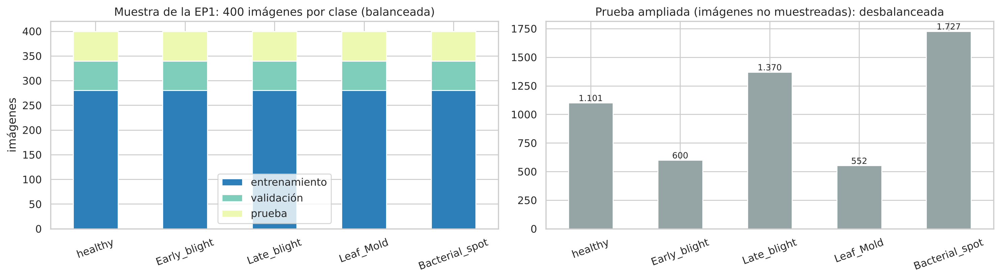

,entrenamiento,validación,prueba,prueba ampliada
healthy,280,60,60,1101
Early_blight,280,60,60,600
Late_blight,280,60,60,1370
Leaf_Mold,280,60,60,552
Bacterial_spot,280,60,60,1727
TOTAL,1400,300,300,5350


In [18]:
reparto = resumen_particion(datos)
reparto

**Lectura.** La muestra de la EP1 está perfectamente balanceada (280 / 60 / 60 imágenes por clase), así que el accuracy es interpretable y la línea base al azar es 20 %. La prueba ampliada tiene **5.350 imágenes** y está desbalanceada (de 552 en Leaf_Mold a 1.727 en Bacterial_spot); por eso ahí se reportan métricas **macro**, que pesan igual a cada clase. De las 5.579 imágenes no muestreadas se excluyeron 229: 220 eran **otras fotos de una hoja que ya está en la muestra** (la misma hoja fotografiada otro día o desde otro ángulo), 7 eran duplicados exactos y 2 tenían una posible etiqueta errónea. Sin ese filtro, la prueba ampliada habría inflado los resultados.

#### 4.2.2 Control de calidad: corruptas, duplicados, hojas repetidas y etiquetas dudosas

Imágenes corruptas                         :

 0
Modos de color                             : {'RGB': 2000}
Resoluciones                               : {'256x256': 2000}
Grupos de duplicados exactos en la muestra : 4 (8 archivos; subconjuntos: ['train'])
Hojas fotografiadas más de una vez         : 38 (85 fotos)
  de ellas, repartidas entre subconjuntos  : 16
Imágenes de prueba cuya hoja está en train : 7 de 300
Etiquetas dudosas dentro de la muestra     : 1


Figura guardada: ep3_02_etiquetas_dudosas.png


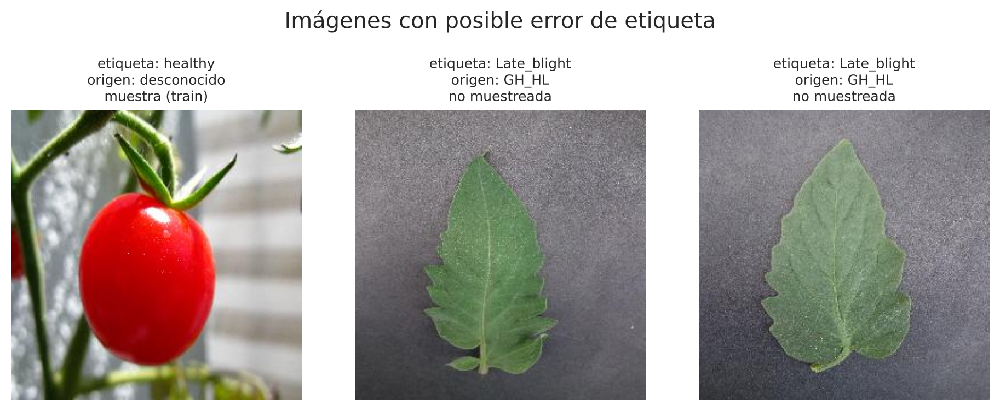


Hojas fotografiadas más de una vez y repartidas entre subconjuntos:


,fotos,clase,subconjuntos
hoja,,,
GHLB_PS|1,4,Tomato_Late_blight,"test, train, val"
GHLB_PS|17,2,Tomato_Late_blight,"train, val"
GHLB_PS|2,5,Tomato_Late_blight,"test, train"
GHLB_PS|25,3,Tomato_Late_blight,"train, val"
GHLB_PS|39,2,Tomato_Late_blight,"test, train"
GHLB|114,2,Tomato_Late_blight,"train, val"
GHLB|2,2,Tomato_Late_blight,"test, train"
GHLB|23,3,Tomato_Late_blight,"train, val"
GHLB|3,2,Tomato_Late_blight,"train, val"


In [19]:
calidad = control_calidad(datos)
if len(calidad["hojas_cruzadas"]):
    print("\nHojas fotografiadas más de una vez y repartidas entre subconjuntos:")
    display(calidad["hojas_cruzadas"])

**Lectura.**

- **Formato:** no hay imágenes corruptas y todas son RGB de 256×256. No hubo que descartar ni convertir nada.
- **Duplicados exactos:** 4 pares de archivos con distinto nombre y el mismo contenido, todos dentro de entrenamiento. No filtran información a la prueba, pero esas imágenes pesan el doble al entrenar.
- **La misma hoja en varios subconjuntos:** las sesiones `GH_HL` (sanas) y `GHLB*` (Late_blight) numeran cada hoja (`Leaf 1 Day 7`, `Leaf 1 Day 18`...). Hay 38 hojas con más de una foto, 16 de ellas repartidas entre subconjuntos, y **7 imágenes de prueba tienen una "hermana" en entrenamiento**. La EP1 particionó por imagen y no por hoja. Es una fuga pequeña (7 de 300, 2,3 %) y su efecto se mide en 9.3(c).
- **Etiquetas dudosas:** dentro del **entrenamiento** hay una foto de un **tomate (el fruto, en la planta)** etiquetada como `healthy`; su nombre no sigue el formato de PlantVillage (parece venir de internet). Fuera de la muestra hay **dos hojas sin lesiones, con el código de sesión de las sanas (`GH_HL`), guardadas en la carpeta Late_blight**. Las dos últimas se excluyen de la prueba ampliada. El fruto se mantiene para no alterar la partición de la EP1 (es 1 de 1.400) y queda documentado como mejora pendiente.

**Implicancia:** PlantVillage tiene ruido de etiqueta y fotos repetidas. Una partición por hoja y una limpieza de etiquetas serían el primer paso de una próxima versión.

#### 4.2.3 Origen de captura y color de fondo

El nombre de cada archivo de PlantVillage trae un prefijo que identifica la **sesión de captura** (por ejemplo `RS_Erly.B 8378.JPG`, `GHLB2 Leaf 8665.JPG`). Si cada clase viene de sesiones distintas, la clase queda mezclada con el lugar, la cámara y el fondo de la foto. Ese es un **sesgo de confusión**: un modelo puede acertar reconociendo la sesión en vez de la enfermedad.

Figura guardada: ep3_02_origen_fondo.png


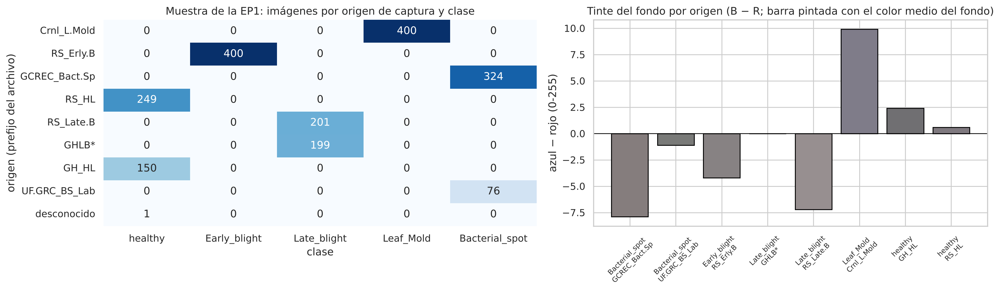

,clase,origen,imágenes,R,G,B,B − R
0,Bacterial_spot,GCREC_Bact.Sp,324,132.600006,124.500000,124.800003,-7.9
1,Bacterial_spot,UF.GRC_BS_Lab,76,121.199997,121.699997,120.099998,-1.1
2,Early_blight,RS_Erly.B,400,135.100006,129.699997,131.000000,-4.2
3,Late_blight,GHLB*,199,97.900002,94.900002,97.900002,0.0
4,Late_blight,RS_Late.B,201,151.500000,142.699997,144.300003,-7.2
5,Leaf_Mold,Crnl_L.Mold,400,127.400002,124.300003,137.300003,9.9
6,healthy,GH_HL,150,111.599998,111.099998,114.000000,2.4
7,healthy,RS_HL,249,126.500000,121.300003,127.099998,0.6


In [20]:
origen = analizar_origen(datos)
display(origen["fondo"])

Figura guardada: ep3_02_ejemplos_origen.png


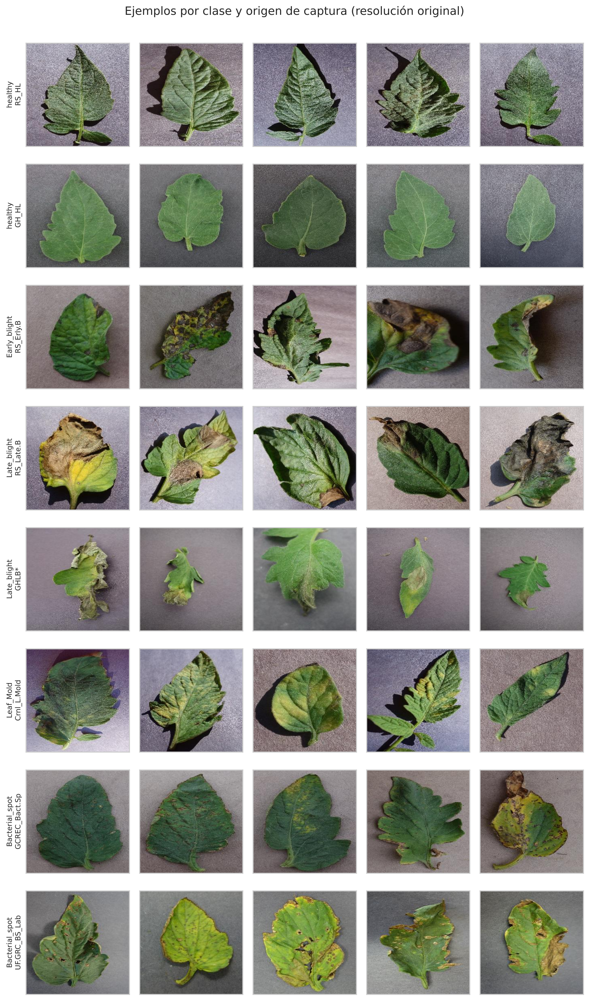

In [21]:
ejemplos_por_origen(datos)

**Lectura: el hallazgo más importante del análisis de datos.**

- **Cada clase viene de sus propias sesiones de captura y ninguna sesión aparece en dos clases.** Early_blight es 100 % `RS_Erly.B`, Leaf_Mold es 100 % `Crnl_L.Mold`, Bacterial_spot se reparte entre `GCREC_Bact.Sp` (81 %) y `UF.GRC_BS_Lab` (19 %), Late_blight entre `RS_Late.B` y `GHLB*` (50 % cada una) y healthy entre `RS_HL` (62 %) y `GH_HL` (38 %).
- Esto significa que la clase está **confundida con la sesión**. Un modelo que reconozca la sesión (fondo, iluminación, cámara) ya acierta buena parte de la clase sin mirar la enfermedad. Es el **sesgo de captura** documentado para PlantVillage: Noyan (2022) entrenó un modelo con solo 8 píxeles del fondo y obtuvo 49 % de accuracy en 38 clases, frente a 2,6 % al azar.
- **El fondo lo delata:** la sesión de Leaf_Mold (`Crnl`) tiene el fondo más azulado (B − R = +9,9), mientras que `GCREC`, `RS_Late.B` y `RS_Erly.B` son más cálidos (−4 a −8). Las sesiones `GHLB*` usan fondos más oscuros (R ≈ 98, frente a 112–152 en las demás). En la figura de ejemplos se nota a simple vista.
- **El grupo "RS" es la excepción útil:** `RS_HL`, `RS_Erly.B` y `RS_Late.B` comparten prefijo y fondos parecidos (probablemente el mismo lugar de captura). Entre esas tres clases el fondo no sirve para distinguir, y la red tiene que mirar la hoja. Es donde deberían concentrarse los errores.

#### 4.2.4 ¿El origen ya afectaba a los modelos de la EP1 y la EP2?

Antes de optimizar se revisa si el sesgo se refleja en los resultados oficiales: el recall de cada clase se separa por origen de captura, usando las predicciones guardadas de la EP1 y la EP2 sobre la misma prueba (intervalos de confianza de Wilson al 95 %).

In [22]:
def rendimiento_por_origen(df, predicciones, min_n=10):
    """Recall de cada clase separado por origen de captura, con IC 95 % de Wilson."""
    df = df.reset_index(drop=True)
    filas = []
    for (clase, org), g in df.groupby(["label", "origen"]):
        if len(g) < min_n:
            continue
        fila = {"clase": clase.replace("Tomato_", ""), "origen": org, "n": len(g)}
        for nombre, pred in predicciones.items():
            ok = np.asarray(pred)[g.index.to_numpy()] == g["label_id"].to_numpy()
            lo, hi = wilson(int(ok.sum()), len(g))
            fila[nombre] = float(ok.mean())
            fila[f"IC95 {nombre}"] = f"[{lo:.2f}; {hi:.2f}]"
        filas.append(fila)
    return pd.DataFrame(filas)


def brecha_entre_origenes(tabla, modelo):
    """KPI de sesgo: mayor diferencia de recall entre orígenes de una misma clase."""
    g = tabla.groupby("clase")[modelo].agg(["max", "min", "count"])
    g = g[g["count"] >= 2]
    return (g["max"] - g["min"]).rename(modelo)


PRED_PREVIAS_TEST = {}
for nombre, archivo in (("MLP EP1", "predicciones_test.csv"), ("CNN EP2", "predicciones_test_cnn.csv")):
    serie = pd.read_csv(ARTEFACTOS_DIR / archivo).set_index("path")["predicho"].map(LABEL_TO_ID)
    PRED_PREVIAS_TEST[nombre] = datos["test"]["path_rel"].map(serie).to_numpy(dtype=int)

origen_previos = rendimiento_por_origen(datos["test"], PRED_PREVIAS_TEST)
display(origen_previos.round(3))
print("\nMayor diferencia de recall entre orígenes de una misma clase (prueba oficial):")
display(pd.concat([brecha_entre_origenes(origen_previos, n) for n in PRED_PREVIAS_TEST], axis=1).round(3))

,clase,origen,n,MLP EP1,IC95 MLP EP1,CNN EP2,IC95 CNN EP2
0,Bacterial_spot,GCREC_Bact.Sp,50,0.960,[0.87; 0.99],0.980,[0.90; 1.00]
1,Bacterial_spot,UF.GRC_BS_Lab,10,0.700,[0.40; 0.89],0.700,[0.40; 0.89]
2,Early_blight,RS_Erly.B,60,0.617,[0.49; 0.73],0.950,[0.86; 0.98]
3,Late_blight,GHLB*,23,0.870,[0.68; 0.95],1.000,[0.86; 1.00]
4,Late_blight,RS_Late.B,37,0.595,[0.43; 0.74],0.622,[0.46; 0.76]
5,Leaf_Mold,Crnl_L.Mold,60,0.883,[0.78; 0.94],0.900,[0.80; 0.95]
6,healthy,GH_HL,19,1.000,[0.83; 1.00],1.000,[0.83; 1.00]
7,healthy,RS_HL,41,1.000,[0.91; 1.00],1.000,[0.91; 1.00]



Mayor diferencia de recall entre orígenes de una misma clase (prueba oficial):


,MLP EP1,CNN EP2
clase,,
Bacterial_spot,0.260,0.280
Late_blight,0.275,0.378
healthy,0.000,0.000


**Lectura.** El sesgo ya estaba presente en los resultados oficiales, aunque no se había medido:

- **Los 14 errores de la CNN de la EP2 en Late_blight vienen todos de la sesión `RS_Late.B`** (recall 0,62), mientras que las Late_blight del invernadero (`GHLB*`) se reconocen al 100 %. Las `RS_Late.B` se confunden con Early_blight, que es 100 % de la sesión RS: mismo fondo y misma luz. Con fondo distinto la clase es fácil; con el mismo fondo, la red tiene dificultades para separar los tizones.
- En Bacterial_spot, la sesión minoritaria `UF.GRC_BS_Lab` (19 % de la clase) tiene recall 0,70, frente a 0,98 de `GCREC`. Es un **subgrupo minoritario peor atendido**, el patrón típico de sesgo por representación.
- La diferencia entre orígenes llega a 0,38 en la CNN de la EP2 y a 0,28 en el MLP, muy por encima del KPI de 0,15. Pero con 10 a 60 imágenes por subgrupo los intervalos de confianza son anchos (por ejemplo, [0,40; 0,89] para `UF.GRC`). Por eso en 9.3 se repite el análisis con la prueba ampliada, que tiene cientos de imágenes por subgrupo.

Esto orienta la optimización: además de buscar más F1, hay que probar técnicas que le quiten valor al fondo (aumento de color, sección 7) y auditar si funcionan (sección 9).

### 4.3 Preprocesamiento

train  X=(1400, 64, 64, 3)  rango=[0.00, 1.00]  media=0.430  Y one-hot=(1400, 5)
val    X=(300, 64, 64, 3)  rango=[0.00, 1.00]  media=0.432  Y one-hot=(300, 5)


test   X=(300, 64, 64, 3)  rango=[0.00, 0.99]  media=0.436  Y one-hot=(300, 5)


Figura guardada: ep3_03_aumento.png


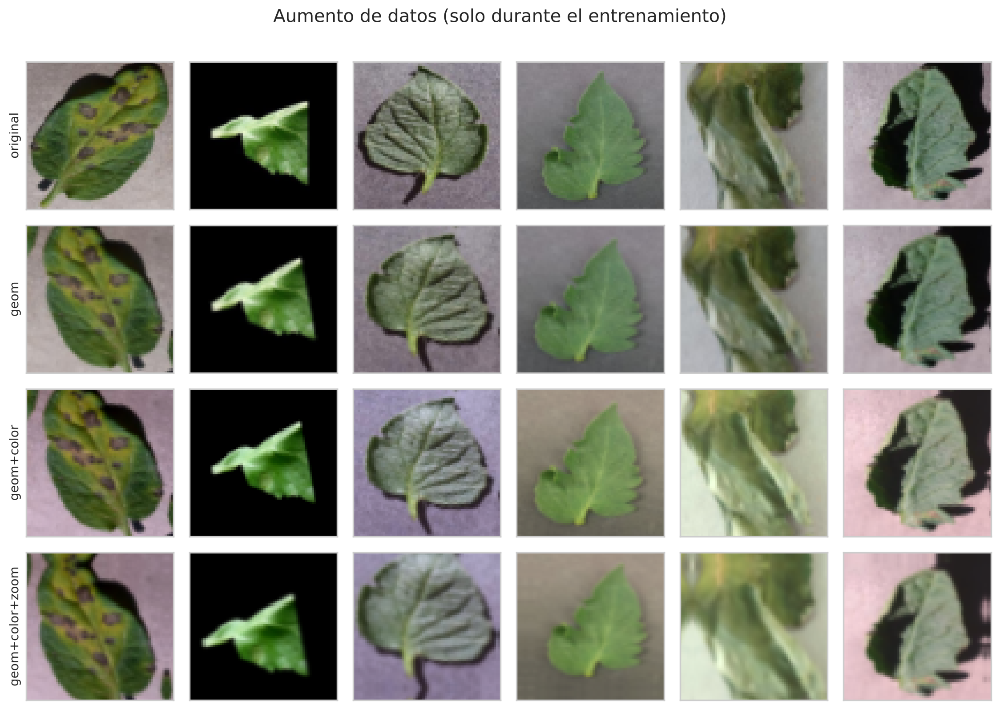

In [23]:
T = preprocesar(datos)
mostrar_aumento(T)

**Lectura.** Los tensores quedan en [0, 1] sin valores faltantes, con la misma forma y escala que en la EP1 y la EP2. En la figura, `geom` solo gira o refleja la hoja; `geom+color` además cambia la luz y el **tinte** (el fondo pasa de gris a algo más cálido o más frío), y `geom+color+zoom` también mueve el encuadre. Ninguna transformación cambia la clase: una hoja con tizón sigue teniendo tizón si la foto es más clara o está desplazada. Por eso no se usan transformaciones que sí podrían alterar la evidencia, como cambios fuertes de tono (el amarillo de Leaf_Mold o el café de los tizones son síntomas) o el espejo vertical, que no aporta en hojas fotografiadas desde arriba.

---

## 5. Líneas base: los modelos de la EP1 y la EP2

Antes de optimizar se verifica la trazabilidad: (1) los modelos guardados de la EP1 y la EP2 reproducen sus resultados oficiales sobre esta misma prueba, y (2) `construir_modelo()` con `CONFIG_BASE` genera exactamente esas arquitecturas. Las configuraciones base son el punto de partida de toda la optimización.

In [24]:
MODELOS_PREVIOS = {"MLP EP1": keras.models.load_model(ARTEFACTOS_DIR / "mlp_plantvillage.keras"),
                   "CNN EP2": keras.models.load_model(ARTEFACTOS_DIR / "cnn_plantvillage.keras")}
filas = []
for nombre, m in MODELOS_PREVIOS.items():
    ev_v = evaluar_metricas(m, T["X_val"], T["y_val"])["metricas"]
    ev_t = evaluar_metricas(m, T["X_test"], T["y_test"])["metricas"]
    filas.append({"modelo": nombre, "parámetros": m.count_params(), "accuracy val": ev_v["accuracy"],
                  "F1 val": ev_v["f1"], "accuracy prueba": ev_t["accuracy"], "F1 prueba": ev_t["f1"]})
tabla_previos = pd.DataFrame(filas).set_index("modelo")
display(tabla_previos.round(4))
assert abs(tabla_previos.loc["MLP EP1", "accuracy prueba"] - 0.8233) < 0.005
assert abs(tabla_previos.loc["CNN EP2", "accuracy prueba"] - 0.9100) < 0.005
print("Los modelos guardados reproducen los resultados oficiales de la EP1 (82,33 %) y la EP2 (91,00 %) ✓\n")

for tipo, previo in (("MLP", "MLP EP1"), ("CNN", "CNN EP2")):
    m = construir_modelo(**CONFIG_BASE[tipo])
    assert m.count_params() == MODELOS_PREVIOS[previo].count_params()
    print(f"construir_modelo('{tipo}', base) → {m.count_params():,} parámetros = {previo} ✓")

,parámetros,accuracy val,F1 val,accuracy prueba,F1 prueba
modelo,,,,,
MLP EP1,3181061,0.8633,0.8627,0.8233,0.8192
CNN EP2,1143493,0.9267,0.9270,0.9100,0.9105


Los modelos guardados reproducen los resultados oficiales de la EP1 (82,33 %) y la EP2 (91,00 %) ✓

construir_modelo('MLP', base) → 3,181,061 parámetros = MLP EP1 ✓
construir_modelo('CNN', base) → 1,143,493 parámetros = CNN EP2 ✓


---

## 6. Regularización: ¿cuánto aporta cada técnica?

**Diseño (ablación).** Se parte del modelo base regularizado y se **quita una técnica a la vez**, manteniendo todo lo demás igual. Al final se quita todo ("sin regularización"). Si quitar una técnica empeora la validación o agranda la brecha, esa técnica estaba ayudando a generalizar. Se aplica el mismo diseño al MLP y a la CNN.

| Técnica | Cómo regulariza |
|---|---|
| Dropout | Apaga neuronas al azar en cada paso: la red no puede depender de unas pocas conexiones. |
| BatchNormalization | Normaliza las activaciones de cada lote; estabiliza y agrega un poco de ruido (efecto regularizador leve). |
| Aumento de datos | Muestra variaciones de cada imagen: más diversidad sin fotos nuevas. |
| EarlyStopping | Detiene el entrenamiento cuando la validación deja de mejorar y restaura la mejor época. |
| L2 (solo MLP base) | Penaliza los pesos grandes: soluciones más suaves. |

La tabla incluye también la comparación de cuatro configuraciones de la Actividad 3.4 (MLP y CNN, con y sin regularización).

In [25]:
ABLACION = {}
for tipo in ("MLP", "CNN"):
    tabla, res, _ = optimizar_modelo(configuraciones_ablacion(tipo), T, titulo=f"ablación {tipo}")
    ABLACION[tipo] = {"tabla": tabla, "res": res}

[ 1/7] ablación MLP Base regularizada          semilla 1102 → F1 val 0.882 · acc val 0.883 · brecha +0.095 · 60 ép. ·    83 s (caché)


[ 2/7] ablación MLP − Dropout                  semilla 1102 → F1 val 0.869 · acc val 0.870 · brecha +0.116 · 38 ép. ·    49 s (caché)


[ 3/7] ablación MLP − BatchNorm                semilla 1102 → F1 val 0.370 · acc val 0.443 · brecha +0.002 · 60 ép. ·    75 s (caché)


[ 4/7] ablación MLP − Aumento de datos         semilla 1102 → F1 val 0.781 · acc val 0.780 · brecha +0.196 · 20 ép. ·    23 s (caché)


[ 5/7] ablación MLP − EarlyStopping            semilla 1102 → F1 val 0.865 · acc val 0.867 · brecha +0.104 · 60 ép. ·    81 s (caché)


[ 6/7] ablación MLP − L2                       semilla 1102 → F1 val 0.871 · acc val 0.870 · brecha +0.106 · 58 ép. ·    71 s (caché)


... (3 outputs left out)

[ 3/6] ablación CNN − BatchNorm                semilla 1102 → F1 val 0.924 · acc val 0.923 · brecha +0.063 · 36 ép. ·   115 s (caché)


[ 4/6] ablación CNN − Aumento de datos         semilla 1102 → F1 val 0.917 · acc val 0.917 · brecha +0.075 · 32 ép. ·   148 s (caché)


[ 5/6] ablación CNN − EarlyStopping            semilla 1102 → F1 val 0.902 · acc val 0.903 · brecha +0.067 · 60 ép. ·   282 s (caché)


[ 6/6] ablación CNN Sin regularización         semilla 1102 → F1 val 0.897 · acc val 0.897 · brecha +0.103 · 60 ép. ·   143 s (caché)


In [26]:
COLS_ABL = ["configuración", "parámetros", "épocas", "época modelo", "acc_train", "acc_val", "f1_val",
            "auc_val", "loss_val", "ece_val", "brecha", "tiempo_s"]
for tipo in ("MLP", "CNN"):
    print(f"\n{tipo} — ablación (métricas de VALIDACIÓN; brecha = acc. entrenamiento en inferencia − acc. validación)")
    display(ABLACION[tipo]["tabla"][COLS_ABL].round(4))

cuatro = pd.concat([ABLACION[t]["tabla"].assign(modelo=t) for t in ("MLP", "CNN")])
cuatro = cuatro[cuatro["configuración"].isin(["Sin regularización", "Base regularizada"])].copy()
cuatro.insert(0, "Actividad 3.4", cuatro["modelo"] + cuatro["configuración"].map(
    {"Sin regularización": " · sin regularización", "Base regularizada": " · regularizado"}))
print("\nComparación de las cuatro configuraciones de la Actividad 3.4")
display(cuatro[["Actividad 3.4", "parámetros", "épocas", "acc_train", "acc_val", "f1_val", "loss_val", "brecha"]]
        .round(4).reset_index(drop=True))


MLP — ablación (métricas de VALIDACIÓN; brecha = acc. entrenamiento en inferencia − acc. validación)


,configuración,parámetros,épocas,época modelo,acc_train,acc_val,f1_val,auc_val,loss_val,ece_val,brecha,tiempo_s
0,Base regularizada,3181061,60,56,0.9786,0.8833,0.8819,0.9806,0.3629,0.0494,0.0952,82.8244
1,− Dropout,3181061,38,30,0.9857,0.8700,0.8686,0.9769,0.3971,0.0394,0.1157,48.7649
2,− BatchNorm,3179525,60,59,0.4457,0.4433,0.3699,0.7364,1.3252,0.1049,0.0024,75.3019
3,− Aumento de datos,3181061,20,12,0.9764,0.7800,0.7811,0.9465,0.6058,0.0358,0.1964,23.4599
4,− EarlyStopping,3181061,60,60,0.9707,0.8667,0.8645,0.9782,0.3832,0.0292,0.1040,81.3848
5,− L2,3181061,58,50,0.9757,0.8700,0.8708,0.9789,0.3670,0.0298,0.1057,70.7404
6,Sin regularización,3179525,60,60,0.9507,0.7867,0.7848,0.9506,0.5973,0.0589,0.1640,49.7316



CNN — ablación (métricas de VALIDACIÓN; brecha = acc. entrenamiento en inferencia − acc. validación)


,configuración,parámetros,épocas,época modelo,acc_train,acc_val,f1_val,auc_val,loss_val,ece_val,brecha,tiempo_s
0,Base regularizada,1143493,48,40,0.9786,0.9100,0.9101,0.9909,0.2309,0.0414,0.0686,234.7250
1,− Dropout,1143493,20,12,0.9607,0.8933,0.8921,0.9861,0.2989,0.0426,0.0674,98.0577
2,− BatchNorm,1142597,36,28,0.9864,0.9233,0.9244,0.9958,0.2078,0.0317,0.0631,114.5390
3,− Aumento de datos,1143493,32,24,0.9921,0.9167,0.9169,0.9901,0.2584,0.0376,0.0755,148.4507
4,− EarlyStopping,1143493,60,60,0.9707,0.9033,0.9021,0.9911,0.2513,0.0386,0.0674,281.7547
5,Sin regularización,1142597,60,60,1.0000,0.8967,0.8967,0.9847,0.3995,0.0582,0.1033,143.2148



Comparación de las cuatro configuraciones de la Actividad 3.4


,Actividad 3.4,parámetros,épocas,acc_train,acc_val,f1_val,loss_val,brecha
0,MLP · regularizado,3181061,60,0.9786,0.8833,0.8819,0.3629,0.0952
1,MLP · sin regularización,3179525,60,0.9507,0.7867,0.7848,0.5973,0.1640
2,CNN · regularizado,1143493,48,0.9786,0.9100,0.9101,0.2309,0.0686
3,CNN · sin regularización,1142597,60,1.0000,0.8967,0.8967,0.3995,0.1033


Figura guardada: ep3_06_ablacion.png


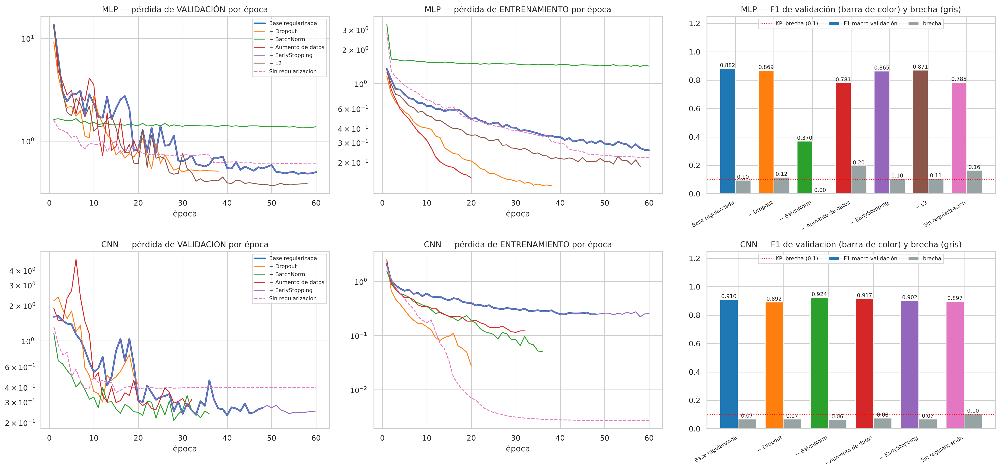

In [27]:
def graficar_ablacion(archivo="ep3_06_ablacion.png"):
    """Curvas de validación y entrenamiento por variante + F1 y brecha de cada una."""
    nombres = list(dict.fromkeys(list(configuraciones_ablacion("MLP")) + list(configuraciones_ablacion("CNN"))))
    paleta = dict(zip(nombres, sns.color_palette("tab10", len(nombres))))
    fig, axes = plt.subplots(2, 3, figsize=(21, 10))
    for r, tipo in enumerate(("MLP", "CNN")):
        tabla, res = ABLACION[tipo]["tabla"], ABLACION[tipo]["res"]
        for nombre in tabla["configuración"]:
            h = historial_de(res[(nombre, SEED)])
            estilo = dict(color=paleta[nombre], lw=2.6 if nombre == "Base regularizada" else 1.3,
                          ls="--" if nombre == "Sin regularización" else "-")
            axes[r, 0].plot(h.index, h["val_loss"], label=nombre, **estilo)
            axes[r, 1].plot(h.index, h["loss"], label=nombre, **estilo)
        axes[r, 0].set_yscale("log"); axes[r, 1].set_yscale("log")
        axes[r, 0].set_title(f"{tipo} — pérdida de VALIDACIÓN por época")
        axes[r, 1].set_title(f"{tipo} — pérdida de ENTRENAMIENTO por época")
        axes[r, 0].legend(fontsize=8); axes[r, 0].set_xlabel("época"); axes[r, 1].set_xlabel("época")
        x = np.arange(len(tabla))
        axes[r, 2].bar(x - 0.2, tabla["f1_val"], 0.4, label="F1 macro validación",
                       color=[paleta[n] for n in tabla["configuración"]])
        axes[r, 2].bar(x + 0.2, tabla["brecha"], 0.4, label="brecha", color="#7f8c8d", alpha=0.8)
        for i, (f, b) in enumerate(zip(tabla["f1_val"], tabla["brecha"])):
            axes[r, 2].text(i - 0.2, f + 0.01, f"{f:.3f}", ha="center", fontsize=8)
            axes[r, 2].text(i + 0.2, max(b, 0) + 0.01, f"{b:.2f}", ha="center", fontsize=8)
        axes[r, 2].axhline(KPI_BRECHA, color="red", ls=":", lw=1, label=f"KPI brecha ({KPI_BRECHA})")
        axes[r, 2].set_xticks(x); axes[r, 2].set_xticklabels(tabla["configuración"], rotation=30, ha="right", fontsize=8)
        axes[r, 2].set_ylim(0, 1.25); axes[r, 2].legend(fontsize=8, loc="upper center", ncol=3)
        axes[r, 2].set_title(f"{tipo} — F1 de validación (barra de color) y brecha (gris)")
    plt.tight_layout(); save_fig(archivo); plt.show()


graficar_ablacion()

**Lectura de la ablación.** Todas las cifras son de validación con la semilla 1102. Con 300 imágenes, 1 pp equivale a 3 imágenes.

**MLP: la regularización es indispensable.**

| Se quita... | F1 val | Δ vs base | Brecha | Qué muestran las curvas |
|---|---|---|---|---|
| nada (base) | 0,882 | — | 0,095 | La pérdida de validación baja de forma irregular hasta la época 56. |
| Aumento de datos | 0,781 | **−10,1 pp** | **0,196** | La pérdida de entrenamiento cae en picada; EarlyStopping corta en la época 20 porque la validación ya empeoraba. **Memoriza.** |
| BatchNorm | 0,370 | −51,2 pp | 0,002 | La pérdida de entrenamiento queda plana en ~1,5: el MLP **no logra aprender** (underfitting). Con 12.288 entradas, sin normalizar las activaciones la optimización no avanza a esta tasa de aprendizaje. |
| Dropout | 0,869 | −1,3 pp | 0,116 | Converge antes (38 épocas) y la brecha sube. |
| L2 | 0,871 | −1,1 pp | 0,106 | Efecto pequeño, en la misma dirección. |
| EarlyStopping | 0,865 | −1,7 pp | 0,104 | La base nunca se detuvo (llegó al tope de 60); la única diferencia es que EarlyStopping restauró la época 56 en vez de la 60. |
| todo | 0,785 | −9,7 pp | **0,164** | Supera el límite de brecha de 0,15. |

**CNN: la arquitectura ya regulariza.**

| Se quita... | F1 val | Δ vs base | Brecha | Pérdida val | Qué muestran las curvas |
|---|---|---|---|---|---|
| nada (base) | 0,910 | — | 0,069 | 0,231 | Converge en la época 40 con picos de inestabilidad entre las épocas 13 y 19, como en la EP2. |
| Dropout | 0,892 | −1,8 pp | 0,067 | 0,299 | Sobreajusta antes: el mínimo llega en la época 12 y la validación empeora después. |
| BatchNorm | **0,924** | **+1,4 pp** | 0,063 | 0,208 | Curvas **más suaves**, sin los picos de la base. Coincide con la hipótesis de la EP2: la inestabilidad venía de BatchNorm con lotes chicos. |
| Aumento de datos | 0,917 | +0,7 pp | 0,076 | 0,258 | Igual F1, pero memoriza más (train 0,992) y la pérdida de validación empeora (menos confianza bien puesta). |
| EarlyStopping | 0,902 | −0,8 pp | 0,067 | 0,251 | Es la misma curva de la base, continuada hasta la época 60: después del mínimo la validación ya no mejora. EarlyStopping ahorra 12 épocas (~55 s) sin perder nada. |
| todo | 0,897 | −1,3 pp | 0,103 | **0,399** | Señal clásica de sobreajuste: la pérdida de entrenamiento cae a 0,003 (acierta el **100 %** del entrenamiento) mientras la de validación queda clavada en 0,4. Peor calibración (ECE 0,058). |

**Conclusiones de la ablación**

1. **La regularización pesa mucho más en el MLP (+9,7 pp) que en la CNN (+1,3 pp).** El MLP tiene 2.272 parámetros por imagen de entrenamiento y ninguna restricción espacial. En la CNN, compartir pesos entre posiciones ya es una forma de regularización de la arquitectura: **incluso la CNN sin ninguna regularización (0,897) supera al MLP regularizado (0,882)**.
2. **En el MLP, el aumento de datos es la técnica decisiva**, y BatchNorm es imprescindible para que el entrenamiento funcione.
3. **En la CNN, Dropout es la técnica con más efecto** (−1,8 pp al quitarlo). Quitar BatchNorm mejoró 1,4 pp con una sola semilla. Es una diferencia de ~4 imágenes, dentro del ruido, pero coincide con la inestabilidad observada. No se agregó al espacio de búsqueda de la sección 7 porque el plan se fijó **antes** de ver la ablación (cambiarlo después sería ajustar el experimento a los resultados). Queda como el primer experimento de la próxima iteración.
4. **Sin regularización, la brecha supera el KPI en ambos modelos** (0,164 y 0,103), y en la CNN la pérdida de validación casi se duplica. Que el F1 baje poco no significa que el modelo esté bien: acierta con confianzas peor calibradas.
5. El MLP base llegó al tope de 60 épocas sin que EarlyStopping se activara. Más épocas podrían ayudarle un poco, pero se mantiene el mismo tope para ambos modelos por comparabilidad.

---

## 7. Optimización de hiperparámetros

### 7.1 Plan de experimentación

La arquitectura general de cada modelo queda fija (MLP de la EP1, CNN de la EP2) y se optimizan sus hiperparámetros. Cada experimento responde a una hipótesis y **cambia un solo valor** respecto de la base:

| # | Hiperparámetro | Base | Valores probados | Hipótesis |
|---|---|---|---|---|
| E1 | `learning_rate` (ambos) | 0,001 | 0,0005 · 0,002 | Una tasa menor podría estabilizar la validación (la EP2 tuvo un colapso puntual en la época 18); una mayor podría converger antes, con riesgo de oscilar. |
| E2 | `batch_size` (ambos) | 32 | 16 · 64 | Lotes de 64 dan estadísticas de BatchNorm más estables; lotes de 16 agregan ruido al gradiente (regulariza, pero es más lento). |
| E3 | `dropout` (ambos) | 0,4 CNN · 0,3 MLP | 0,2 · 0,6 (CNN) · 0,2 · 0,5 (MLP) | Más Dropout debería reducir la brecha; demasiado puede llevar a underfitting. |
| E4 | `l2` (ambos) | 0 CNN · 1e-4 MLP | 1e-4 · 1e-3 (CNN) · 0 · 1e-3 (MLP) | Penalizar pesos grandes en la capa densa (91,7 % de los parámetros de la CNN) debería reducir la memorización. |
| E5 | `aumento` (ambos) | geom | geom+color · geom+color+zoom | Variar luz y tinte debería quitarle valor al color del fondo de cada sesión (atajo de Leaf_Mold) y mejorar la generalización. |
| E6 | `label_smoothing` (ambos) | 0 | 0,1 | Etiquetas suavizadas deberían reducir la sobreconfianza (mejor ECE) sin perder accuracy. |
| E7 | `neuronas` de la capa densa (CNN) | 128 | 64 · 256 | Con 1.400 imágenes, 64 neuronas podrían bastar y generalizar mejor; 256 duplican los parámetros. |
| E8 | `cabeza` (CNN) | Flatten | GlobalAveragePooling2D | La cabeza GAP baja los parámetros de 1,14 M a ~110 mil; debería reducir la brecha (propuesta de la EP2). |
| E9 | `capas` ocultas (MLP) | (256, 128) | (128, 64) · (512, 256) | La EP1 mostró que más neuronas no levantan el techo del MLP; se verifica con el protocolo de la EP3. |

**Estrategias de búsqueda**

1. **Un hiperparámetro a la vez (OFAT, *one factor at a time*):** es una búsqueda en grilla de una dimensión alrededor de la base. Aísla el efecto de cada hiperparámetro, como pide la pauta (experimentación controlada).
2. **Combinación OFAT:** se arma una configuración con todos los valores que mejoraron al menos 1 pp de F1 de validación sin superar el KPI de brecha. Supone que los efectos se suman, lo que no siempre ocurre.
3. **Random Search:** combinaciones al azar del espacio completo. Detecta **interacciones** que OFAT no ve. Una grilla completa no es viable: son 2.916 combinaciones para la CNN (≈ 5 días de CPU) y 1.458 para el MLP.
4. **Confirmación multi-semilla:** con 300 imágenes de validación, 1 imagen equivale a 0,33 pp y una diferencia de 1–2 pp puede ser azar. La base, la combinación OFAT y el mejor Random se reentrenan con **3 semillas**.

**Criterio de selección (fijado antes de ver los resultados):** gana el mejor F1 macro **medio** de validación. Las configuraciones a menos de 1 pp de la mejor se consideran empatadas, y entre ellas se elige la de **menor brecha** (mejor generalización) y, si persiste el empate, la de menos parámetros. La prueba no participa en ninguna decisión.

In [28]:
GRID_OFAT = {
    "CNN": {"learning_rate": [5e-4, 2e-3], "batch_size": [16, 64], "dropout": [0.2, 0.6],
            "neuronas": [64, 256], "cabeza": ["gap"], "l2": [1e-4, 1e-3],
            "aumento": ["geom+color", "geom+color+zoom"], "label_smoothing": [0.1]},
    "MLP": {"learning_rate": [5e-4, 2e-3], "batch_size": [16, 64], "capas": [(128, 64), (512, 256)],
            "dropout": [0.2, 0.5], "l2": [0.0, 1e-3], "aumento": ["geom+color", "geom+color+zoom"],
            "label_smoothing": [0.1]},
}
for tipo, grid in GRID_OFAT.items():
    n_ofat = 1 + sum(len(v) for v in grid.values())
    n_grid = int(np.prod([len(v) + 1 for v in grid.values()]))
    print(f"{tipo}: {n_ofat} experimentos OFAT (incluida la base) · grilla completa = {n_grid:,} combinaciones")

CNN: 15 experimentos OFAT (incluida la base) · grilla completa = 2,916 combinaciones
MLP: 14 experimentos OFAT (incluida la base) · grilla completa = 1,458 combinaciones


### 7.2 OFAT de la CNN

In [29]:
OFAT = {}
tipo = "CNN"
tabla, res, _ = optimizar_modelo(configuraciones_ofat(tipo, GRID_OFAT[tipo]), T, titulo="OFAT CNN")
efectos, adoptados = analizar_ofat(tabla, tipo, GRID_OFAT[tipo])
OFAT[tipo] = {"tabla": tabla, "res": res, "efectos": efectos, "adoptados": adoptados}

[ 1/15] OFAT CNN Base                       semilla 1102 → F1 val 0.910 · acc val 0.910 · brecha +0.069 · 48 ép. ·   235 s (caché)


[ 2/15] OFAT CNN learning_rate = 0.0005     semilla 1102 → F1 val 0.904 · acc val 0.903 · brecha +0.062 · 38 ép. ·   178 s (caché)


[ 3/15] OFAT CNN learning_rate = 0.002      semilla 1102 → F1 val 0.789 · acc val 0.793 · brecha +0.045 · 19 ép. ·    91 s (caché)


[ 4/15] OFAT CNN batch_size = 16            semilla 1102 → F1 val 0.896 · acc val 0.897 · brecha +0.072 · 41 ép. ·   203 s (caché)


[ 5/15] OFAT CNN batch_size = 64            semilla 1102 → F1 val 0.884 · acc val 0.887 · brecha +0.071 · 35 ép. ·   174 s (caché)


[ 6/15] OFAT CNN dropout = 0.2              semilla 1102 → F1 val 0.875 · acc val 0.877 · brecha +0.075 · 22 ép. ·   107 s (caché)


... (5 outputs left out)

[12/15] OFAT CNN l2 = 0.001                 semilla 1102 → F1 val 0.926 · acc val 0.927 · brecha +0.053 · 57 ép. ·   282 s (caché)


[13/15] OFAT CNN aumento = geom+color       semilla 1102 → F1 val 0.868 · acc val 0.870 · brecha +0.059 · 37 ép. ·   183 s (caché)


[14/15] OFAT CNN aumento = geom+color+zoom  semilla 1102 → F1 val 0.876 · acc val 0.880 · brecha +0.014 · 50 ép. ·   310 s (caché)


[15/15] OFAT CNN label_smoothing = 0.1      semilla 1102 → F1 val 0.910 · acc val 0.910 · brecha +0.057 · 40 ép. ·   193 s (caché)


Figura guardada: ep3_07_ofat_cnn.png


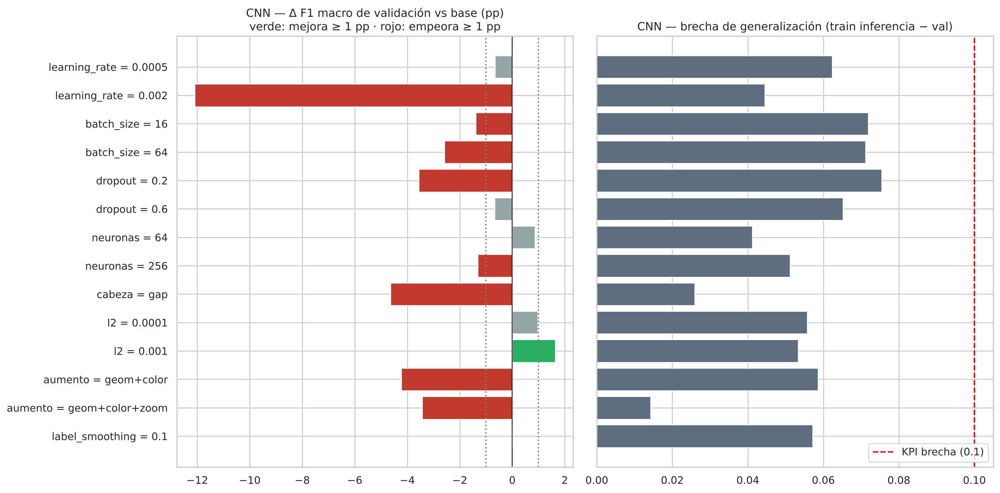

Base CNN: F1 val 0,9101 | brecha 0,0686


,hiperparámetro,valor base,valor probado,f1_val,Δ F1 vs base,brecha,Δ brecha,épocas,tiempo_s,se adopta
0,learning_rate,0.001,0.0005,0.9035,-0.0066,0.0624,-0.0062,38,177.7451,
1,learning_rate,0.001,0.002,0.7892,-0.1210,0.0445,-0.0240,19,91.1696,
2,batch_size,32,16,0.8962,-0.0139,0.0719,0.0033,41,203.1187,
3,batch_size,32,64,0.8843,-0.0258,0.0712,0.0026,35,173.5793,
4,dropout,0.4,0.2,0.8745,-0.0356,0.0755,0.0069,22,107.3570,
5,dropout,0.4,0.6,0.9035,-0.0067,0.0652,-0.0033,52,247.8479,
6,neuronas,128,64,0.9188,0.0086,0.0412,-0.0274,50,249.7431,
7,neuronas,128,256,0.8970,-0.0132,0.0512,-0.0174,24,121.7047,
8,cabeza,flatten,gap,0.8638,-0.0463,0.0260,-0.0426,33,151.7850,
9,l2,0,0.0001,0.9199,0.0098,0.0557,-0.0129,49,244.6798,


Valores adoptados (≥ 1 pp de mejora y brecha ≤ KPI): {'l2': 0.001}


In [30]:
graficar_ofat(OFAT["CNN"]["efectos"], "CNN", "ep3_07_ofat_cnn.png")
print("Base CNN: F1 val", es(OFAT["CNN"]["tabla"].iloc[0]["f1_val"]), "| brecha", es(OFAT["CNN"]["tabla"].iloc[0]["brecha"]))
display(OFAT["CNN"]["efectos"].round(4))
print("Valores adoptados (≥ 1 pp de mejora y brecha ≤ KPI):", OFAT["CNN"]["adoptados"] or "ninguno")

**Lectura: un hiperparámetro a la vez, CNN** (base: F1 val 0,910, brecha 0,069)

| Hipótesis (7.1) | Resultado | ¿Se cumple? |
|---|---|---|
| E1. Tasa menor estabiliza; mayor converge antes | 0,0005 → −0,7 pp. **0,002 → −12,1 pp**: la validación oscila y EarlyStopping corta en la época 19. | No. 0,001 ya era el punto estable (como en la EP1). |
| E2. Lote de 64 estabiliza BatchNorm | 16 → −1,4 pp; 64 → −2,6 pp | No. Lotes más grandes dan menos pasos de actualización por época y generalizan peor. |
| E3. Más Dropout reduce la brecha | 0,2 → **−3,6 pp** (sobreajusta en la época 14); 0,6 → −0,7 pp (mejor pérdida de validación, 0,224) | Parcialmente: el Dropout es necesario, pero subirlo a 0,6 no mejora el F1. |
| E4. L2 reduce la memorización de la capa densa | 1e-4 → +1,0 pp (la menor pérdida de validación, 0,188); **1e-3 → +1,6 pp** (0,927), brecha 0,053 | **Sí.** Es el único cambio que supera el umbral de 1 pp. |
| E5. Aumento de color quita valor al fondo | geom+color → **−4,2 pp**; +zoom → −3,4 pp (brecha casi nula, 0,014) | Baja el F1 de validación. Se analiza el porqué en 9.5. |
| E6. *Label smoothing* mejora la calibración | Mismo F1 (0,910), pero **ECE 0,107 frente a 0,041** | No. Con 5 clases y ε = 0,1 el modelo queda subconfiado: falla la calibración en la dirección contraria. |
| E7. 64 neuronas bastan | 64 → +0,9 pp (brecha 0,041); 256 → −1,3 pp | Tendencia a favor, pero bajo el umbral de 1 pp. |
| E8. GAP reduce la brecha | **−4,6 pp**, brecha 0,026, accuracy de entrenamiento 0,899 | La brecha baja, pero por **underfitting**: con 128 valores promediados se pierde la posición de la lesión y la cabeza queda corta. |

**Conclusión.** La CNN de la EP2 ya estaba cerca de un óptimo local: de 14 cambios, 10 empeoran. La única mejora clara es **L2 = 0,001**, que ataca justamente lo que la EP2 había señalado (la capa densa con el 91,7 % de los parámetros). Las hipótesis que no se cumplieron también son información útil: la EP2 había propuesto GAP y *label smoothing* como mejoras, y aquí los datos muestran que no funcionan en este problema.

### 7.3 OFAT del MLP

In [31]:
tipo = "MLP"
tabla, res, _ = optimizar_modelo(configuraciones_ofat(tipo, GRID_OFAT[tipo]), T, titulo="OFAT MLP")
efectos, adoptados = analizar_ofat(tabla, tipo, GRID_OFAT[tipo])
OFAT[tipo] = {"tabla": tabla, "res": res, "efectos": efectos, "adoptados": adoptados}

[ 1/14] OFAT MLP Base                       semilla 1102 → F1 val 0.882 · acc val 0.883 · brecha +0.095 · 60 ép. ·    83 s (caché)


[ 2/14] OFAT MLP learning_rate = 0.0005     semilla 1102 → F1 val 0.879 · acc val 0.880 · brecha +0.083 · 53 ép. ·    67 s (caché)


[ 3/14] OFAT MLP learning_rate = 0.002      semilla 1102 → F1 val 0.870 · acc val 0.870 · brecha +0.112 · 60 ép. ·    78 s (caché)


[ 4/14] OFAT MLP batch_size = 16            semilla 1102 → F1 val 0.849 · acc val 0.850 · brecha +0.088 · 41 ép. ·    91 s (caché)


[ 5/14] OFAT MLP batch_size = 64            semilla 1102 → F1 val 0.849 · acc val 0.850 · brecha +0.114 · 53 ép. ·    59 s (caché)


[ 6/14] OFAT MLP capas = (128, 64)          semilla 1102 → F1 val 0.834 · acc val 0.837 · brecha +0.105 · 51 ép. ·    57 s (caché)


... (4 outputs left out)

[11/14] OFAT MLP l2 = 0.001                 semilla 1102 → F1 val 0.846 · acc val 0.847 · brecha +0.103 · 43 ép. ·    54 s (caché)


[12/14] OFAT MLP aumento = geom+color       semilla 1102 → F1 val 0.828 · acc val 0.827 · brecha +0.101 · 52 ép. ·    69 s (caché)


[13/14] OFAT MLP aumento = geom+color+zoom  semilla 1102 → F1 val 0.798 · acc val 0.813 · brecha +0.048 · 60 ép. ·   136 s (caché)


[14/14] OFAT MLP label_smoothing = 0.1      semilla 1102 → F1 val 0.884 · acc val 0.883 · brecha +0.091 · 60 ép. ·    79 s (caché)


Figura guardada: ep3_07_ofat_mlp.png


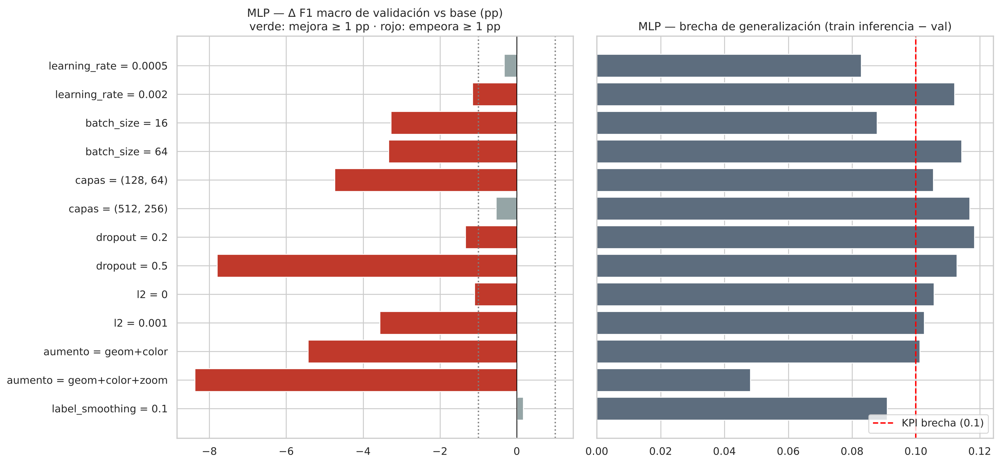

Base MLP: F1 val 0,8819 | brecha 0,0952


,hiperparámetro,valor base,valor probado,f1_val,Δ F1 vs base,brecha,Δ brecha,épocas,tiempo_s,se adopta
0,learning_rate,0.001,0.0005,0.8785,-0.0033,0.0829,-0.0124,53,66.9931,
1,learning_rate,0.001,0.002,0.8704,-0.0115,0.1121,0.0169,60,78.2129,
2,batch_size,32,16,0.8491,-0.0328,0.0879,-0.0074,41,90.7135,
3,batch_size,32,64,0.8485,-0.0334,0.1143,0.0190,53,58.8339,
4,capas,"(256, 128)","(128, 64)",0.8344,-0.0474,0.1055,0.0102,51,57.2014,
5,capas,"(256, 128)","(512, 256)",0.8765,-0.0054,0.1169,0.0217,60,136.1413,
6,dropout,0.3,0.2,0.8685,-0.0134,0.1183,0.0231,60,73.6041,
7,dropout,0.3,0.5,0.8039,-0.0780,0.1129,0.0176,59,74.8670,
8,l2,0.0001,0,0.8708,-0.0110,0.1057,0.0105,58,70.7404,
9,l2,0.0001,0.001,0.8462,-0.0357,0.1026,0.0074,43,53.7927,


Valores adoptados (≥ 1 pp de mejora y brecha ≤ KPI): ninguno


In [32]:
graficar_ofat(OFAT["MLP"]["efectos"], "MLP", "ep3_07_ofat_mlp.png")
print("Base MLP: F1 val", es(OFAT["MLP"]["tabla"].iloc[0]["f1_val"]), "| brecha", es(OFAT["MLP"]["tabla"].iloc[0]["brecha"]))
display(OFAT["MLP"]["efectos"].round(4))
print("Valores adoptados (≥ 1 pp de mejora y brecha ≤ KPI):", OFAT["MLP"]["adoptados"] or "ninguno")

**Lectura: un hiperparámetro a la vez, MLP** (base: F1 val 0,882, brecha 0,095)

- **Ningún cambio mejora al MLP de la EP1 por 1 pp o más.** El más cercano es *label smoothing* (+0,2 pp, dentro del ruido y con peor calibración: ECE 0,089 frente a 0,049).
- **Más neuronas no ayudan:** (512, 256) → −0,5 pp, con accuracy de entrenamiento 0,994 y la mayor brecha (0,117). El MLP más grande memoriza más y generaliza igual. (128, 64) → −4,8 pp: con menos capacidad, underfitting. Se repite lo de la EP1: **el techo del MLP es arquitectónico.**
- **El MLP es muy sensible a la regularización:** Dropout 0,5 → −7,8 pp y L2 = 1e-3 → −3,6 pp (demasiada penalización para una red sin estructura espacial). Quitar L2 → −1,1 pp. La configuración de la EP1 ya estaba en el punto de equilibrio.
- **Lote:** tanto 16 como 64 empeoran ~3,3 pp; 32 era el mejor valor.
- **El aumento de color afecta más al MLP que a la CNN** (−5,4 y −8,4 pp). Al MLP le cuesta más que a la CNN aprender a ignorar variaciones de color, porque cada píxel es una variable independiente.

**Conclusión.** La combinación OFAT del MLP es la misma configuración base, porque no hubo ningún valor que adoptar. El Random Search (7.5) revisa si alguna **combinación** de cambios funciona mejor que los cambios por separado.

### 7.4 Combinación de los valores que mejoraron

In [33]:
CONFIG_OFAT = {t: {**CONFIG_BASE[t], **OFAT[t]["adoptados"]} for t in ("MLP", "CNN")}
for t in ("MLP", "CNN"):
    print(f"{t} — combinación OFAT: {describir_cambios(CONFIG_OFAT[t], t)}")

MLP — combinación OFAT: (igual a la base)
CNN — combinación OFAT: l2=0.001


### 7.5 Random Search

Se muestrean al azar (semilla 1102) combinaciones del espacio completo: cada hiperparámetro toma su valor base o uno de los valores de la tabla 7.1. Se excluyen las configuraciones ya probadas.

In [34]:
RANDOM = {}
for tipo in ("CNN", "MLP"):
    previas = list(configuraciones_ofat(tipo, GRID_OFAT[tipo]).values()) + [CONFIG_OFAT[tipo]]
    cfgs = configuraciones_random(tipo, GRID_OFAT[tipo], N_RANDOM[tipo], excluir=previas)
    tabla, res, mejor = optimizar_modelo(cfgs, T, titulo=f"Random {tipo}")
    tabla.insert(1, "cambios respecto de la base", [describir_cambios(cfgs[n], tipo) for n in tabla["configuración"]])
    RANDOM[tipo] = {"tabla": tabla, "res": res, "cfgs": cfgs, "mejor": mejor}

[ 1/6] Random CNN R1                         semilla 1102 → F1 val 0.874 · acc val 0.877 · brecha +0.010 · 49 ép. ·   317 s (caché)


[ 2/6] Random CNN R2                         semilla 1102 → F1 val 0.880 · acc val 0.880 · brecha +0.030 · 46 ép. ·   239 s (caché)


[ 3/6] Random CNN R3                         semilla 1102 → F1 val 0.877 · acc val 0.880 · brecha +0.018 · 29 ép. ·   146 s (caché)


[ 4/6] Random CNN R4                         semilla 1102 → F1 val 0.886 · acc val 0.887 · brecha +0.026 · 59 ép. ·   314 s (caché)


[ 5/6] Random CNN R5                         semilla 1102 → F1 val 0.110 · acc val 0.223 · brecha -0.010 · 33 ép. ·   178 s (caché)


[ 6/6] Random CNN R6                         semilla 1102 → F1 val 0.718 · acc val 0.767 · brecha +0.018 · 60 ép. ·   284 s (caché)


... (4 outputs left out)

[ 5/8] Random MLP R5                         semilla 1102 → F1 val 0.857 · acc val 0.860 · brecha +0.088 · 60 ép. ·   144 s (caché)


[ 6/8] Random MLP R6                         semilla 1102 → F1 val 0.851 · acc val 0.850 · brecha +0.132 · 60 ép. ·   138 s (caché)


[ 7/8] Random MLP R7                         semilla 1102 → F1 val 0.805 · acc val 0.810 · brecha +0.089 · 60 ép. ·    67 s (caché)


[ 8/8] Random MLP R8                         semilla 1102 → F1 val 0.787 · acc val 0.790 · brecha +0.081 · 60 ép. ·    69 s (caché)



CNN — Random Search (mejor por F1 de validación: R4)


,configuración,cambios respecto de la base,parámetros,épocas,f1_val,acc_val,brecha,tiempo_s
0,R1,"neuronas=64, l2=0.0001, aumento=geom+color+zoom, learning_rate=0.0005, batch_size=16",618821,49,0.8737,0.8767,0.0098,317.0958
1,R2,"cabeza=gap, neuronas=256, dropout=0.2, l2=0.0001, aumento=geom+color, label_smoothing=0.1, batch_size=64",128453,46,0.8796,0.8800,0.0300,239.4391
2,R3,"dropout=0.2, aumento=geom+color+zoom",1143493,29,0.8767,0.8800,0.0179,146.0984
3,R4,"neuronas=256, dropout=0.6, l2=0.001, aumento=geom+color+zoom, batch_size=64",2192837,59,0.8863,0.8867,0.0262,314.2700
4,R5,"neuronas=64, dropout=0.6, l2=0.0001, batch_size=16",618821,33,0.1098,0.2233,-0.0105,177.8000
5,R6,"neuronas=64, l2=0.001, learning_rate=0.002, label_smoothing=0.1, batch_size=64",618821,60,0.7185,0.7667,0.0183,284.0399



MLP — Random Search (mejor por F1 de validación: R5)


,configuración,cambios respecto de la base,parámetros,épocas,f1_val,acc_val,brecha,tiempo_s
0,R1,"dropout=0.2, aumento=geom+color, learning_rate=0.0005, label_smoothing=0.1, batch_size=16",3181061,33,0.8289,0.8300,0.0493,75.2629
1,R2,"dropout=0.5, l2=0, aumento=geom+color+zoom, learning_rate=0.002, label_smoothing=0.1",3181061,52,0.7910,0.8033,0.0160,102.2948
2,R3,"capas=(128, 64), aumento=geom+color, learning_rate=0.0005, batch_size=16",1582341,39,0.7892,0.7967,0.0505,57.6012
3,R4,"capas=(512, 256), dropout=0.5, aumento=geom+color+zoom, learning_rate=0.002",6427653,55,0.7980,0.8067,0.0326,155.0087
4,R5,"capas=(512, 256), dropout=0.5, l2=0.001, learning_rate=0.002, label_smoothing=0.1",6427653,60,0.8566,0.8600,0.0879,144.2543
5,R6,"dropout=0.2, learning_rate=0.002, batch_size=16",3181061,60,0.8507,0.8500,0.1321,138.3970
6,R7,"capas=(128, 64), dropout=0.5, l2=0.001, learning_rate=0.002, label_smoothing=0.1",1582341,60,0.8054,0.8100,0.0893,67.2158
7,R8,"dropout=0.5, l2=0.001, aumento=geom+color, learning_rate=0.002, batch_size=64",3181061,60,0.7867,0.7900,0.0814,68.6949


Figura guardada: ep3_07_busqueda.png


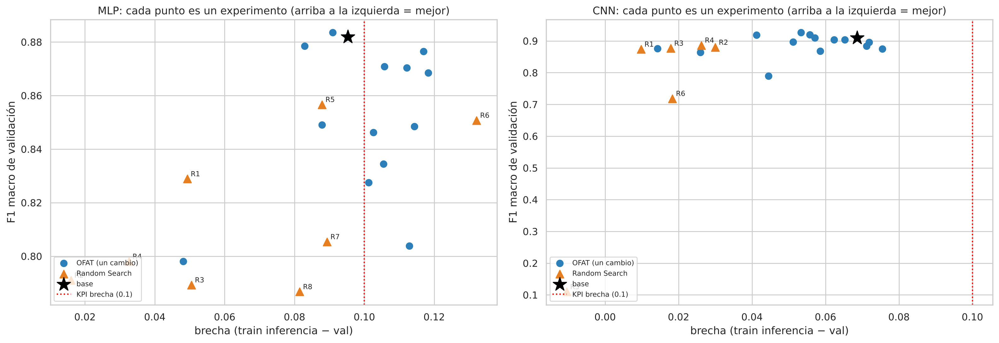

In [35]:
for tipo in ("CNN", "MLP"):
    print(f"\n{tipo} — Random Search (mejor por F1 de validación: {RANDOM[tipo]['mejor']})")
    display(RANDOM[tipo]["tabla"][["configuración", "cambios respecto de la base", "parámetros", "épocas",
                                   "f1_val", "acc_val", "brecha", "tiempo_s"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
for ax, tipo in zip(axes, ("MLP", "CNN")):
    o, r = OFAT[tipo]["tabla"], RANDOM[tipo]["tabla"]
    ax.scatter(o["brecha"], o["f1_val"], s=55, label="OFAT (un cambio)", color="#2c7fb8")
    ax.scatter(r["brecha"], r["f1_val"], s=80, marker="^", label="Random Search", color="#e67e22")
    b = o[o["configuración"] == "Base"].iloc[0]
    ax.scatter([b["brecha"]], [b["f1_val"]], s=260, marker="*", color="black", label="base", zorder=5)
    for _, f in r.iterrows():
        ax.annotate(f["configuración"], (f["brecha"], f["f1_val"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.axvline(KPI_BRECHA, color="red", ls=":", label=f"KPI brecha ({KPI_BRECHA})")
    ax.set_xlabel("brecha (train inferencia − val)"); ax.set_ylabel("F1 macro de validación")
    ax.set_title(f"{tipo}: cada punto es un experimento (arriba a la izquierda = mejor)")
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); save_fig("ep3_07_busqueda.png"); plt.show()

**Lectura del Random Search.** Ninguna de las 14 combinaciones al azar superó a su base. La mejor de la CNN (R4: 256 neuronas, Dropout 0,6, L2 1e-3, aumento con color y zoom, lote 64) llegó a 0,886 (−2,4 pp); la mejor del MLP (R5: capas (512, 256), Dropout 0,5, L2 1e-3, tasa 0,002 y *label smoothing*) a 0,857 (−2,5 pp).

- Hay **interacciones negativas** que OFAT no podía anticipar. La CNN R5 (64 neuronas + Dropout 0,6 + lote 16 + L2 1e-4) **no aprendió** (F1 0,11): por separado cada cambio era inofensivo, pero juntos dejaron una cabeza demasiado chica y demasiado regularizada. La R6 (tasa 0,002 + lote 64) se desestabilizó igual que la tasa alta en OFAT.
- En el gráfico, los puntos del Random Search tienen **menor brecha** pero **menor F1**: casi todos combinan varias formas de regularización (y la mayoría, aumento de color). Más regularización reduce la brecha, pero desde cierto punto ya no compensa con mejor validación.
- Que un Random Search de este tamaño no mejore es un resultado esperable cuando la base ya está bien ajustada: el espacio tiene 2.916 combinaciones y solo se probaron 6 (CNN) y 8 (MLP). Su papel aquí es verificar que no exista una combinación mucho mejor cerca de la base, no recorrer el espacio completo.

### 7.6 Confirmación con tres semillas y selección

Una sola ejecución puede tener suerte. Los candidatos (base, combinación OFAT y mejor Random) se reentrenan con las semillas 1102, 1103 y 1104, y se aplica la regla de selección fijada en 7.1. Los pesos de estos entrenamientos se guardan: son los modelos que se evalúan en la sección 8.

In [36]:
CONFIRMACION, SELECCION = {}, {}
for tipo in ("MLP", "CNN"):
    cand = {"Base": CONFIG_BASE[tipo]}
    if CONFIG_OFAT[tipo] != CONFIG_BASE[tipo]:
        cand["OFAT combinada"] = CONFIG_OFAT[tipo]
    mejor_r = RANDOM[tipo]["mejor"]
    if RANDOM[tipo]["cfgs"][mejor_r] not in cand.values():
        cand[f"Random {mejor_r}"] = RANDOM[tipo]["cfgs"][mejor_r]
    tabla, res, _ = optimizar_modelo(cand, T, semillas=SEMILLAS, guardar_pesos=True, titulo=f"confirmación {tipo}")
    resumen = tabla.groupby("configuración", sort=False).agg(
        f1_media=("f1_val", "mean"), f1_std=("f1_val", "std"), acc_media=("acc_val", "mean"),
        auc_media=("auc_val", "mean"), loss_media=("loss_val", "mean"), ece_media=("ece_val", "mean"),
        brecha_media=("brecha", "mean"), épocas_media=("épocas", "mean"), tiempo_medio=("tiempo_s", "mean"),
        s_por_época=("s_por_época", "mean"), parámetros=("parámetros", "first"))
    resumen.insert(0, "cambios", [describir_cambios(cand[n], tipo) for n in resumen.index])
    elegido, empatadas = seleccionar(resumen)
    CONFIRMACION[tipo] = {"tabla": tabla, "resumen": resumen, "candidatos": cand,
                          "elegido": elegido, "empatadas": empatadas}
    SELECCION[tipo] = cand[elegido]

[ 1/6] confirmación MLP Base                       semilla 1102 → F1 val 0.882 · acc val 0.883 · brecha +0.095 · 60 ép. ·    83 s (caché)


[ 2/6] confirmación MLP Base                       semilla 1103 → F1 val 0.849 · acc val 0.850 · brecha +0.114 · 53 ép. ·    74 s (caché)


[ 3/6] confirmación MLP Base                       semilla 1104 → F1 val 0.873 · acc val 0.873 · brecha +0.098 · 52 ép. ·    72 s (caché)


[ 4/6] confirmación MLP Random R5                  semilla 1102 → F1 val 0.857 · acc val 0.860 · brecha +0.088 · 60 ép. ·   144 s (caché)


[ 5/6] confirmación MLP Random R5                  semilla 1103 → F1 val 0.854 · acc val 0.853 · brecha +0.096 · 60 ép. ·   140 s (caché)


[ 6/6] confirmación MLP Random R5                  semilla 1104 → F1 val 0.851 · acc val 0.853 · brecha +0.099 · 60 ép. ·   146 s (caché)


... (5 outputs left out)

[ 6/9] confirmación CNN OFAT combinada             semilla 1104 → F1 val 0.914 · acc val 0.913 · brecha +0.075 · 50 ép. ·   251 s (caché)


[ 7/9] confirmación CNN Random R4                  semilla 1102 → F1 val 0.886 · acc val 0.887 · brecha +0.026 · 59 ép. ·   314 s (caché)


[ 8/9] confirmación CNN Random R4                  semilla 1103 → F1 val 0.872 · acc val 0.870 · brecha -0.002 · 51 ép. ·   296 s (caché)


[ 9/9] confirmación CNN Random R4                  semilla 1104 → F1 val 0.793 · acc val 0.797 · brecha +0.042 · 49 ép. ·   265 s (caché)



MLP — media de 3 semillas en VALIDACIÓN


,cambios,f1_media,f1_std,acc_media,auc_media,loss_media,ece_media,brecha_media,épocas_media,tiempo_medio,s_por_época,parámetros
configuración,,,,,,,,,,,,
Base,(igual a la base),0.8680,0.0168,0.8689,0.9809,0.3494,0.0486,0.1023,55.0,76.4654,1.3907,3181061
Random R5,"capas=(512, 256), dropout=0.5, l2=0.001, learning_rate=0.002, label_smoothing=0.1",0.8537,0.0030,0.8556,0.9743,0.4685,0.1118,0.0942,60.0,143.2667,2.3878,6427653


Empatadas (a < 1 pp del mejor F1 medio): ['Base']
→ Configuración elegida: Base ((igual a la base))

CNN — media de 3 semillas en VALIDACIÓN


,cambios,f1_media,f1_std,acc_media,auc_media,loss_media,ece_media,brecha_media,épocas_media,tiempo_medio,s_por_época,parámetros
configuración,,,,,,,,,,,,
Base,(igual a la base),0.9132,0.0034,0.9133,0.9910,0.2322,0.0362,0.0552,43.3333,214.1867,4.9477,1143493
OFAT combinada,l2=0.001,0.9172,0.0081,0.9178,0.9916,0.2241,0.0396,0.0610,53.0000,274.6557,5.1878,1143493
Random R4,"neuronas=256, dropout=0.6, l2=0.001, aumento=geom+color+zoom, batch_size=64",0.8504,0.0503,0.8511,0.9808,0.3804,0.0623,0.0220,53.0000,291.9017,5.5157,2192837


Empatadas (a < 1 pp del mejor F1 medio): ['Base', 'OFAT combinada']
→ Configuración elegida: Base ((igual a la base))


Figura guardada: ep3_07_confirmacion.png


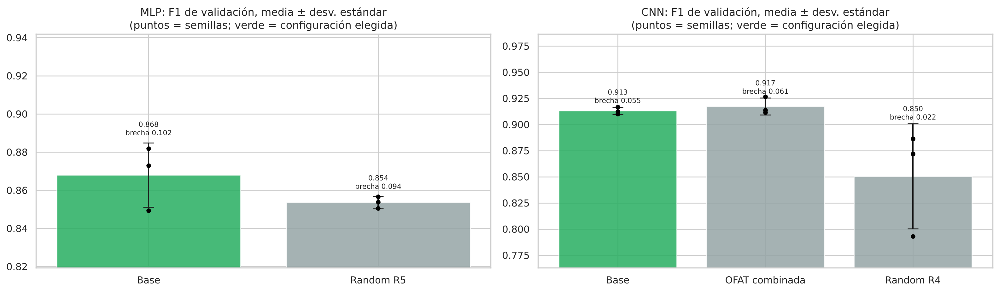

In [37]:
for tipo in ("MLP", "CNN"):
    c = CONFIRMACION[tipo]
    print(f"\n{tipo} — media de 3 semillas en VALIDACIÓN")
    display(c["resumen"].round(4))
    print(f"Empatadas (a < 1 pp del mejor F1 medio): {c['empatadas']}")
    print(f"→ Configuración elegida: {c['elegido']} ({describir_cambios(SELECCION[tipo], tipo)})")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, tipo in zip(axes, ("MLP", "CNN")):
    tab, resu = CONFIRMACION[tipo]["tabla"], CONFIRMACION[tipo]["resumen"]
    x = np.arange(len(resu))
    colores = ["#27ae60" if n == CONFIRMACION[tipo]["elegido"] else "#95a5a6" for n in resu.index]
    ax.bar(x, resu["f1_media"], yerr=resu["f1_std"], capsize=6, color=colores, alpha=0.85)
    for i, n in enumerate(resu.index):
        pts = tab.loc[tab["configuración"] == n, "f1_val"]
        ax.scatter([i] * len(pts), pts, color="black", s=18, zorder=5)
        ax.text(i, resu.loc[n, "f1_media"] + resu.loc[n, "f1_std"] + 0.004,
                f"{resu.loc[n, 'f1_media']:.3f}\nbrecha {resu.loc[n, 'brecha_media']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(resu.index)
    ax.set_ylim(max(0, tab["f1_val"].min() - 0.03), min(1.04, tab["f1_val"].max() + 0.06))
    ax.set_title(f"{tipo}: F1 de validación, media ± desv. estándar\n(puntos = semillas; verde = configuración elegida)")
plt.tight_layout(); save_fig("ep3_07_confirmacion.png"); plt.show()

**Lectura: la confirmación con tres semillas cambió la decisión.**

| Modelo | Candidata | F1 val (3 semillas) | Brecha media | Decisión |
|---|---|---|---|---|
| MLP | Base (EP1) | **0,868 ± 0,017** | 0,102 | **Elegida** |
| MLP | Random R5 | 0,854 ± 0,003 | 0,094 | −1,4 pp, fuera del empate |
| CNN | Base (EP2) | 0,913 ± 0,003 | **0,055** | **Elegida** (empate, menor brecha) |
| CNN | OFAT combinada (L2 = 0,001) | **0,917 ± 0,008** | 0,061 | Empatada: solo +0,4 pp |
| CNN | Random R4 | 0,850 ± 0,050 | 0,022 | Inestable: de 0,89 a 0,79 según la semilla |

- **La mejora de L2 era en buena parte suerte de la semilla.** Con la semilla 1102 daba +1,6 pp; con las semillas 1103 y 1104 la ventaja casi desaparece y la media queda en +0,4 pp (≈ 1 imagen de 300). Según la regla fijada en 7.1 está empatada con la base, y gana la base por menor brecha (0,055 frente a 0,061) y menor variabilidad (desv. 0,003 frente a 0,008). **Sin esta confirmación habríamos adoptado una "mejora" que no existe.**
- **R4 muestra por qué una sola ejecución engaña:** con la semilla 1104 cae a 0,79. Una configuración tan sensible a la inicialización no es confiable aunque una de sus ejecuciones se vea bien.
- **La CNN es más estable que el MLP:** desviación estándar 0,003 frente a 0,017. El KPI de estabilidad (≤ 0,02) lo cumplen ambos.

**Resultado de la optimización:** después de 63 experimentos distintos, las configuraciones de la EP1 y la EP2 **se confirman como las mejores** del espacio explorado. No es un resultado vacío. La optimización entrega evidencia de que la configuración elegida es un óptimo local robusto, cuantifica cuánto pesa cada hiperparámetro (la tasa de aprendizaje y el Dropout son los más sensibles) y descarta con datos las propuestas de la EP2 (GAP, *label smoothing*) que parecían mejoras. Los modelos "EP3" de las secciones siguientes son esas configuraciones **reentrenadas con el protocolo de la EP3** (semilla 1102, en este equipo).

---

## 8. Evaluación final en la prueba

Recién aquí se usa la prueba. Cada modelo elegido pasa por `main()`, el pipeline completo de la Actividad 3.4 (los pesos se leen de la confirmación de 7.6, semilla 1102), y luego se comparan los cuatro modelos del proyecto: MLP EP1, CNN EP2, MLP EP3 y CNN EP3.

### 8.1 MLP optimizado

PIPELINE INTEGRADO — MLP optimizado (EP3)
Configuración: (igual a la base) | semilla 1102


Etapas 4-6: 3,181,061 parámetros · 60 épocas · 83 s (pesos leídos de la caché)



Etapa 7a — curvas de aprendizaje


Figura guardada: ep3_08_mlp_curvas.png


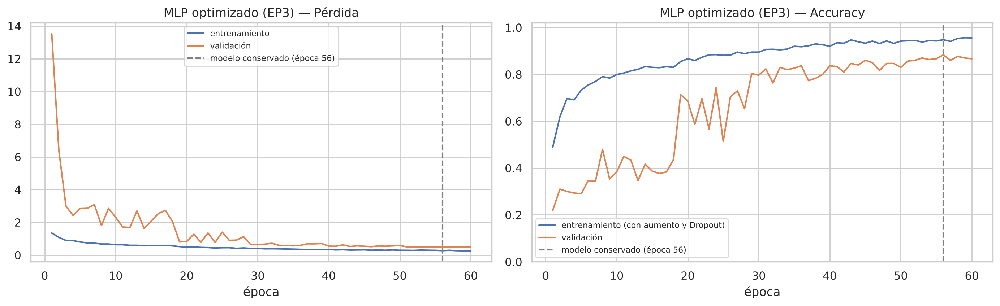

Épocas ejecutadas: 60 | modelo conservado: época 56
Accuracy entrenamiento (inferencia): 0.9786 | validación: 0.8833 | brecha: +0.0952
val_loss final / mínima: 1.04×
Diagnóstico: sobreajuste leve: brecha entre 0,05 y 0,10

Etapa 7b — métricas en la PRUEBA oficial (300 imágenes)


,MLP optimizado (EP3) (prueba)
Accuracy,0.8233
Precision (macro),0.8233
Recall (macro),0.8233
F1-score (macro),0.8215
"ROC-AUC (OvR, macro)",0.9697
Recall clases enfermas,0.7792
Enfermas → sana,6.0000
ECE (calibración),0.0675
Pérdida (crossentropy),0.4649


Figura guardada: ep3_08_mlp_matriz_confusion.png


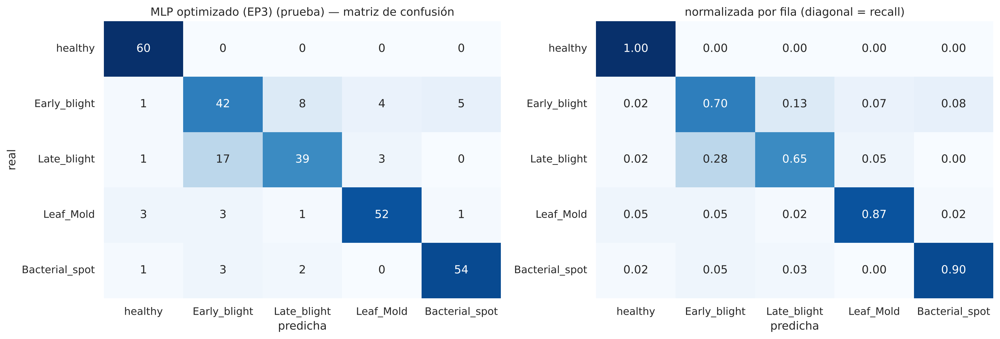

,precision,recall,f1-score,support
healthy,0.9091,1.0000,0.9524,60
Early_blight,0.6462,0.7000,0.6720,60
Late_blight,0.7800,0.6500,0.7091,60
Leaf_Mold,0.8814,0.8667,0.8739,60
Bacterial_spot,0.9000,0.9000,0.9000,60



Etapa 8 — auditoría XAI (una hoja bien clasificada por clase)


Figura guardada: ep3_08_mlp_xai.png


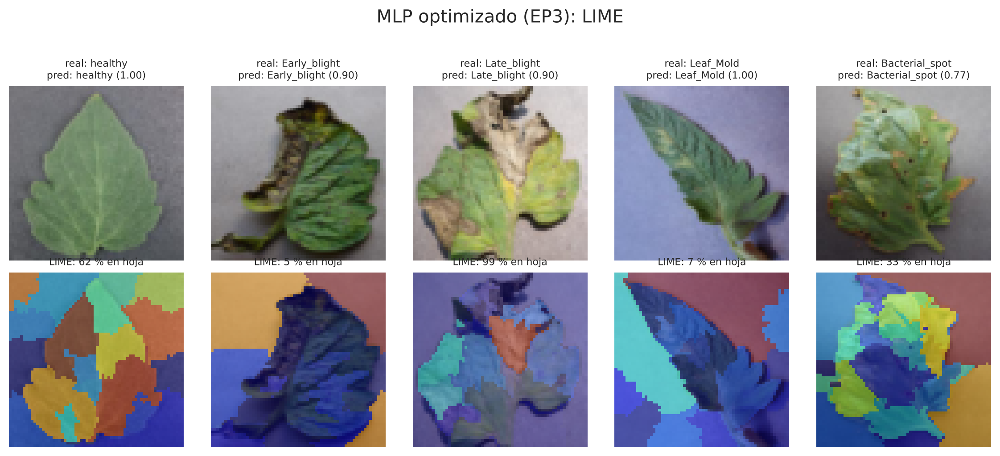


Etapa 9 — reporte


,MLP optimizado (EP3)
Modelo,MLP optimizado (EP3)
Conjunto,prueba
Parámetros,3181061
Épocas,60
Época conservada,56
Tiempo (s),82.8
s/época,1.38
Accuracy,0.823333
Precision,0.82332
Recall,0.823333


In [38]:
FINAL = {}
FINAL["MLP"] = main("MLP", SELECCION["MLP"], datos=datos, T=T, nombre="MLP optimizado (EP3)")

### 8.2 CNN optimizada

PIPELINE INTEGRADO — CNN optimizada (EP3)
Configuración: (igual a la base) | semilla 1102
Etapas 4-6: 1,143,493 parámetros · 48 épocas · 235 s (pesos leídos de la caché)



Etapa 7a — curvas de aprendizaje


Figura guardada: ep3_08_cnn_curvas.png


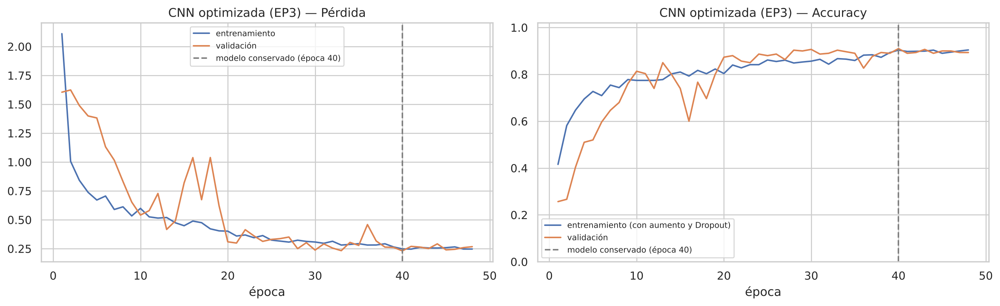

Épocas ejecutadas: 48 | modelo conservado: época 40
Accuracy entrenamiento (inferencia): 0.9786 | validación: 0.9100 | brecha: +0.0686
val_loss final / mínima: 1.16×
Diagnóstico: sobreajuste leve: brecha entre 0,05 y 0,10



Etapa 7b — métricas en la PRUEBA oficial (300 imágenes)


,CNN optimizada (EP3) (prueba)
Accuracy,0.9067
Precision (macro),0.9186
Recall (macro),0.9067
F1-score (macro),0.9067
"ROC-AUC (OvR, macro)",0.9880
Recall clases enfermas,0.8833
Enfermas → sana,3.0000
ECE (calibración),0.0351
Pérdida (crossentropy),0.2934


Figura guardada: ep3_08_cnn_matriz_confusion.png


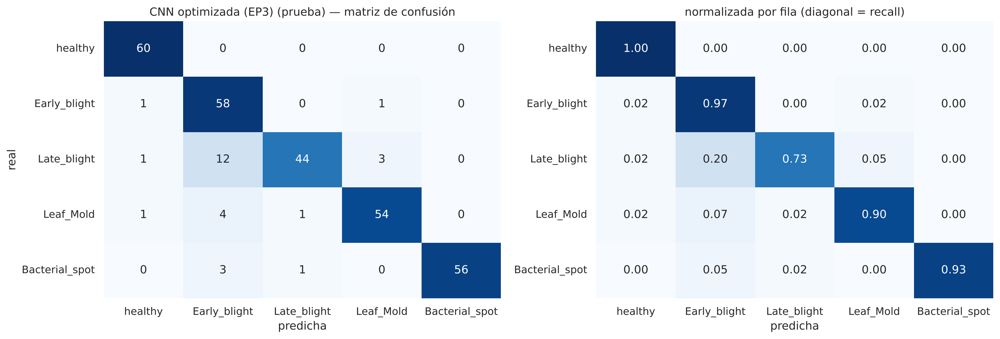

,precision,recall,f1-score,support
healthy,0.9524,1.0000,0.9756,60
Early_blight,0.7532,0.9667,0.8467,60
Late_blight,0.9565,0.7333,0.8302,60
Leaf_Mold,0.9310,0.9000,0.9153,60
Bacterial_spot,1.0000,0.9333,0.9655,60



Etapa 8 — auditoría XAI (una hoja bien clasificada por clase)


Figura guardada: ep3_08_cnn_xai.png


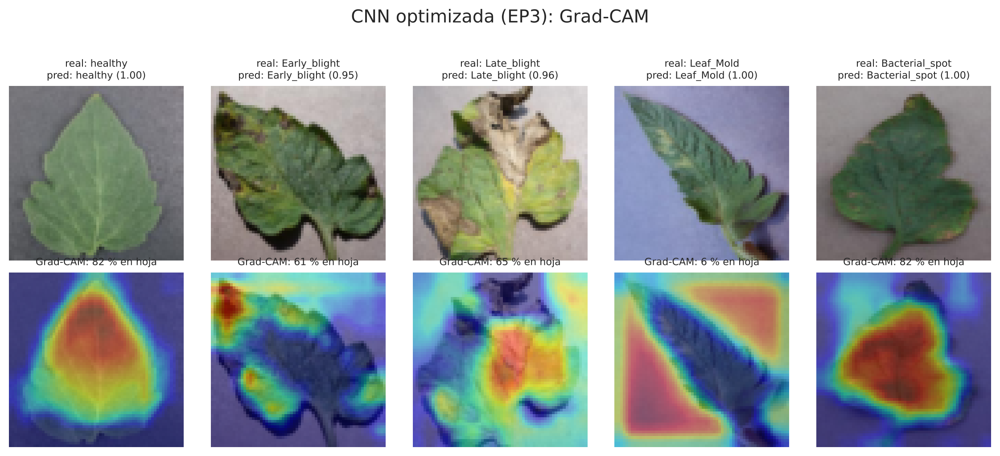


Etapa 9 — reporte


,CNN optimizada (EP3)
Modelo,CNN optimizada (EP3)
Conjunto,prueba
Parámetros,1143493
Épocas,48
Época conservada,40
Tiempo (s),234.7
s/época,4.89
Accuracy,0.906667
Precision,0.918637
Recall,0.906667


In [39]:
FINAL["CNN"] = main("CNN", SELECCION["CNN"], datos=datos, T=T, nombre="CNN optimizada (EP3)")

**Lectura del pipeline completo para los dos modelos finales** (prueba oficial, 300 imágenes)

| | MLP EP3 | CNN EP3 |
|---|---|---|
| Accuracy / F1 macro | 0,823 / 0,821 | **0,907 / 0,907** |
| ROC-AUC macro | 0,970 | **0,988** |
| Recall de enfermas | 0,779 | **0,883** |
| Enfermas → sana (de 240) | 6 | **3** |
| ECE | 0,068 | **0,035** |
| Brecha (train − prueba) | 0,155 | **0,072** |
| Diagnóstico de las curvas | sobreajuste leve en validación (0,095), que en la prueba sube a 0,155 | sobreajuste leve (0,069 en validación, 0,072 en la prueba) |

- **Curvas.** El MLP corre las 60 épocas y su pérdida de validación oscila mucho en las primeras 30 (BatchNorm con 12.288 entradas). La CNN converge en la época 40 y EarlyStopping la detiene en la 48. Ninguno muestra la firma del sobreajuste fuerte (pérdida de validación que sube mientras la de entrenamiento baja), porque EarlyStopping conserva el mínimo.
- **Matrices de confusión.** Ambos reconocen todas las hojas sanas (recall 1,00). El MLP se reparte los errores entre Early_blight y Late_blight (F1 0,67 y 0,71). La CNN concentra casi todos sus errores en **Late_blight → Early_blight** (recall de Late_blight 0,73; precision de Early_blight 0,75): la misma confusión de la EP2.
- **ROC-AUC alto con accuracy menor.** La CNN tiene AUC 0,988: casi siempre da más probabilidad a la clase correcta que a las demás, aunque no siempre la suficiente para ganar. Por eso los errores se concentran en un par de clases y no son aleatorios.
- **XAI de `main()`.** Con una hoja por clase, LIME (MLP) pone en promedio el 41 % de la evidencia sobre la hoja y Grad-CAM (CNN) el 59 %. Con 5 imágenes es solo una muestra; la sección 9 lo mide con todas las imágenes de prueba.

### 8.3 ¿Depende el resultado de la semilla?

Se evalúan en la prueba los tres modelos entrenados con cada semilla (los de la confirmación). Una desviación estándar baja indica que el resultado no es fruto del azar de la inicialización.

In [40]:
filas = []
for tipo in ("MLP", "CNN"):
    for s in SEMILLAS:
        m, _, _ = obtener_modelo(SELECCION[tipo], T, s, nombre=f"{tipo}_s{s}")
        ev = evaluar_metricas(m, T["X_test"], T["y_test"])["metricas"]
        filas.append({"modelo": f"{tipo} EP3", "semilla": s, "accuracy": ev["accuracy"], "F1": ev["f1"],
                      "ROC AUC": ev["roc_auc"], "recall enfermas": ev["recall_enfermas"],
                      "enfermas → sana": ev["enfermas_a_sana"], "ECE": ev["ece"]})
        del m
SEMILLAS_TEST = pd.DataFrame(filas)
display(SEMILLAS_TEST.round(4))
display(SEMILLAS_TEST.drop(columns="semilla").groupby("modelo").agg(["mean", "std"]).round(4))

,modelo,semilla,accuracy,F1,ROC AUC,recall enfermas,enfermas → sana,ECE
0,MLP EP3,1102,0.8233,0.8215,0.9697,0.7792,6,0.0675
1,MLP EP3,1103,0.8267,0.8255,0.9655,0.7917,4,0.0399
2,MLP EP3,1104,0.8367,0.8362,0.9681,0.7958,6,0.0510
3,CNN EP3,1102,0.9067,0.9067,0.9880,0.8833,3,0.0351
4,CNN EP3,1103,0.8767,0.8773,0.9883,0.8458,5,0.0513
5,CNN EP3,1104,0.9000,0.8997,0.9875,0.8750,7,0.0455


accuracy              F1         ROC AUC         recall enfermas         enfermas → sana             ECE        
            mean     std    mean     std    mean     std            mean     std            mean     std    mean     std
modelo                                                                                                                  
CNN EP3   0.8944  0.0158  0.8946  0.0153  0.9879  0.0004          0.8681  0.0197          5.0000  2.0000  0.0440  0.0082
MLP EP3   0.8289  0.0069  0.8277  0.0076  0.9678  0.0021          0.7889  0.0087          5.3333  1.1547  0.0528  0.0139

### 8.4 Los cuatro modelos del proyecto en la prueba oficial

modelo,MLP EP1,CNN EP2,MLP EP3,CNN EP3
Accuracy,8.233000e-01,9.100000e-01,8.233000e-01,9.067000e-01
Precision macro,8.176000e-01,9.172000e-01,8.233000e-01,9.186000e-01
Recall macro,8.233000e-01,9.100000e-01,8.233000e-01,9.067000e-01
F1 macro,8.192000e-01,9.105000e-01,8.215000e-01,9.067000e-01
ROC-AUC macro,9.643000e-01,9.892000e-01,9.697000e-01,9.880000e-01
Recall enfermas,7.792000e-01,8.875000e-01,7.792000e-01,8.833000e-01
Enfermas → sana (de 240),6.000000e+00,1.000000e+00,6.000000e+00,3.000000e+00
ECE,5.360000e-02,4.560000e-02,6.750000e-02,3.510000e-02
Accuracy entrenamiento (inferencia),9.714000e-01,9.714000e-01,9.786000e-01,9.786000e-01
Brecha (train − prueba),1.481000e-01,6.140000e-02,1.552000e-01,7.190000e-02


Figura guardada: ep3_08_comparacion_prueba.png


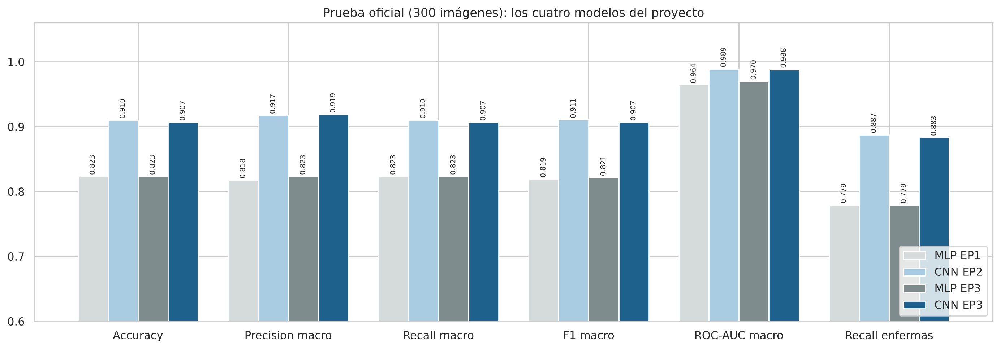

In [41]:
MODELOS = {"MLP EP1": MODELOS_PREVIOS["MLP EP1"], "CNN EP2": MODELOS_PREVIOS["CNN EP2"],
           "MLP EP3": FINAL["MLP"]["modelo"], "CNN EP3": FINAL["CNN"]["modelo"]}
EV_TEST = {n: evaluar_metricas(m, T["X_test"], T["y_test"]) for n, m in MODELOS.items()}
ACC_TRAIN = {n: accuracy_score(T["y_train"], m.predict(T["X_train"], verbose=0, batch_size=256).argmax(1))
             for n, m in MODELOS.items()}
# Tiempos medidos en ESTE equipo: EP1/EP2 = su configuración reentrenada en la ablación ("Base regularizada");
# EP3 = media de las 3 semillas de la configuración elegida.
TIEMPOS = {}
for t, previo in (("MLP", "MLP EP1"), ("CNN", "CNN EP2")):
    b = ABLACION[t]["tabla"].query("configuración == 'Base regularizada'").iloc[0]
    TIEMPOS[previo] = (b["épocas"], b["tiempo_s"], b["s_por_época"])
    e = CONFIRMACION[t]["resumen"].loc[CONFIRMACION[t]["elegido"]]
    TIEMPOS[f"{t} EP3"] = (e["épocas_media"], e["tiempo_medio"], e["s_por_época"])

filas = []
for n, m in MODELOS.items():
    k = EV_TEST[n]["metricas"]
    filas.append({"modelo": n, "Accuracy": k["accuracy"], "Precision macro": k["precision"],
                  "Recall macro": k["recall"], "F1 macro": k["f1"], "ROC-AUC macro": k["roc_auc"],
                  "Recall enfermas": k["recall_enfermas"], "Enfermas → sana (de 240)": k["enfermas_a_sana"],
                  "ECE": k["ece"], "Accuracy entrenamiento (inferencia)": ACC_TRAIN[n],
                  "Brecha (train − prueba)": ACC_TRAIN[n] - k["accuracy"], "Parámetros": m.count_params(),
                  "Épocas (este equipo)": TIEMPOS[n][0], "Tiempo de entrenamiento (s)": TIEMPOS[n][1],
                  "s por época": TIEMPOS[n][2]})
COMPARACION_TEST = pd.DataFrame(filas).set_index("modelo")
display(COMPARACION_TEST.T.round(4))

nombres_m = ["Accuracy", "Precision macro", "Recall macro", "F1 macro", "ROC-AUC macro", "Recall enfermas"]
colores_m = {"MLP EP1": "#d5dbdb", "CNN EP2": "#a9cce3", "MLP EP3": "#7f8c8d", "CNN EP3": "#1f618d"}
x = np.arange(len(nombres_m))
fig, ax = plt.subplots(figsize=(14, 5))
for k, n in enumerate(MODELOS):
    v = COMPARACION_TEST.loc[n, nombres_m].to_numpy(dtype=float)
    barras = ax.bar(x + (k - 1.5) * 0.2, v, 0.2, label=n, color=colores_m[n])
    for b_ in barras:
        ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 0.005, f"{b_.get_height():.3f}",
                ha="center", fontsize=7, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(nombres_m); ax.set_ylim(0.6, 1.06)
ax.set_title("Prueba oficial (300 imágenes): los cuatro modelos del proyecto"); ax.legend(loc="lower right")
plt.tight_layout(); save_fig("ep3_08_comparacion_prueba.png"); plt.show()

### 8.5 Curvas ROC por clase

Figura guardada: ep3_08_roc.png


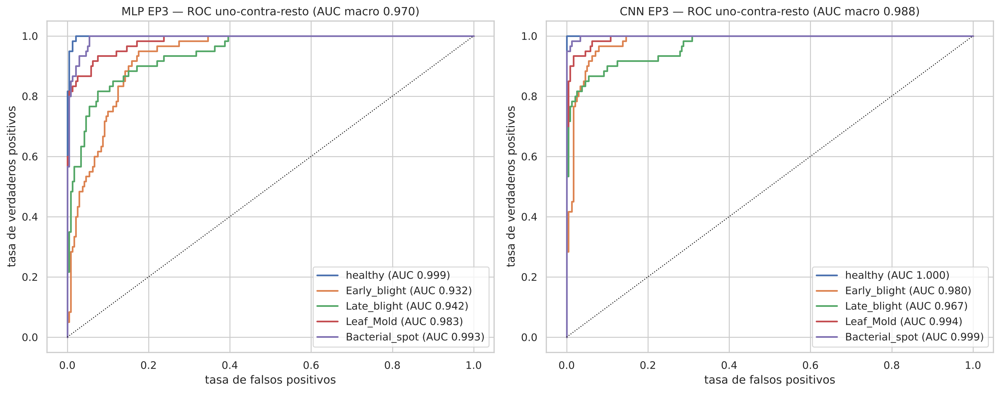

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, n in zip(axes, ("MLP EP3", "CNN EP3")):
    yp = EV_TEST[n]["y_prob"]
    for c in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(T["y_test"] == c, yp[:, c])
        ax.plot(fpr, tpr, lw=1.8, label=f"{CORTO[c]} (AUC {roc_auc_score(T['y_test'] == c, yp[:, c]):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_title(f"{n} — ROC uno-contra-resto (AUC macro {EV_TEST[n]['metricas']['roc_auc']:.3f})")
    ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos"); ax.legend(loc="lower right")
plt.tight_layout(); save_fig("ep3_08_roc.png"); plt.show()

### 8.6 ¿Las diferencias son reales? Prueba de McNemar

In [43]:
PARES = [("CNN EP3", "MLP EP3"), ("CNN EP3", "CNN EP2"), ("MLP EP3", "MLP EP1"), ("CNN EP2", "MLP EP1")]


def tabla_mcnemar(y, evaluaciones):
    filas = []
    for a, b in PARES:
        r = mcnemar(y, evaluaciones[a]["y_pred"], evaluaciones[b]["y_pred"])
        filas.append({"A": a, "B": b, "acc A": evaluaciones[a]["metricas"]["accuracy"],
                      "acc B": evaluaciones[b]["metricas"]["accuracy"],
                      "solo A acierta": r["solo A acierta"], "solo B acierta": r["solo B acierta"],
                      "p-valor": r["p"], "¿significativa (p < 0,05)?": "SÍ" if r["p"] < 0.05 else "no"})
    return pd.DataFrame(filas)


MCNEMAR_TEST = tabla_mcnemar(T["y_test"], EV_TEST)
display(MCNEMAR_TEST.round(4))

,A,B,acc A,acc B,solo A acierta,solo B acierta,p-valor,"¿significativa (p < 0,05)?"
0,CNN EP3,MLP EP3,0.9067,0.8233,33,8,0.0001,SÍ
1,CNN EP3,CNN EP2,0.9067,0.9100,4,5,1.0000,no
2,MLP EP3,MLP EP1,0.8233,0.8233,7,7,1.0000,no
3,CNN EP2,MLP EP1,0.9100,0.8233,36,10,0.0002,SÍ


**Lectura de la prueba oficial.**

- **CNN vs MLP (EP3):** 0,907 frente a 0,823 de accuracy (+8,3 pp). En las 41 imágenes donde discrepan, la CNN acierta 33 y el MLP 8: **p = 0,0001**. La ventaja de la arquitectura convolucional se mantiene igual que en la EP2.
- **EP3 vs EP1/EP2 (misma configuración, otro entrenamiento):** el MLP EP3 obtiene exactamente el mismo accuracy que el de la EP1 (82,33 %) y la CNN EP3 queda 1 imagen por debajo de la EP2 (90,67 % frente a 91,00 %). McNemar: p = 1,0 en ambos casos. Reentrenar la misma configuración en otro equipo reproduce el resultado, lo que respalda que las conclusiones no dependen de una ejecución con suerte.
- **Entre semillas (8.3):** el F1 de prueba de la CNN va de 0,877 a 0,907 (media 0,895 ± 0,015) y el del MLP de 0,822 a 0,836 (0,828 ± 0,008). Con 300 imágenes, una diferencia de 3 pp entre dos ejecuciones de la misma configuración es normal. Por eso ningún número de una sola ejecución se toma como definitivo.
- **KPIs en la prueba oficial:** la CNN EP3 queda justo bajo la meta de F1 ≥ 0,91 (0,907) y de recall de enfermas ≥ 0,90 (0,883). La diferencia con la meta es de 1 imagen en F1 y de 4 hojas enfermas en recall. La prueba ampliada (8.7) permite juzgarlo con mucha más precisión.

### 8.7 Prueba ampliada: las imágenes que ningún modelo vio

La prueba oficial tiene 300 imágenes (1 imagen = 0,33 pp). La prueba ampliada reúne las imágenes de las cinco clases que no entraron al muestreo de la EP1, sin duplicados ni hojas compartidas con la muestra (4.1). Ningún modelo la usó para entrenar ni para elegir hiperparámetros. Como está desbalanceada, se reportan métricas **macro**.

Prueba ampliada: (5350, 64, 64, 3)


,Accuracy,IC95 accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC macro,Recall enfermas,Enfermas → sana,% enfermas → sana,ECE
modelo,,,,,,,,,,
MLP EP1,0.8507,[0.841; 0.860],0.8138,0.8462,0.8230,0.9764,0.8168,96,0.0226,0.0183
CNN EP2,0.9323,[0.925; 0.939],0.9083,0.9364,0.9191,0.9935,0.9219,28,0.0066,0.0072
MLP EP3,0.8546,[0.845; 0.864],0.8246,0.8526,0.8307,0.9789,0.8249,94,0.0221,0.0312
CNN EP3,0.9264,[0.919; 0.933],0.9040,0.9365,0.9144,0.9944,0.9214,21,0.0049,0.0215


,A,B,acc A,acc B,solo A acierta,solo B acierta,p-valor,"¿significativa (p < 0,05)?"
0,CNN EP3,MLP EP3,0.926355,0.854579,508,124,0.000000,SÍ
1,CNN EP3,CNN EP2,0.926355,0.932336,66,98,0.015235,SÍ
2,MLP EP3,MLP EP1,0.854579,0.850654,143,122,0.219152,no
3,CNN EP2,MLP EP1,0.932336,0.850654,555,118,0.000000,SÍ


Figura guardada: ep3_08_ampliada.png


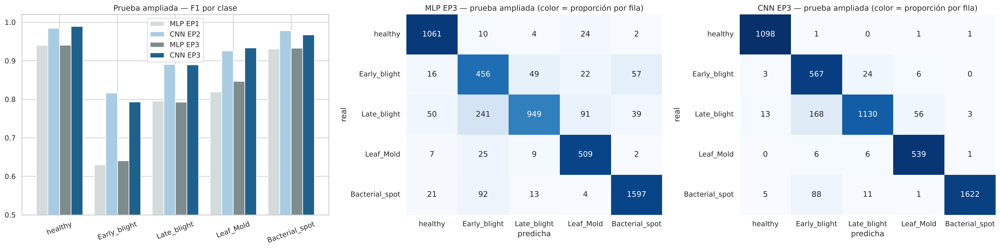

In [44]:
X_amp, y_amp = cargar_tensores(datos["ampliada"])
print("Prueba ampliada:", X_amp.shape)
EV_AMP = {n: evaluar_metricas(m, X_amp, y_amp) for n, m in MODELOS.items()}
filas = []
for n in MODELOS:
    k = EV_AMP[n]["metricas"]
    lo, hi = wilson(int(round(k["accuracy"] * len(y_amp))), len(y_amp))
    filas.append({"modelo": n, "Accuracy": k["accuracy"], "IC95 accuracy": f"[{lo:.3f}; {hi:.3f}]",
                  "Precision macro": k["precision"], "Recall macro": k["recall"], "F1 macro": k["f1"],
                  "ROC-AUC macro": k["roc_auc"], "Recall enfermas": k["recall_enfermas"],
                  "Enfermas → sana": k["enfermas_a_sana"], "% enfermas → sana": k["enfermas_a_sana"] / k["n_enfermas"],
                  "ECE": k["ece"]})
COMPARACION_AMP = pd.DataFrame(filas).set_index("modelo")
display(COMPARACION_AMP.round(4))
MCNEMAR_AMP = tabla_mcnemar(y_amp, EV_AMP)
display(MCNEMAR_AMP.round(6))

fig, axes = plt.subplots(1, 3, figsize=(22, 5.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
f1c = pd.DataFrame({n: EV_AMP[n]["reporte"]["f1-score"] for n in MODELOS})
f1c.plot(kind="bar", ax=axes[0], color=[colores_m[n] for n in MODELOS], width=0.8)
axes[0].set_ylim(0.5, 1.02); axes[0].set_title("Prueba ampliada — F1 por clase"); axes[0].tick_params(axis="x", rotation=20)
for ax, n in zip(axes[1:], ("MLP EP3", "CNN EP3")):
    cm_ = EV_AMP[n]["cm"]
    sns.heatmap(cm_ / cm_.sum(axis=1, keepdims=True), annot=cm_, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CORTO, yticklabels=CORTO, ax=ax)
    ax.set_title(f"{n} — prueba ampliada (color = proporción por fila)"); ax.set_xlabel("predicha"); ax.set_ylabel("real")
plt.tight_layout(); save_fig("ep3_08_ampliada.png"); plt.show()

**Lectura de la prueba ampliada (5.350 imágenes que ningún modelo vio).**

- **Los resultados de la prueba oficial se confirman, ahora con intervalos estrechos.** CNN EP3: accuracy 0,926 [0,919; 0,933], F1 macro 0,914. MLP EP3: 0,855 [0,845; 0,864], F1 0,831. En las 632 imágenes donde discrepan, la CNN acierta 508 y el MLP 124 (p ≈ 10⁻⁵⁶).
- **El error más costoso es raro en la CNN:** solo el **0,49 %** de las enfermas se clasifica como sana (21 de 4.249), frente al 2,2 % del MLP. Cumple el KPI (≤ 1 %).
- **Calibración:** ECE de 0,022 (CNN) frente a 0,031 (MLP). La confianza de la CNN es más informativa para derivar casos dudosos.
- **CNN EP3 vs CNN EP2:** misma configuración y la diferencia es mínima (0,926 frente a 0,932). Con 5.350 imágenes, McNemar la detecta (p = 0,015): dos entrenamientos de la misma red no son idénticos, y esa variación (~0,6 pp) es el piso de ruido contra el que hay que juzgar cualquier "mejora" de la optimización.
- **Por clase:** las dos CNN superan al MLP en las cinco clases. La de menor F1 es **Early_blight** (0,79 en la CNN EP3), pero no por sus propias imágenes (recall 0,945). Su problema es que **recibe los errores de otras clases**: 168 Late_blight y 88 Bacterial_spot se clasifican como Early_blight, lo que deja su precision en 0,68. El origen principal de esa confusión es Late_blight, que se analiza por sesión de captura en 9.3.

---

## 9. Auditoría del modelo

Las métricas dicen **cuánto** acierta el modelo. La auditoría pregunta **por qué** acierta, **con quién** falla y **qué tan frágil** es.

### 9.1 Grad-CAM: ¿cambió dónde mira la CNN?

Se calcula Grad-CAM sobre todas las hojas de prueba bien clasificadas por cada CNN y se mide qué porcentaje de la activación cae sobre la hoja (máscara de `mascara_hoja`). La columna "concentración" divide ese porcentaje por el área que ocupa la hoja: 1 equivale a mirar uniformemente; más de 1, a concentrarse en la hoja.

Área media de la hoja en la prueba: 38.3% | máscaras fuera de rango (< 5 % o > 90 % de la imagen): 1


CNN EP2                                                  CNN EP3                                                 
                     n % evidencia en hoja % área de hoja concentración       n % evidencia en hoja % área de hoja concentración
clase                                                                                                                           
healthy             60               54.66          33.97          1.61      60               57.85          33.97          1.70
Early_blight        57               53.28          41.87          1.27      58               54.87          42.03          1.31
Late_blight         46               37.72          37.16          1.01      44               37.88          37.26          1.02
Leaf_Mold           54                7.87          29.61          0.27      54               10.40          29.61          0.35
Bacterial_spot      56               69.78          47.94          1.46      56               72.21          47.52          1.52

Figura guardada: ep3_09_gradcam_ep2_vs_ep3.png


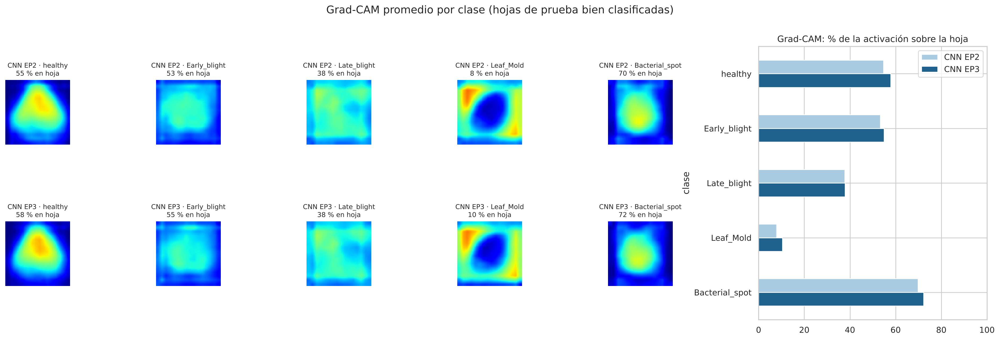

In [45]:
MASCARAS_TEST = np.stack([mascara_hoja(x) for x in T["X_test"]])
print(f"Área media de la hoja en la prueba: {MASCARAS_TEST.mean():.1%} | máscaras fuera de rango "
      f"(< 5 % o > 90 % de la imagen): {int(((MASCARAS_TEST.mean(axis=(1, 2)) < 0.05) | (MASCARAS_TEST.mean(axis=(1, 2)) > 0.9)).sum())}")


def gradcam_por_clase(modelo, y_pred):
    promedios, filas = {}, []
    for c in range(NUM_CLASSES):
        idx = [i for i in np.where(T["y_test"] == c)[0] if y_pred[i] == c] or list(np.where(T["y_test"] == c)[0])
        mapas = np.stack([gradcam(modelo, T["X_test"][i], c)[0] for i in idx])
        promedios[c] = mapas.mean(axis=0)
        en_hoja = np.mean([fraccion_en_hoja(mp, MASCARAS_TEST[i]) for mp, i in zip(mapas, idx)])
        area = MASCARAS_TEST[idx].mean()
        filas.append({"clase": CORTO[c], "n": len(idx), "% evidencia en hoja": 100 * en_hoja,
                      "% área de hoja": 100 * area, "concentración": en_hoja / area})
    return promedios, pd.DataFrame(filas).set_index("clase")


GC = {n: gradcam_por_clase(MODELOS[n], EV_TEST[n]["y_pred"]) for n in ("CNN EP2", "CNN EP3")}
XAI_GRADCAM = pd.concat({n: GC[n][1] for n in GC}, axis=1)
display(XAI_GRADCAM.round(2))

fig = plt.figure(figsize=(19, 6.4))
grid_ = fig.add_gridspec(2, NUM_CLASSES + 2, width_ratios=[1] * NUM_CLASSES + [1.1, 1.1])
for r, n in enumerate(("CNN EP2", "CNN EP3")):
    for c in range(NUM_CLASSES):
        ax = fig.add_subplot(grid_[r, c])
        ax.imshow(GC[n][0][c], cmap="jet", vmin=0, vmax=1); ax.axis("off")
        ax.set_title(f"{n} · {CORTO[c]}\n{GC[n][1].loc[CORTO[c], '% evidencia en hoja']:.0f} % en hoja", fontsize=9)
ax = fig.add_subplot(grid_[:, NUM_CLASSES:])
XAI_GRADCAM.xs("% evidencia en hoja", axis=1, level=1).plot(kind="barh", ax=ax, color=["#a9cce3", "#1f618d"])
ax.set_title("Grad-CAM: % de la activación sobre la hoja"); ax.set_xlim(0, 100); ax.invert_yaxis()
plt.suptitle("Grad-CAM promedio por clase (hojas de prueba bien clasificadas)", y=1.0)
plt.tight_layout(); save_fig("ep3_09_gradcam_ep2_vs_ep3.png"); plt.show()

**Lectura de Grad-CAM (CNN EP2 vs CNN EP3).** La hoja ocupa en promedio el 38 % de la imagen.

| Clase | % de la activación en la hoja (EP2 → EP3) | Concentración | Interpretación |
|---|---|---|---|
| healthy | 55 → 58 % | 1,6–1,7 | Mira la hoja completa: correcto, "sana" es la ausencia de lesiones en toda la superficie. |
| Bacterial_spot | 70 → 72 % | 1,5 | Mira el interior de la hoja, donde están los puntos: correcto. |
| Early_blight | 53 → 55 % | 1,3 | Mayormente la hoja, con calor sobre las lesiones. |
| Late_blight | 38 → 38 % | **1,0** | Atención **uniforme**: mira la hoja y el fondo por igual. |
| Leaf_Mold | 8 → 10 % | **0,3** | **Mira el fondo:** el 90 % de la activación cae fuera de la hoja. El mapa promedio tiene el centro frío y las esquinas calientes. |

- **El atajo de la EP2 se confirma con una medición más precisa.** La EP2 lo estimó con un marco de 8 px (50 % de la atención en el marco); con la máscara real de la hoja resulta mucho más fuerte: **solo el 8–10 % de la evidencia para Leaf_Mold está sobre la hoja**.
- **No cambió entre la EP2 y la EP3**, y era esperable: es la misma configuración. Ningún hiperparámetro de la optimización atacaba el atajo, salvo el aumento de color, que la regla de selección descartó (9.5 analiza ese trade-off).
- Late_blight con concentración 1,0 calza con lo que se ve en los errores (9.6): una parte de su "evidencia" es el fondo oscuro del invernadero.

### 9.2 LIME: la misma herramienta para el MLP y la CNN

Grad-CAM no se puede aplicar al MLP (no tiene capas convolucionales). LIME sí, porque solo necesita las predicciones. Se explican las mismas imágenes de prueba con ambos modelos (6 por clase, bien clasificadas por los dos), siempre para la **clase correcta**, y se mide el porcentaje del peso positivo de LIME que cae sobre la hoja.

modelo,CNN EP3,MLP EP3
clase,,
healthy,55.6,50.0
Early_blight,17.4,13.3
Late_blight,45.2,46.1
Leaf_Mold,29.3,22.6
Bacterial_spot,50.5,39.2
PROMEDIO,39.6,34.2


Área media de la hoja en estas imágenes: 37.4 %
R² medio del modelo lineal local de LIME: {'CNN EP3': 0.342, 'MLP EP3': 0.494}


Figura guardada: ep3_09_lime_mlp_vs_cnn.png


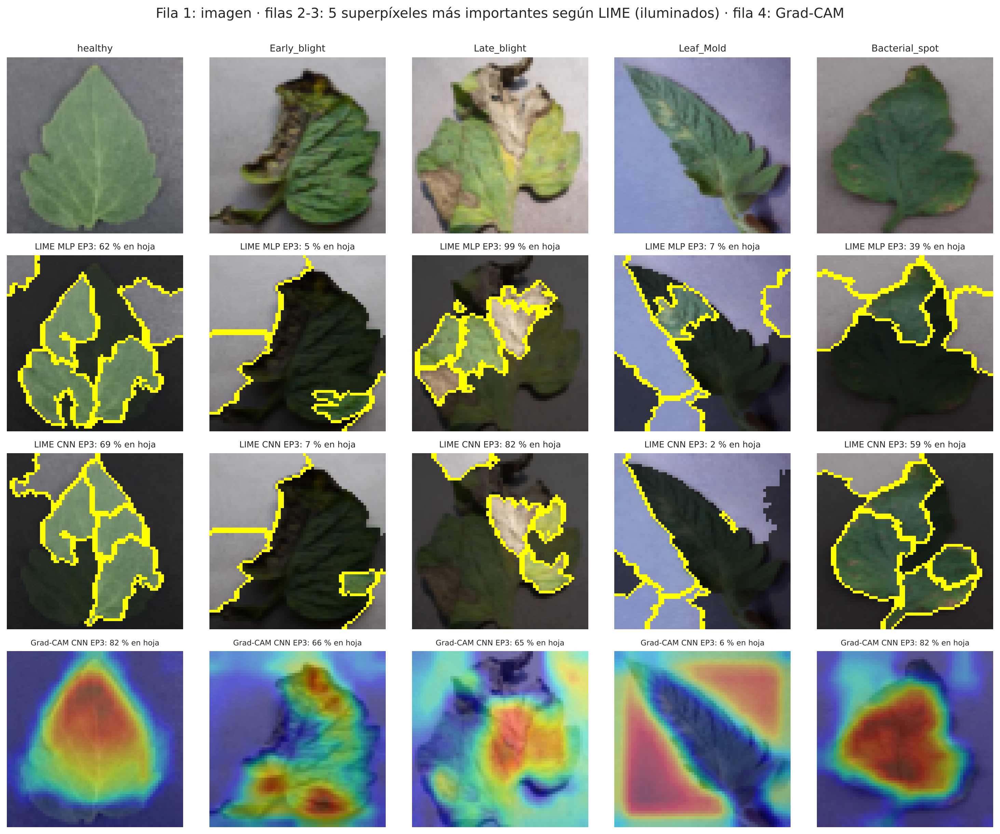

In [46]:
filas, EJEMPLOS_LIME = [], {}
for c in range(NUM_CLASSES):
    de_la_clase = np.where(T["y_test"] == c)[0]
    ambos = [i for i in de_la_clase if EV_TEST["MLP EP3"]["y_pred"][i] == c and EV_TEST["CNN EP3"]["y_pred"][i] == c]
    elegidos = (ambos + [i for i in de_la_clase if i not in ambos])[:LIME_POR_CLASE]
    for i in elegidos:
        for n in ("MLP EP3", "CNN EP3"):
            e = explicar_lime(MODELOS[n], T["X_test"][i], clase=c)
            EJEMPLOS_LIME[(n, int(i))] = e
            filas.append({"modelo": n, "clase": CORTO[c], "índice": int(i),
                          "% evidencia en hoja": 100 * fraccion_en_hoja(e["mapa"], MASCARAS_TEST[i]),
                          "% área de hoja": 100 * MASCARAS_TEST[i].mean(), "R² local": e["r2_local"]})
XAI_LIME = pd.DataFrame(filas)
resumen_lime = XAI_LIME.pivot_table(index="clase", columns="modelo", values="% evidencia en hoja", aggfunc="mean").reindex(CORTO)
resumen_lime.loc["PROMEDIO"] = resumen_lime.mean()
display(resumen_lime.round(1))
print("Área media de la hoja en estas imágenes:", f"{XAI_LIME['% área de hoja'].mean():.1f} %")
print("R² medio del modelo lineal local de LIME:", XAI_LIME.groupby("modelo")["R² local"].mean().round(3).to_dict())

ejemplos = [XAI_LIME[(XAI_LIME["clase"] == CORTO[c])]["índice"].iloc[0] for c in range(NUM_CLASSES)]
fig, axes = plt.subplots(4, NUM_CLASSES, figsize=(3.0 * NUM_CLASSES, 12.2))
for k, i in enumerate(ejemplos):
    img = T["X_test"][i]
    axes[0, k].imshow(img); axes[0, k].set_title(f"{CORTO[T['y_test'][i]]}", fontsize=10); axes[0, k].axis("off")
    for r, n in ((1, "MLP EP3"), (2, "CNN EP3")):
        e = EJEMPLOS_LIME[(n, int(i))]
        resaltado = np.isin(e["segmentos"], e["top"])
        axes[r, k].imshow(mark_boundaries(img * (0.35 + 0.65 * resaltado[..., None]), e["segmentos"] * resaltado))
        axes[r, k].set_title(f"LIME {n}: {100 * fraccion_en_hoja(e['mapa'], MASCARAS_TEST[i]):.0f} % en hoja", fontsize=9)
        axes[r, k].axis("off")
    cam_, _ = gradcam(MODELOS["CNN EP3"], img, int(T["y_test"][i]))
    superponer(axes[3, k], img, cam_, f"Grad-CAM CNN EP3: {100 * fraccion_en_hoja(cam_, MASCARAS_TEST[i]):.0f} % en hoja")
plt.suptitle("Fila 1: imagen · filas 2-3: 5 superpíxeles más importantes según LIME (iluminados) · fila 4: Grad-CAM", y=1.0)
plt.tight_layout(); save_fig("ep3_09_lime_mlp_vs_cnn.png"); plt.show()

**Lectura de LIME (MLP EP3 vs CNN EP3, 30 imágenes).** La hoja ocupa el 37 % de estas imágenes.

| Clase | % de la evidencia LIME en la hoja: MLP | CNN |
|---|---|---|
| healthy | 50 % | 56 % |
| Early_blight | **13 %** | **17 %** |
| Late_blight | 46 % | 45 % |
| Leaf_Mold | **23 %** | **29 %** |
| Bacterial_spot | 39 % | 51 % |
| **Promedio** | **34 %** | **40 %** |

- **Comparación de explicabilidad:** con la misma herramienta, la CNN pone algo más de evidencia sobre la hoja que el MLP (40 % frente a 34 %), y ambos quedan cerca del área de la hoja: **ninguno de los dos se concentra claramente en la enfermedad**. Además, la CNN tiene Grad-CAM, que es más fino y más barato (un gradiente frente a 500 predicciones por imagen). El MLP solo admite métodos de caja negra como LIME.
- **Leaf_Mold:** ambos modelos usan el fondo (23 % y 29 % en la hoja). **El atajo no es propio de la CNN, es del dataset:** cualquier modelo lo aprende.
- **Early_blight: LIME y Grad-CAM discrepan.** Grad-CAM marca las lesiones; LIME marca el fondo (13–17 % en la hoja). La explicación está en **cómo perturba LIME**: "apaga" superpíxeles pintándolos de negro, y **un fondo negro es la firma de las sesiones `GHLB_PS` (Late_blight)**. Al ennegrecer el fondo claro de una Early_blight, la imagen se parece a una Late_blight de invernadero, la probabilidad de Early_blight cae, y LIME concluye que el fondo era importante. Es un límite de LIME, que depende del color de reemplazo, y a la vez otra señal de que **el color del fondo está asociado a la clase**.
- **Confiabilidad:** el R² del modelo lineal local de LIME es bajo (0,34 CNN; 0,49 MLP). Sus explicaciones son aproximaciones gruesas; por eso, para la CNN, se prioriza Grad-CAM y se contrasta con la **intervención causal del fondo** (9.3 b).

### 9.3 Sesgos: ¿el modelo funciona igual para todos los orígenes de captura?

**(a) Rendimiento por subgrupo.** En la prueba ampliada cada combinación clase–origen tiene cientos de imágenes, así que el recall por subgrupo se estima con precisión. El KPI de sesgo es la mayor diferencia de recall entre orígenes de una misma clase.

,clase,origen,n,MLP EP1,IC95 MLP EP1,CNN EP2,IC95 CNN EP2,MLP EP3,IC95 MLP EP3,CNN EP3,IC95 CNN EP3
0,Bacterial_spot,GCREC_Bact.Sp,1432,0.933,[0.92; 0.94],0.962,[0.95; 0.97],0.934,[0.92; 0.95],0.946,[0.93; 0.96]
1,Bacterial_spot,UF.GRC_BS_Lab,295,0.827,[0.78; 0.87],0.942,[0.91; 0.96],0.878,[0.84; 0.91],0.908,[0.87; 0.94]
2,Early_blight,RS_Erly.B,600,0.710,[0.67; 0.74],0.918,[0.89; 0.94],0.760,[0.72; 0.79],0.945,[0.92; 0.96]
3,Late_blight,GHLB*,651,0.885,[0.86; 0.91],0.988,[0.98; 0.99],0.891,[0.86; 0.91],0.982,[0.97; 0.99]
4,Late_blight,RS_Late.B,719,0.544,[0.51; 0.58],0.705,[0.67; 0.74],0.513,[0.48; 0.55],0.683,[0.65; 0.72]
5,Leaf_Mold,Crnl_L.Mold,552,0.937,[0.91; 0.95],0.971,[0.95; 0.98],0.922,[0.90; 0.94],0.976,[0.96; 0.99]
6,healthy,GH_HL,350,0.994,[0.98; 1.00],0.991,[0.98; 1.00],0.991,[0.98; 1.00],0.994,[0.98; 1.00]
7,healthy,RS_HL,750,0.949,[0.93; 0.96],0.997,[0.99; 1.00],0.951,[0.93; 0.96],0.999,[0.99; 1.00]


Diferencia de recall entre orígenes de una misma clase (KPI ≤ 0,15):


,MLP EP1,CNN EP2,MLP EP3,CNN EP3
clase,,,,
Bacterial_spot,0.106,0.020,0.056,0.037
Late_blight,0.341,0.283,0.378,0.299
healthy,0.045,0.006,0.041,0.004
MÁXIMO,0.341,0.283,0.378,0.299


Figura guardada: ep3_09_subgrupos.png


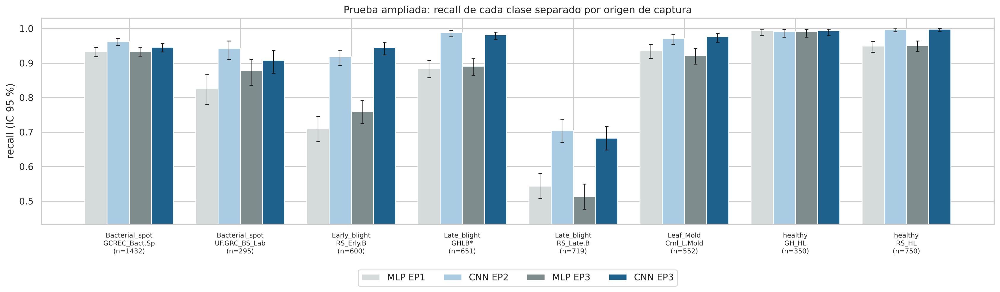

In [47]:
PRED_AMP = {n: EV_AMP[n]["y_pred"] for n in MODELOS}
SUBGRUPOS = rendimiento_por_origen(datos["ampliada"], PRED_AMP)
display(SUBGRUPOS.round(3))
BRECHA_ORIGEN = pd.concat([brecha_entre_origenes(SUBGRUPOS, n) for n in MODELOS], axis=1)
BRECHA_ORIGEN.loc["MÁXIMO"] = BRECHA_ORIGEN.max()
print("Diferencia de recall entre orígenes de una misma clase (KPI ≤ 0,15):")
display(BRECHA_ORIGEN.round(3))

fig, ax = plt.subplots(figsize=(17, 5.2))
etiquetas = SUBGRUPOS["clase"] + "\n" + SUBGRUPOS["origen"] + "\n(n=" + SUBGRUPOS["n"].astype(str) + ")"
x = np.arange(len(SUBGRUPOS))
for k, n in enumerate(MODELOS):
    v = SUBGRUPOS[n].to_numpy()
    lo_hi = np.array([wilson(round(p * m), m) for p, m in zip(v, SUBGRUPOS["n"])])
    ax.bar(x + (k - 1.5) * 0.2, v, 0.2, color=colores_m[n], label=n,
           yerr=np.clip([v - lo_hi[:, 0], lo_hi[:, 1] - v], 0, None), capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(x); ax.set_xticklabels(etiquetas, fontsize=8)
ax.set_ylim(max(0, SUBGRUPOS[list(MODELOS)].min().min() - 0.08), 1.03)
ax.set_ylabel("recall (IC 95 %)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
ax.set_title("Prueba ampliada: recall de cada clase separado por origen de captura")
plt.tight_layout(); save_fig("ep3_09_subgrupos.png"); plt.show()

**Lectura: sesgo por origen de captura (prueba ampliada, cientos de imágenes por subgrupo).**

- **Late_blight es la clase con sesgo fuerte, en todos los modelos.** Las Late_blight del invernadero (`GHLB*`) se reconocen al 98 % con la CNN EP3, pero las de la sesión `RS_Late.B` solo al **68 %** [0,65; 0,72]: una diferencia de **0,30**, el doble del KPI (≤ 0,15). En el MLP es aún peor (0,51 frente a 0,89). **Ningún modelo cumple el KPI de sesgo.**
- **Por qué:** las `RS_Late.B` comparten fondo y luz con las Early_blight (también sesión RS). Cuando el fondo no ayuda, la red tiene que distinguir dos tizones de color parecido por la forma de la lesión, y a 64×64 no le alcanza. Con las de invernadero, el fondo oscuro "resuelve" la clase.
- **Las CNN reducen los demás sesgos.** En Bacterial_spot, la sesión minoritaria `UF.GRC_BS_Lab` (17 % de la clase) bajaba al 70 % en la prueba oficial de la EP2; en la ampliada, con 295 imágenes, la diferencia es de solo 0,04 en la CNN EP3 (0,91 frente a 0,95), pero de 0,11 en el MLP EP1. En healthy no hay diferencias relevantes (≤ 0,05).
- **Implicancia ética:** el desempeño global (93 %) esconde un subgrupo concreto (tizón tardío fotografiado en las condiciones de la sesión RS) donde **uno de cada tres casos no se detecta**. El tizón tardío es justamente la enfermedad que más rápido destruye un cultivo. Un productor cuyas fotos se parezcan a esa sesión recibiría un servicio peor sin saberlo.

**(b) Intervención sobre el fondo.** Para pasar de la correlación a una prueba causal se **reemplaza el fondo** de cada imagen de la prueba ampliada por un gris neutro (el color medio de los fondos de entrenamiento), dejando la hoja intacta. Si un modelo usa el fondo como atajo, su recall debería caer justamente en las clases cuyo fondo era distintivo.

Color neutro (RGB 0-255): [126.2 121.6 126.7]


modelo,CNN EP2,CNN EP3,MLP EP1,MLP EP3
clase,,,,
healthy,-7.2,-7.8,-2.7,-2.9
Early_blight,-20.8,-11.3,-32.2,-31.3
Late_blight,-32.2,-32.2,-25.5,-28.0
Leaf_Mold,-62.0,-55.1,-27.4,-36.2
Bacterial_spot,-46.3,-42.8,-7.6,-7.5
F1 macro,-33.6,-29.8,-19.0,-20.5


Figura guardada: ep3_09_fondo_neutro.png


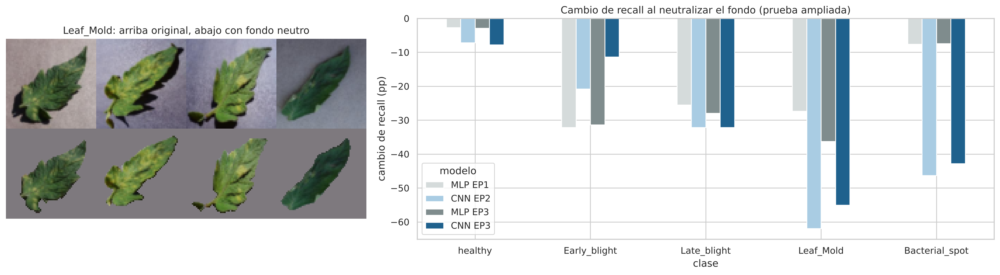

In [48]:
MASCARAS_TRAIN = np.stack([mascara_hoja(x) for x in T["X_train"]])
COLOR_NEUTRO = T["X_train"][~MASCARAS_TRAIN].mean(axis=0)
MASCARAS_AMP = np.stack([mascara_hoja(x) for x in X_amp])
print("Color neutro (RGB 0-255):", np.round(COLOR_NEUTRO * 255, 1))


def neutralizar_fondo(X, mascaras, color=None):
    """Reemplaza los píxeles de fondo por un color neutro, conservando la hoja."""
    Xn = X.copy()
    Xn[~mascaras] = COLOR_NEUTRO if color is None else color
    return Xn


X_amp_neutro = neutralizar_fondo(X_amp, MASCARAS_AMP)
filas = []
for n, m in MODELOS.items():
    pred_n = m.predict(X_amp_neutro, verbose=0, batch_size=256).argmax(1)
    for c in range(NUM_CLASSES):
        sel = y_amp == c
        filas.append({"modelo": n, "clase": CORTO[c], "recall original": (EV_AMP[n]["y_pred"][sel] == c).mean(),
                      "recall fondo neutro": (pred_n[sel] == c).mean()})
    filas.append({"modelo": n, "clase": "F1 macro", "recall original": EV_AMP[n]["metricas"]["f1"],
                  "recall fondo neutro": f1_score(y_amp, pred_n, average="macro")})
FONDO_NEUTRO = pd.DataFrame(filas)
FONDO_NEUTRO["cambio (pp)"] = 100 * (FONDO_NEUTRO["recall fondo neutro"] - FONDO_NEUTRO["recall original"])
display(FONDO_NEUTRO.pivot(index="clase", columns="modelo", values="cambio (pp)").reindex(CORTO + ["F1 macro"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
idx = np.where(y_amp == LABEL_TO_ID["Tomato_Leaf_Mold"])[0][:4]
axes[0].imshow(np.concatenate([np.concatenate([X_amp[i], X_amp_neutro[i]], axis=0) for i in idx], axis=1))
axes[0].set_title("Leaf_Mold: arriba original, abajo con fondo neutro"); axes[0].axis("off")
piv = FONDO_NEUTRO.pivot(index="clase", columns="modelo", values="cambio (pp)").reindex(CORTO)[list(MODELOS)]
piv.plot(kind="bar", ax=axes[1], color=[colores_m[n] for n in MODELOS])
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_ylabel("cambio de recall (pp)")
axes[1].set_title("Cambio de recall al neutralizar el fondo (prueba ampliada)"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); save_fig("ep3_09_fondo_neutro.png"); plt.show()

**Lectura: intervención del fondo (prueba causal).** Se cambia **solo** el fondo y la hoja queda idéntica. Si el modelo mirara solo la hoja, nada debería cambiar.

| Clase | Cambio de recall de la CNN EP3 | MLP EP3 |
|---|---|---|
| healthy | −8 pp | −3 pp |
| Early_blight | −11 pp | −31 pp |
| Late_blight | −32 pp | −28 pp |
| **Leaf_Mold** | **−55 pp** | −36 pp |
| Bacterial_spot | −43 pp | −8 pp |
| F1 macro | **−30 pp** | −21 pp |

- **Es la prueba más fuerte de la auditoría.** Con el fondo neutralizado, la CNN pierde 55 pp de recall en Leaf_Mold, exactamente la clase que Grad-CAM mostraba mirando el fondo. Sin su fondo azulado, **más de la mitad de las Leaf_Mold dejan de reconocerse**. Correlación (Grad-CAM) y causalidad (intervención) coinciden.
- **El problema no es solo de Leaf_Mold.** Bacterial_spot (−43 pp) y Late_blight (−32 pp) también dependen del fondo. Healthy apenas cambia (−8 pp), lo que indica que la imagen con fondo gris no es en sí misma algo "irreconocible" para la red: la caída es selectiva por clase.
- **Advertencia metodológica:** el fondo gris plano con un borde de máscara recortado es una imagen artificial, y parte de la caída puede deberse a eso. Que healthy casi no cambie y que la caída se concentre en las clases con fondo distintivo apoya la lectura de atajo.
- **La CNN depende más del fondo que el MLP** (−30 frente a −21 pp de F1). Su mayor capacidad para extraer patrones también le sirve para aprender mejor los atajos.

**(c) Hojas repetidas entre entrenamiento y prueba.** En 4.2.2 se vio que algunas hojas físicas tienen fotos en más de un subconjunto. Se compara el acierto en las imágenes de prueba cuya hoja también está en entrenamiento frente al resto.

In [49]:
hermana = calidad["test_con_hermana_en_train"].to_numpy()
filas = []
for n in MODELOS:
    ok = EV_TEST[n]["y_pred"] == T["y_test"]
    filas.append({"modelo": n, f"accuracy con hoja en train (n={int(hermana.sum())})": ok[hermana].mean(),
                  f"accuracy resto (n={int((~hermana).sum())})": ok[~hermana].mean()})
FUGA = pd.DataFrame(filas).set_index("modelo")
display(FUGA.round(3))

,accuracy con hoja en train (n=7),accuracy resto (n=293)
modelo,,
MLP EP1,0.857,0.823
CNN EP2,1.000,0.908
MLP EP3,0.714,0.826
CNN EP3,1.000,0.904


**Lectura.** Las 7 imágenes de prueba cuya hoja también está en entrenamiento se aciertan al 100 % con ambas CNN (frente a ~90 % en el resto). Con n = 7 no es una diferencia estadísticamente sólida, pero va en la dirección esperada de una fuga: el modelo "ya vio" esa hoja. El efecto sobre el accuracy global es pequeño (como máximo 7 imágenes ≈ 2,3 pp, y en la práctica menos de 1 pp), pero es una debilidad metodológica de la partición heredada de la EP1. **La partición debería hacerse por hoja y no por imagen** (mejora para la próxima iteración; la prueba ampliada ya se construyó así).

### 9.4 Robustez ante cambios en la foto

En campo, las fotos no tendrán la luz ni la cámara del laboratorio. Se aplican perturbaciones realistas a la prueba ampliada (sin reentrenar) y se mide cuánto cae el F1 macro de cada modelo.

modelo,MLP EP1,CNN EP2,MLP EP3,CNN EP3
perturbación,,,,
original,0.823,0.919,0.831,0.914
"más oscura (×0,7)",0.556,0.749,0.577,0.737
"más clara (×1,3)",0.619,0.594,0.628,0.567
"menos contraste (×0,6)",0.723,0.691,0.700,0.678
"ruido gaussiano (σ=0,05)",0.821,0.439,0.830,0.420
desenfoque (σ=1 px),0.824,0.758,0.831,0.793
"tinte frío (R ×0,9; B ×1,1)",0.454,0.440,0.485,0.437
fondo neutro,0.633,0.583,0.625,0.617


Caída media de F1 macro frente a las 7 perturbaciones (pp): {'MLP EP1': 16.2, 'CNN EP2': 31.2, 'MLP EP3': 16.3, 'CNN EP3': 30.7}

Distribución de las clases PREDICHAS bajo perturbación (% de la prueba ampliada):


,healthy,Early_blight,Late_blight,Leaf_Mold,Bacterial_spot
proporción real,20.6,11.2,25.6,10.3,32.3
MLP EP3 · ruido gaussiano,21.6,15.4,19.1,12.2,31.8
CNN EP3 · ruido gaussiano,20.8,38.7,5.7,34.5,0.3
MLP EP3 · tinte frío,20.7,34.4,10.1,29.9,5.0
CNN EP3 · tinte frío,13.7,24.2,9.6,46.7,5.8
MLP EP3 · fondo neutro,29.0,14.9,12.1,9.4,34.7
CNN EP3 · fondo neutro,24.4,38.5,14.8,5.4,16.9


Figura guardada: ep3_09_robustez.png


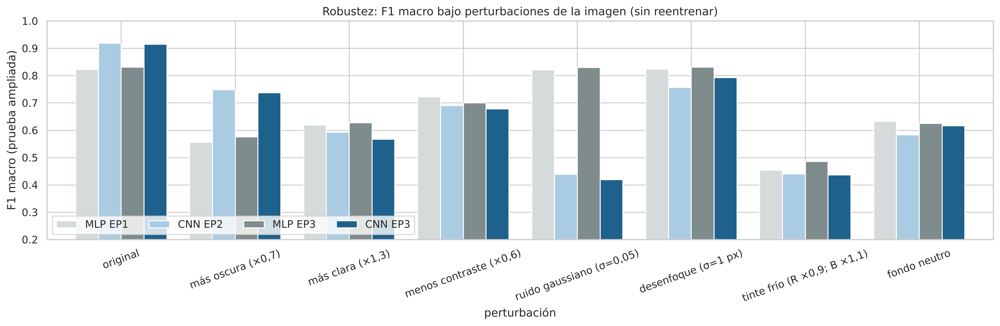

In [50]:
PERTURBACIONES = {
    "original": lambda X, M: X,
    "más oscura (×0,7)": lambda X, M: np.clip(X * 0.7, 0, 1),
    "más clara (×1,3)": lambda X, M: np.clip(X * 1.3, 0, 1),
    "menos contraste (×0,6)": lambda X, M: np.clip((X - X.mean(axis=(1, 2, 3), keepdims=True)) * 0.6
                                                   + X.mean(axis=(1, 2, 3), keepdims=True), 0, 1),
    "ruido gaussiano (σ=0,05)": lambda X, M: np.clip(X + np.random.RandomState(SEED).normal(0, 0.05, X.shape)
                                                     .astype("float32"), 0, 1),
    "desenfoque (σ=1 px)": lambda X, M: ndi.gaussian_filter(X, sigma=(0, 1, 1, 0)),
    "tinte frío (R ×0,9; B ×1,1)": lambda X, M: np.clip(X * np.array([0.9, 1.0, 1.1], dtype="float32"), 0, 1),
    "fondo neutro": lambda X, M: neutralizar_fondo(X, M),
}
filas, PRED_PERT = [], {}
for nombre_p, f in PERTURBACIONES.items():
    Xp = f(X_amp, MASCARAS_AMP)
    for n, m in MODELOS.items():
        pred_p = EV_AMP[n]["y_pred"] if nombre_p == "original" else m.predict(Xp, verbose=0, batch_size=256).argmax(1)
        PRED_PERT[(nombre_p, n)] = pred_p
        filas.append({"perturbación": nombre_p, "modelo": n, "F1 macro": f1_score(y_amp, pred_p, average="macro"),
                      "recall enfermas": float(np.mean([(pred_p[y_amp == c] == c).mean() for c in IDX_ENFERMAS]))})
    del Xp
ROBUSTEZ = pd.DataFrame(filas)
tabla_rob = ROBUSTEZ.pivot(index="perturbación", columns="modelo", values="F1 macro").reindex(PERTURBACIONES)[list(MODELOS)]
caida = (tabla_rob.loc["original"] - tabla_rob.drop(index="original")).mean()
display(tabla_rob.round(3))
print("Caída media de F1 macro frente a las 7 perturbaciones (pp):", (100 * caida).round(1).to_dict())

# ¿Hacia qué clase se van las predicciones cuando falla? (% de la prueba ampliada)
dist = {"proporción real": np.bincount(y_amp, minlength=NUM_CLASSES) / len(y_amp)}
for nombre_p in ("ruido gaussiano (σ=0,05)", "tinte frío (R ×0,9; B ×1,1)", "fondo neutro"):
    for n in ("MLP EP3", "CNN EP3"):
        dist[f"{n} · {nombre_p.split(' (')[0]}"] = np.bincount(PRED_PERT[(nombre_p, n)], minlength=NUM_CLASSES) / len(y_amp)
print("\nDistribución de las clases PREDICHAS bajo perturbación (% de la prueba ampliada):")
display((100 * pd.DataFrame(dist, index=CORTO)).round(1).T)

fig, ax = plt.subplots(figsize=(15, 5))
tabla_rob.plot(kind="bar", ax=ax, color=[colores_m[n] for n in MODELOS], width=0.8)
ax.set_ylim(0.2, 1.0); ax.set_ylabel("F1 macro (prueba ampliada)"); ax.tick_params(axis="x", rotation=20)
ax.set_title("Robustez: F1 macro bajo perturbaciones de la imagen (sin reentrenar)"); ax.legend(loc="lower left", ncol=4)
plt.tight_layout(); save_fig("ep3_09_robustez.png"); plt.show()

**Lectura de robustez (F1 macro en la prueba ampliada, sin reentrenar).**

| Perturbación | MLP EP3 | CNN EP3 | Más robusto |
|---|---|---|---|
| original | 0,831 | **0,914** | — |
| más oscura (×0,7) | 0,577 | **0,737** | CNN |
| más clara (×1,3) | **0,628** | 0,567 | MLP |
| menos contraste | **0,700** | 0,678 | ≈ |
| ruido gaussiano (σ = 0,05) | **0,830** | **0,420** | **MLP, por lejos** |
| desenfoque (σ = 1 px) | **0,831** | 0,793 | MLP |
| tinte frío (balance de blancos) | 0,485 | 0,437 | **ninguno** |
| fondo neutro | 0,625 | 0,617 | ≈ |
| **caída media** | **16 pp** | **31 pp** | **MLP** |

- **La CNN es más precisa pero bastante más frágil.** Un ruido leve (σ = 0,05, casi invisible) la hace caer de 0,91 a 0,42, mientras que el MLP no se inmuta. La tabla de clases predichas muestra hacia dónde se va: con ruido, la CNN casi **nunca** dice Bacterial_spot (0,3 % frente a 32 % real) y lleva todo hacia Early_blight (39 %) y Leaf_Mold (35 %). Sus filtros responden a la **textura fina**: el ruido borra el patrón de puntitos de Bacterial_spot y se parece al grano del fondo de tela de la sesión de Leaf_Mold.
- **El MLP es robusto al ruido y al desenfoque por la misma razón que es menos preciso:** decide sobre todo por el color global de la imagen, que el ruido y el desenfoque casi no cambian. No usa la textura, y por eso tampoco distingue bien los tizones.
- **Ambos colapsan con un cambio de balance de blancos de ±10 %** (F1 0,44–0,49). Con la imagen más azul, la CNN predice **Leaf_Mold en el 47 % de las hojas** (real: 10 %): para la red, "azulado" significa Leaf_Mold. Es el atajo del fondo visto desde otro ángulo. Una foto con otra cámara o bajo luz de sombra bastaría para romper el modelo.
- **Implicancia para el despliegue:** ninguna de las dos redes está lista para fotos de campo. Antes de usarlas habría que entrenar con perturbaciones de este tipo (ruido, desenfoque, tinte) y con fondos variados (ver 9.5).

### 9.5 ¿El aumento de color sirve para mitigar el sesgo? El otro lado del trade-off

En la OFAT (7.2 y 7.3) el aumento de color **bajó** el F1 de validación, así que la regla de selección lo descartó. Pero la validación tiene el mismo sesgo que el entrenamiento (las mismas sesiones y fondos), así que premia al modelo que usa el atajo. Para ver el otro lado se recargan los modelos de la OFAT que **solo difieren en el aumento** (misma semilla, pesos guardados en la caché, sin reentrenar) y se comparan en la prueba ampliada con y sin las perturbaciones que atacan el atajo: fondo neutro y tinte frío.

,F1 validación,F1 ampliada,F1 fondo neutro,F1 tinte frío,recall Leaf_Mold,recall Leaf_Mold fondo neutro,dif. entre orígenes,% Grad-CAM en hoja (prueba),caída por fondo neutro (pp),caída por tinte frío (pp)
modelo,,,,,,,,,,
MLP base · geom,0.882,0.831,0.625,0.485,0.922,0.560,0.378,NaN,20.529,34.524
MLP base · geom+color,0.828,0.794,0.636,0.706,0.880,0.594,0.442,NaN,15.824,8.840
MLP base · geom+color+zoom,0.798,0.778,0.583,0.681,0.928,0.659,0.464,NaN,19.509,9.736
CNN base · geom,0.910,0.914,0.617,0.437,0.976,0.426,0.299,46.643,29.761,47.747
CNN base · geom+color,0.868,0.860,0.767,0.795,0.926,0.667,0.503,50.445,9.370,6.535
CNN base · geom+color+zoom,0.876,0.830,0.739,0.710,0.947,0.600,0.816,45.646,9.094,12.007


Figura guardada: ep3_09_mitigacion_aumento.png


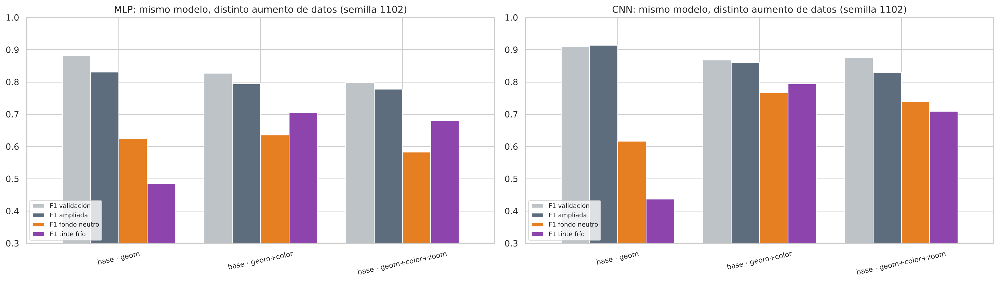

In [51]:
X_amp_tinte = PERTURBACIONES["tinte frío (R ×0,9; B ×1,1)"](X_amp, MASCARAS_AMP)
ID_LM = LABEL_TO_ID["Tomato_Leaf_Mold"]
filas = []
for tipo in ("MLP", "CNN"):
    candidatos = [(f"{tipo} base · {a}", {**CONFIG_BASE[tipo], "aumento": a})
                  for a in ["geom"] + GRID_OFAT[tipo]["aumento"]]
    if all(SELECCION[tipo] != c for _, c in candidatos):            # el elegido, si no es uno de los anteriores
        candidatos.append((f"{tipo} EP3 (elegido) · {SELECCION[tipo]['aumento']}", SELECCION[tipo]))
    for nombre, cfg in candidatos:
        m, r, _ = obtener_modelo(cfg, T, SEED, nombre=nombre)
        p_o, p_n, p_t = (m.predict(X, verbose=0, batch_size=256).argmax(1) for X in (X_amp, X_amp_neutro, X_amp_tinte))
        sub = rendimiento_por_origen(datos["ampliada"], {"m": p_o})
        fila = {"modelo": nombre, "F1 validación": r["f1_val"],
                "F1 ampliada": f1_score(y_amp, p_o, average="macro"),
                "F1 fondo neutro": f1_score(y_amp, p_n, average="macro"),
                "F1 tinte frío": f1_score(y_amp, p_t, average="macro"),
                "recall Leaf_Mold": (p_o[y_amp == ID_LM] == ID_LM).mean(),
                "recall Leaf_Mold fondo neutro": (p_n[y_amp == ID_LM] == ID_LM).mean(),
                "dif. entre orígenes": brecha_entre_origenes(sub, "m").max()}
        if tipo == "CNN":
            pred_t = m.predict(T["X_test"], verbose=0, batch_size=256).argmax(1)
            fila["% Grad-CAM en hoja (prueba)"] = gradcam_por_clase(m, pred_t)[1]["% evidencia en hoja"].mean()
        filas.append(fila)
        del m
MITIGACION = pd.DataFrame(filas).set_index("modelo")
MITIGACION["caída por fondo neutro (pp)"] = 100 * (MITIGACION["F1 ampliada"] - MITIGACION["F1 fondo neutro"])
MITIGACION["caída por tinte frío (pp)"] = 100 * (MITIGACION["F1 ampliada"] - MITIGACION["F1 tinte frío"])
display(MITIGACION.round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2))
cols = ["F1 validación", "F1 ampliada", "F1 fondo neutro", "F1 tinte frío"]
for ax, tipo in zip(axes, ("MLP", "CNN")):
    sub_ = MITIGACION[MITIGACION.index.str.startswith(tipo)][cols]
    sub_.plot(kind="bar", ax=ax, color=["#bdc3c7", "#5d6d7e", "#e67e22", "#8e44ad"], width=0.8)
    ax.set_ylim(0.3, 1.0); ax.set_xticklabels([i.replace(f"{tipo} ", "") for i in sub_.index], rotation=12, fontsize=9)
    ax.set_title(f"{tipo}: mismo modelo, distinto aumento de datos (semilla 1102)"); ax.legend(fontsize=8, loc="lower left")
    ax.set_xlabel("")
plt.tight_layout(); save_fig("ep3_09_mitigacion_aumento.png"); plt.show()

**Lectura: el aumento de color corrige el atajo, pero a un costo que la validación no muestra completo.**

| CNN (semilla 1102) | F1 validación | F1 ampliada | F1 fondo neutro | F1 tinte frío | Caída por fondo | Dif. entre orígenes |
|---|---|---|---|---|---|---|
| aumento `geom` (elegida) | **0,910** | **0,914** | 0,617 | 0,437 | 30 pp | **0,30** |
| aumento `geom+color` | 0,868 | 0,860 | **0,767** | **0,795** | **9 pp** | 0,50 |
| aumento `geom+color+zoom` | 0,876 | 0,830 | 0,739 | 0,710 | 9 pp | 0,82 |

1. **El aumento de color sí reduce la dependencia del fondo.** Con fondo neutro, la CNN `geom+color` pierde 9 pp en vez de 30. Con tinte frío, mantiene 0,80 en vez de caer a 0,44 (+36 pp). Reconoce 67 % de las Leaf_Mold sin su fondo azulado (frente a 43 %). En el MLP ocurre lo mismo con el tinte (0,49 → 0,71).
2. **Pero pierde 5 pp en la distribución original** (0,914 → 0,860), y la regla de selección, que mira la validación, lo descartó. **La validación comparte el sesgo del entrenamiento** (mismas sesiones y fondos), así que premia al modelo que usa el atajo. Optimizar contra esa validación no puede encontrar el modelo más robusto. Es la principal limitación del pipeline (sección 11).
3. **Y empeora el sesgo entre sesiones** (0,30 → 0,50). Al separar por sesión se ve por qué: con color, las Late_blight de la sesión RS caen de 68 % a 47 % de recall (a 15 % con zoom), mientras el resto se mantiene. Las `RS_Late.B` comparten fondo con las Early_blight; lo único que las separaba era el **color de la lesión** (café grisáceo del tizón tardío frente al café oscuro del temprano). El aumento de color, al alterar todos los colores de la imagen, le quita a la red el atajo del fondo, pero también esa señal legítima.

**Conclusión:** no hay una configuración que gane en todo, y la evidencia indica qué hay que cambiar. La mitigación correcta no es alterar el color de **toda** la imagen, sino **solo el fondo**: segmentar la hoja (como hace `mascara_hoja`) y reemplazar el fondo al azar durante el entrenamiento, conservando los colores de la lesión. Es la primera mejora propuesta para la siguiente iteración.

### 9.6 Errores de la CNN optimizada: dónde miraba

Para cada error de la prueba oficial (de mayor a menor confianza) se muestra el Grad-CAM de la clase **predicha** y el de la clase **real**. Si ambos señalan la misma lesión, es un error por ambigüedad visual; si el de la clase predicha cae en el fondo, es un atajo.

Errores de la CNN EP3 en la prueba oficial: 28 de 300
Confianza media: aciertos 0.952 | errores 0.749 | errores con confianza ≥ 0,90: 7


,real,predicha,origen,errores
0,Late_blight,Early_blight,RS_Late.B,12
1,Leaf_Mold,Early_blight,Crnl_L.Mold,4
2,Late_blight,Leaf_Mold,RS_Late.B,3
3,Bacterial_spot,Early_blight,GCREC_Bact.Sp,2
4,Bacterial_spot,Early_blight,UF.GRC_BS_Lab,1
5,Leaf_Mold,healthy,Crnl_L.Mold,1
6,Late_blight,healthy,GHLB*,1
7,Leaf_Mold,Late_blight,Crnl_L.Mold,1
8,Early_blight,Leaf_Mold,RS_Erly.B,1
9,Bacterial_spot,Late_blight,UF.GRC_BS_Lab,1


Figura guardada: ep3_09_errores_gradcam.png


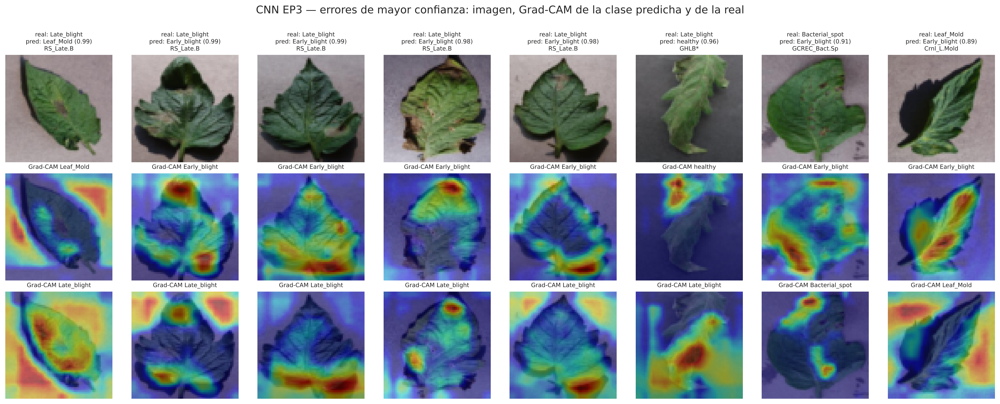

In [52]:
ev_c = EV_TEST["CNN EP3"]
errores = np.where(ev_c["y_pred"] != T["y_test"])[0]
orden = errores[np.argsort(-ev_c["y_prob"][errores].max(axis=1))][:8]
print(f"Errores de la CNN EP3 en la prueba oficial: {len(errores)} de {len(T['y_test'])}")
print(f"Confianza media: aciertos {ev_c['y_prob'][ev_c['y_pred'] == T['y_test']].max(axis=1).mean():.3f} | "
      f"errores {ev_c['y_prob'][errores].max(axis=1).mean():.3f} | errores con confianza ≥ 0,90: "
      f"{int((ev_c['y_prob'][errores].max(axis=1) >= 0.9).sum())}")
tabla_err = pd.DataFrame({"real": [CORTO[T["y_test"][i]] for i in errores],
                          "predicha": [CORTO[ev_c["y_pred"][i]] for i in errores],
                          "origen": datos["test"]["origen"].to_numpy()[errores]})
display(tabla_err.value_counts().rename("errores").reset_index())
if len(orden):
    fig, axes = plt.subplots(3, len(orden), figsize=(2.4 * len(orden), 7.6), squeeze=False)
    for k, i in enumerate(orden):
        real, pred = int(T["y_test"][i]), int(ev_c["y_pred"][i])
        axes[0, k].imshow(T["X_test"][i]); axes[0, k].axis("off")
        axes[0, k].set_title(f"real: {CORTO[real]}\npred: {CORTO[pred]} ({ev_c['y_prob'][i, pred]:.2f})\n"
                             f"{datos['test']['origen'].iloc[i]}", fontsize=8)
        superponer(axes[1, k], T["X_test"][i], gradcam(MODELOS["CNN EP3"], T["X_test"][i], pred)[0], f"Grad-CAM {CORTO[pred]}")
        superponer(axes[2, k], T["X_test"][i], gradcam(MODELOS["CNN EP3"], T["X_test"][i], real)[0], f"Grad-CAM {CORTO[real]}")
    plt.suptitle("CNN EP3 — errores de mayor confianza: imagen, Grad-CAM de la clase predicha y de la real", y=1.0)
    plt.tight_layout(); save_fig("ep3_09_errores_gradcam.png"); plt.show()

**Lectura de los errores de la CNN EP3** (28 de 300; confianza media 0,95 en aciertos y 0,75 en errores; 7 errores con confianza ≥ 0,90).

- **15 de los 28 errores son Late_blight de la sesión `RS_Late.B`** (12 hacia Early_blight y 3 hacia Leaf_Mold). Las Late_blight de invernadero tienen solo 1 error.
- En los errores `RS_Late.B → Early_blight` (confianza 0,98–0,99), el Grad-CAM de la clase predicha cae sobre lesiones reales de la hoja. Pero **el Grad-CAM de la clase real (Late_blight) se enciende en las esquinas del fondo**: para la red, la "evidencia de Late_blight" es en buena parte el fondo del invernadero. Cuando una Late_blight viene con el fondo claro de la sesión RS, esa evidencia no aparece y gana Early_blight. Es el mecanismo detrás del sesgo de 9.3.
- El caso `Late_blight → Leaf_Mold` (0,99) tiene el Grad-CAM de Leaf_Mold **en el fondo**: el mismo atajo de color.
- Entre los errores de mayor confianza, el único crítico (enferma → sana) es una Late_blight de invernadero clasificada como sana (0,96): una hoja con síntomas poco visibles.
- **Tipos de error y su solución:** (1) ambigüedad visual entre tizones → más resolución o un modelo preentrenado; (2) atajo de fondo → datos con fondos variados, segmentar la hoja o aumento de color (9.5); (3) sobreconfianza (7 errores ≥ 0,90) → un umbral de confianza no basta, se necesita además validar por sesión.

### 9.7 Medidas para mejorar la robustez y la confiabilidad

| Problema detectado | Evidencia | Medida propuesta | Prioridad |
|---|---|---|---|
| Atajo de fondo (Leaf_Mold, Bacterial_spot, Late_blight) | Grad-CAM 10 % en la hoja; −55 pp de recall con fondo neutro | **Aleatorizar solo el fondo** al entrenar (segmentación + fondos al azar). El aumento de color global no sirve (9.5). | Alta |
| Clase confundida con sesión de captura | Sesgo de 0,30 en Late_blight; ninguna sesión compartida entre clases | Recolectar cada enfermedad en **varias sesiones** y validar con **sesiones excluidas** (*leave-one-session-out*) | Alta |
| Fragilidad ante ruido y balance de blancos | F1 0,42 con ruido σ = 0,05; 0,44 con tinte ±10 % | Aumento con ruido, desenfoque y tinte **en el fondo**; probar con fotos de otras cámaras | Alta |
| Errores costosos con alta confianza | 7 errores ≥ 0,90 en la prueba oficial | Umbral de confianza para derivar al agrónomo **y** monitorear la sesión/cámara de origen | Media |
| Fuga por hojas repetidas y ruido de etiqueta | 7 imágenes de prueba con su hoja en train; un fruto etiquetado como hoja | Particionar **por hoja**; limpiar etiquetas antes de entrenar | Media |
| Tizones indistinguibles a 64×64 | 12 de los 28 errores son Late_blight RS → Early_blight | Más resolución (128–224 px) y *transfer learning* (MobileNetV2, EfficientNet) | Media |
| Validación con el mismo sesgo que el entrenamiento | La regla de selección descartó el aumento que reduce el atajo | Incluir métricas de robustez y de sesgo **en el criterio de selección**, no solo F1 | Alta |

---

## 10. MLP optimizado vs CNN final: comparación integral y modelo recomendado

In [53]:
def fila_integral(n, tipo):
    t, a = COMPARACION_TEST.loc[n], COMPARACION_AMP.loc[n]
    res = CONFIRMACION[tipo]["resumen"].loc[CONFIRMACION[tipo]["elegido"]]
    return {
        "F1 macro — prueba oficial": t["F1 macro"],
        "F1 macro — prueba ampliada": a["F1 macro"],
        "ROC-AUC macro — prueba ampliada": a["ROC-AUC macro"],
        "Recall enfermas — prueba oficial": t["Recall enfermas"],
        "% enfermas → sana — prueba ampliada": a["% enfermas → sana"],
        "ECE (calibración) — prueba ampliada": a["ECE"],
        "Brecha (train − prueba oficial)": t["Brecha (train − prueba)"],
        "Desv. estándar F1 val (3 semillas)": res["f1_std"],
        "Caída media de F1 ante perturbaciones (pp)": 100 * caida[n],
        "Mayor diferencia de recall entre orígenes": BRECHA_ORIGEN.loc["MÁXIMO", n],
        "% evidencia LIME sobre la hoja": resumen_lime.loc["PROMEDIO", n],
        "Grad-CAM disponible": "no (sin convoluciones)" if tipo == "MLP" else
                               f"sí ({XAI_GRADCAM[(n, '% evidencia en hoja')].mean():.0f} % en hoja)",
        "Parámetros": t["Parámetros"],
        "Segundos por época (CPU)": t["s por época"],
        "Tiempo de entrenamiento (s, CPU)": t["Tiempo de entrenamiento (s)"],
    }


COMPARACION_FINAL = pd.DataFrame({"MLP optimizado (EP3)": fila_integral("MLP EP3", "MLP"),
                                  "CNN optimizada (EP3)": fila_integral("CNN EP3", "CNN")})
display(COMPARACION_FINAL)

# KPIs (sección 1.4) para ambos modelos finales
def kpis_de(n, tipo):
    t, a = COMPARACION_TEST.loc[n], COMPARACION_AMP.loc[n]
    std = CONFIRMACION[tipo]["resumen"].loc[CONFIRMACION[tipo]["elegido"], "f1_std"]
    return [("F1 macro prueba oficial", "≥ 0,91", t["F1 macro"], t["F1 macro"] >= 0.91),
            ("F1 macro prueba ampliada", "≥ 0,90", a["F1 macro"], a["F1 macro"] >= 0.90),
            ("Recall enfermas (prueba oficial)", "≥ 0,90", t["Recall enfermas"], t["Recall enfermas"] >= 0.90),
            ("% enfermas → sana (ampliada)", "≤ 1 %", a["% enfermas → sana"], a["% enfermas → sana"] <= 0.01),
            ("Brecha de generalización", "≤ 0,10", t["Brecha (train − prueba)"], t["Brecha (train − prueba)"] <= 0.10),
            ("Desv. estándar F1 val entre semillas", "≤ 0,02", std, std <= 0.02),
            ("Diferencia de recall entre orígenes", "≤ 0,15", BRECHA_ORIGEN.loc["MÁXIMO", n],
             BRECHA_ORIGEN.loc["MÁXIMO", n] <= 0.15)]


filas = []
for n, tipo in (("MLP EP3", "MLP"), ("CNN EP3", "CNN")):
    for kpi, meta, valor, ok in kpis_de(n, tipo):
        filas.append({"KPI": kpi, "meta": meta, "modelo": n, "obtenido": round(float(valor), 4), "cumple": "SÍ" if ok else "NO"})
KPIS = pd.DataFrame(filas)
display(KPIS.pivot(index="KPI", columns="modelo", values=["obtenido", "cumple"]).reindex([k[0] for k in kpis_de("CNN EP3", "CNN")]))

,MLP optimizado (EP3),CNN optimizada (EP3)
F1 macro — prueba oficial,0.821484,0.906657
F1 macro — prueba ampliada,0.830723,0.914429
ROC-AUC macro — prueba ampliada,0.978934,0.994396
Recall enfermas — prueba oficial,0.779167,0.883333
% enfermas → sana — prueba ampliada,0.022123,0.004942
ECE (calibración) — prueba ampliada,0.031248,0.021509
Brecha (train − prueba oficial),0.155238,0.071905
Desv. estándar F1 val (3 semillas),0.016816,0.003363
Caída media de F1 ante perturbaciones (pp),16.260961,30.744687
Mayor diferencia de recall entre orígenes,0.377724,0.298674


obtenido          cumple        
modelo                                CNN EP3 MLP EP3 CNN EP3 MLP EP3
KPI                                                                  
F1 macro prueba oficial                0.9067  0.8215      NO      NO
F1 macro prueba ampliada               0.9144  0.8307      SÍ      NO
Recall enfermas (prueba oficial)       0.8833  0.7792      NO      NO
% enfermas → sana (ampliada)           0.0049  0.0221      SÍ      NO
Brecha de generalización               0.0719  0.1552      SÍ      NO
Desv. estándar F1 val entre semillas   0.0034  0.0168      SÍ      SÍ
Diferencia de recall entre orígenes    0.2987  0.3777      NO      NO

**Lectura y modelo recomendado.**

| Criterio | MLP optimizado | CNN optimizada | Gana |
|---|---|---|---|
| Desempeño (F1 macro, prueba oficial / ampliada) | 0,821 / 0,831 | **0,907 / 0,914** | CNN (McNemar p ≈ 10⁻⁵⁶ en la ampliada) |
| ROC-AUC (ampliada) | 0,979 | **0,994** | CNN |
| Error costoso: enfermas → sana (ampliada) | 2,2 % | **0,5 %** | CNN (4,5 veces menos) |
| Generalización: brecha train − prueba | 0,155 | **0,072** | CNN (el MLP no cumple el KPI) |
| Estabilidad entre semillas (desv. F1 val) | 0,017 | **0,003** | CNN |
| Calibración (ECE, ampliada) | 0,031 | **0,022** | CNN |
| Explicabilidad | solo LIME (caja negra, R² 0,49) | **Grad-CAM + LIME** | CNN |
| Evidencia sobre la hoja (LIME) | 34 % | 40 % | ≈ (ninguno se concentra en la hoja) |
| Robustez a perturbaciones (caída media) | **16 pp** | 31 pp | **MLP** |
| Sesgo entre sesiones (Late_blight) | 0,38 | **0,30** | CNN, pero ambos fallan el KPI |
| Parámetros | 3,18 M | **1,14 M** | CNN |
| Costo de entrenamiento (CPU) | **1,4 s/época, 76 s** | 4,9 s/época, 214 s | MLP |

**Se recomienda la CNN** (la configuración de la EP2, confirmada por la optimización), por cuatro razones:

1. **Desempeño y errores costosos.** Es mejor en todas las métricas de clasificación, en las cinco clases y en las dos pruebas, con diferencias estadísticamente significativas. Deja sin detectar 4,5 veces menos hojas enfermas, que es el error que más le importa al productor.
2. **Generalización y estabilidad.** Brecha de la mitad, cinco veces menos variación entre semillas, y cumple 4 de 7 KPIs frente a 1 de 7 del MLP.
3. **Transparencia.** Admite Grad-CAM, que es lo que permitió auditar el atajo de fondo. El MLP solo puede explicarse con LIME, que aquí resultó menos confiable.
4. **Eficiencia.** Un tercio de los parámetros. Entrena más lento por época, pero 214 s en CPU no es una limitación práctica.

**La recomendación tiene condiciones.** La CNN es más frágil que el MLP ante ruido y cambios de imagen, y ninguno de los dos cumple el KPI de sesgo. Por lo tanto se recomienda **como herramienta de apoyo en condiciones parecidas a las de PlantVillage** (hoja aislada, fondo uniforme, misma iluminación) y **con derivación al agrónomo de los casos de baja confianza**. **No se recomienda desplegarla en campo** hasta aplicar las medidas de 9.7, sobre todo la aleatorización del fondo y una validación por sesión de captura. Los tres KPIs que no cumple (F1 oficial 0,907 frente a 0,91, recall de enfermas en la prueba oficial 0,883 frente a 0,90, y sesgo 0,30 frente a 0,15) quedan como metas de la próxima iteración. Los dos primeros sí se cumplen en la prueba ampliada (F1 0,914; recall de enfermas 0,921), que es la estimación más confiable.

---

## 11. Evaluación crítica del pipeline integrado

**Fortalezas**

| Fortaleza | Por qué importa |
|---|---|
| **Modular y reutilizable** | Una sola función por etapa. El mismo pipeline entrenó, evaluó y auditó MLP y CNN sin duplicar código, y cada técnica se activa por configuración. |
| **Trazable** | Lee la partición exacta de la EP1 y verifica que los modelos de la EP1 y la EP2 reproducen sus resultados (82,33 % y 91,00 %). |
| **Reproducible** | Semilla única, operaciones deterministas y caché por hash: la segunda ejecución reprodujo exactamente los mismos números. |
| **Decisiones sin tocar la prueba** | Toda la selección se hizo en validación con una regla fijada de antemano, y la prueba se abrió una sola vez. |
| **Robusto al azar** | La confirmación con 3 semillas evitó adoptar una mejora que era suerte (L2: +1,6 pp con una semilla, +0,4 pp con tres). |
| **Auditoría más allá del accuracy** | Prueba ampliada sin fugas, rendimiento por subgrupo, intervención causal del fondo, perturbaciones y dos herramientas XAI. Así apareció un sesgo que el accuracy no mostraba. |

**Limitaciones**

1. **La validación tiene el mismo sesgo que el entrenamiento.** Es la limitación principal. Como validación y prueba vienen de las mismas sesiones, el criterio de selección premia al modelo que mejor explota el atajo, y descartó el aumento de color que lo reducía (9.5). **El pipeline optimiza bien lo que mide, pero lo que mide no es lo que importa en campo.**
2. **Partición por imagen, no por hoja.** Heredada de la EP1: 7 imágenes de prueba tienen su hoja en entrenamiento.
3. **Búsqueda limitada por el cómputo.** 63 experimentos en 2 h 42 min sin GPU: el Random Search cubrió 14 de más de 4.000 combinaciones. OFAT supone que los efectos se suman, y el Random Search mostró que a veces no es así (la CNN R5 no aprendió).
4. **Plan de experimentos cerrado antes de la ablación.** Por rigor no se agregó "sin BatchNorm" a la búsqueda, aunque la ablación sugirió que podía ayudar a la CNN.
5. **Resolución fija de 64×64** para mantener la comparación con la EP1. Probablemente es lo que impide separar los tizones por la forma de la lesión.
6. **Herramientas de auditoría aproximadas.** La máscara de la hoja es una heurística de color (1 imagen de 300 fuera de rango). LIME depende del color de reemplazo (en Early_blight discrepó de Grad-CAM). La intervención del fondo produce imágenes artificiales.
7. **Un solo dataset.** No hay fotos de campo para medir la generalización real.

**Riesgos si se usara tal como está:** falsa confianza (93 % de accuracy que en campo podría caer drásticamente, como reportan Mohanty et al., 2016, con PlantVillage: de 99 % a 31 %); peor servicio para el subgrupo de tizón tardío "tipo RS" (1 de cada 3 sin detectar); errores con confianza ≥ 0,90 que un umbral no atraparía.

**Mejoras para la siguiente versión del pipeline** (en orden de prioridad)

1. **Validación por sesión de captura** (*leave-one-session-out* o *GroupKFold* por origen) y **partición por hoja**.
2. **Selección multiobjetivo:** sumar al criterio la caída con fondo neutro, la caída con tinte y la diferencia entre sesiones, no solo el F1.
3. **Aleatorización del fondo** con la máscara de la hoja, más aumento con ruido y desenfoque.
4. **Transfer learning** (MobileNetV2 o EfficientNet-B0) a 128–224 px.
5. **Búsqueda bayesiana** (por ejemplo, Optuna) en GPU para explorar más combinaciones con el mismo presupuesto.
6. **Prueba externa** con fotos de campo (por ejemplo, PlantDoc) y calibración con *temperature scaling*.

---

## 12. Guardado de artefactos

Los modelos finales y todas las tablas quedan en `models/` (sufijo `_ep3`) y las figuras en `images/` (prefijo `ep3_`), para que el informe y la defensa se apoyen en archivos verificables. La caché `models/ep3_experimentos/` guarda un JSON por experimento (configuración, historial y métricas). Los pesos de los candidatos (`pesos/`) no se suben al repositorio por su tamaño.

> Para cargar `cnn_ep3.keras` fuera de este notebook hay que definir antes la clase `BalanceBlancoAleatorio` (sección 3.4), porque es una capa propia.

In [54]:
FINAL["MLP"]["modelo"].save(MODELS_DIR / "mlp_ep3.keras")
FINAL["CNN"]["modelo"].save(MODELS_DIR / "cnn_ep3.keras")
FINAL["MLP"]["historial"].to_csv(MODELS_DIR / "historial_mlp_ep3.csv")
FINAL["CNN"]["historial"].to_csv(MODELS_DIR / "historial_cnn_ep3.csv")

pd.concat([ABLACION[t]["tabla"] for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "ablacion_ep3.csv", index=False)
pd.concat([OFAT[t]["tabla"] for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "ofat_ep3.csv", index=False)
pd.concat([OFAT[t]["efectos"].assign(modelo=t) for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "ofat_efectos_ep3.csv", index=False)
pd.concat([RANDOM[t]["tabla"] for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "random_search_ep3.csv", index=False)
pd.concat([CONFIRMACION[t]["tabla"] for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "confirmacion_ep3.csv", index=False)
pd.concat([CONFIRMACION[t]["resumen"].assign(modelo=t) for t in ("MLP", "CNN")]).to_csv(MODELS_DIR / "confirmacion_resumen_ep3.csv")
(MODELS_DIR / "seleccion_ep3.json").write_text(json.dumps(
    {t: {"elegida": CONFIRMACION[t]["elegido"], "config": SELECCION[t],
         "cambios": describir_cambios(SELECCION[t], t)} for t in ("MLP", "CNN")}, indent=2, default=str))
SEMILLAS_TEST.to_csv(MODELS_DIR / "semillas_prueba_ep3.csv", index=False)
COMPARACION_TEST.to_csv(MODELS_DIR / "comparacion_prueba_ep3.csv")
COMPARACION_AMP.to_csv(MODELS_DIR / "comparacion_ampliada_ep3.csv")
pd.concat([MCNEMAR_TEST.assign(conjunto="prueba"), MCNEMAR_AMP.assign(conjunto="ampliada")]).to_csv(
    MODELS_DIR / "mcnemar_ep3.csv", index=False)
SUBGRUPOS.to_csv(MODELS_DIR / "subgrupos_origen_ep3.csv", index=False)
BRECHA_ORIGEN.to_csv(MODELS_DIR / "brecha_origen_ep3.csv")
FONDO_NEUTRO.to_csv(MODELS_DIR / "fondo_neutro_ep3.csv", index=False)
ROBUSTEZ.to_csv(MODELS_DIR / "robustez_ep3.csv", index=False)
XAI_GRADCAM.to_csv(MODELS_DIR / "xai_gradcam_ep3.csv")
XAI_LIME.to_csv(MODELS_DIR / "xai_lime_ep3.csv", index=False)
COMPARACION_FINAL.to_csv(MODELS_DIR / "comparacion_final_ep3.csv")
KPIS.to_csv(MODELS_DIR / "kpis_ep3.csv", index=False)
pred = datos["test"][["path_rel", "label", "origen"]].rename(columns={"path_rel": "path"}).copy()
for n in ("MLP EP3", "CNN EP3"):
    pred[f"pred {n}"] = [ID_TO_LABEL[i] for i in EV_TEST[n]["y_pred"]]
    pred[f"confianza {n}"] = EV_TEST[n]["y_prob"].max(axis=1)
pred.to_csv(MODELS_DIR / "predicciones_test_ep3.csv", index=False)
datos["ampliada"][["path_rel", "label", "origen"]].rename(columns={"path_rel": "path"}).to_csv(
    MODELS_DIR / "particion_ampliada_ep3.csv", index=False)
datos["excluidas"][["path_rel", "label", "origen", "motivo"]].rename(columns={"path_rel": "path"}).to_csv(
    MODELS_DIR / "excluidas_ampliada_ep3.csv", index=False)

print("Artefactos en", rel(MODELS_DIR) + ":")
for a in sorted(MODELS_DIR.glob("*ep3*")):
    if a.is_file():
        print(f"  {a.name:<34} {a.stat().st_size / 1024:>8.0f} KB")
print(f"Experimentos en caché: {len(list(CACHE_DIR.glob('*.json')))} | figuras ep3_*: {len(list(IMAGES_DIR.glob('ep3_*.png')))}")

Artefactos en models:
  ablacion_ep3.csv                          4 KB
  brecha_origen_ep3.csv                     0 KB
  cnn_ep3.keras                          4533 KB
  comparacion_ampliada_ep3.csv              1 KB
  comparacion_final_ep3.csv                 1 KB
  comparacion_prueba_ep3.csv                1 KB
  confirmacion_ep3.csv                      5 KB
  confirmacion_resumen_ep3.csv              1 KB
  excluidas_ampliada_ep3.csv               33 KB
  fondo_neutro_ep3.csv                      2 KB
  historial_cnn_ep3.csv                     5 KB
  historial_mlp_ep3.csv                     6 KB
  kpis_ep3.csv                              1 KB
  mcnemar_ep3.csv                           1 KB
  mlp_ep3.keras                         12474 KB
  ofat_efectos_ep3.csv                      3 KB
  ofat_ep3.csv                              9 KB
  particion_ampliada_ep3.csv              563 KB
  predicciones_test_ep3.csv                48 KB
  random_search_ep3.csv                     6 K

---

## 13. Conclusiones

Resumen calculado a partir de las variables del notebook (se actualiza solo si se vuelve a ejecutar):

In [55]:
claves = {c for d in (*ABLACION.values(), *OFAT.values(), *RANDOM.values(), *CONFIRMACION.values())
          for c in d["tabla"]["clave"]}
filas_tablas = sum(len(d["tabla"]) for d in (*ABLACION.values(), *OFAT.values(), *RANDOM.values(), *CONFIRMACION.values()))
print("=" * 92)
print("RESUMEN DE LA EP3")
print("=" * 92)
print(f"Experimentos distintos entrenados: {len(claves)} (ablación, OFAT, Random Search y confirmación con 3 semillas;"
      f" {filas_tablas} filas en las tablas porque la base se reutiliza entre etapas)")
for t in ("MLP", "CNN"):
    print(f"{t} elegido: {CONFIRMACION[t]['elegido']} → {describir_cambios(SELECCION[t], t)}")
print()
for n in MODELOS:
    print(f"{n:<8} prueba: acc {pct(COMPARACION_TEST.loc[n, 'Accuracy'], 2)} · F1 {pct(COMPARACION_TEST.loc[n, 'F1 macro'], 2)}"
          f" | ampliada: F1 {pct(COMPARACION_AMP.loc[n, 'F1 macro'], 2)} · enfermas→sana "
          f"{pct(COMPARACION_AMP.loc[n, '% enfermas → sana'], 2)} · dif. orígenes {BRECHA_ORIGEN.loc['MÁXIMO', n]:.2f}")
print()
for _, f in MCNEMAR_AMP.iterrows():
    print(f"McNemar (ampliada) {f['A']} vs {f['B']}: solo A {f['solo A acierta']}, solo B {f['solo B acierta']}, p = {f['p-valor']:.2g}")
print("\nKPIs cumplidos — MLP EP3:", (KPIS.query("modelo == 'MLP EP3'")["cumple"] == "SÍ").sum(), "de 7 | CNN EP3:",
      (KPIS.query("modelo == 'CNN EP3'")["cumple"] == "SÍ").sum(), "de 7")

RESUMEN DE LA EP3
Experimentos distintos entrenados: 63 (ablación, OFAT, Random Search y confirmación con 3 semillas; 71 filas en las tablas porque la base se reutiliza entre etapas)
MLP elegido: Base → (igual a la base)
CNN elegido: Base → (igual a la base)

MLP EP1  prueba: acc 82,33 % · F1 81,92 % | ampliada: F1 82,30 % · enfermas→sana 2,26 % · dif. orígenes 0.34
CNN EP2  prueba: acc 91,00 % · F1 91,05 % | ampliada: F1 91,91 % · enfermas→sana 0,66 % · dif. orígenes 0.28
MLP EP3  prueba: acc 82,33 % · F1 82,15 % | ampliada: F1 83,07 % · enfermas→sana 2,21 % · dif. orígenes 0.38
CNN EP3  prueba: acc 90,67 % · F1 90,67 % | ampliada: F1 91,44 % · enfermas→sana 0,49 % · dif. orígenes 0.30

McNemar (ampliada) CNN EP3 vs MLP EP3: solo A 508, solo B 124, p = 4.6e-56
McNemar (ampliada) CNN EP3 vs CNN EP2: solo A 66, solo B 98, p = 0.015
McNemar (ampliada) MLP EP3 vs MLP EP1: solo A 143, solo B 122, p = 0.22
McNemar (ampliada) CNN EP2 vs MLP EP1: solo A 555, solo B 118, p = 1.3e-68

KPIs cump

### 13.1 Qué aprendimos

1. **El pipeline integrado cumplió su objetivo.** Las nueve etapas, las mismas para el MLP y la CNN, permitieron entrenar, regularizar, optimizar y auditar ambos modelos bajo condiciones idénticas y de forma reproducible.
2. **La regularización es decisiva para el MLP y secundaria para la CNN.** Quitar todas las técnicas le cuesta ~10 pp al MLP y ~1,3 pp a la CNN, cuya arquitectura (pesos compartidos) ya regulariza. En el MLP, el aumento de datos y BatchNorm son imprescindibles; en la CNN, el Dropout.
3. **La optimización confirmó las configuraciones anteriores.** 63 experimentos (OFAT, Random Search y 3 semillas) no encontraron una configuración claramente mejor que la de la EP1 y la EP2. La aparente mejora de L2 (+1,6 pp) era en gran parte efecto de la semilla.
4. **La CNN es el mejor modelo** en desempeño (F1 0,914 frente a 0,831 en 5.350 imágenes nuevas), en errores costosos (0,5 % frente a 2,2 %), en generalización, estabilidad y explicabilidad. Es más frágil ante ruido.
5. **El hallazgo más importante no está en las métricas sino en los datos.** En PlantVillage cada clase viene de sus propias sesiones de captura. Los modelos aprenden en parte la sesión (fondo, tinte, textura) y no solo la enfermedad: con el fondo neutralizado, la CNN pierde 55 pp en Leaf_Mold, y con un 10 % más de azul llama Leaf_Mold a casi la mitad de las hojas. Ese sesgo explica la confusión entre tizones que arrastrábamos desde la EP1.
6. **Corregir el sesgo exige cambiar lo que se mide.** El aumento de color reduce el atajo, pero la validación, que comparte el sesgo, lo castiga. Además daña una señal legítima (el color de la lesión). La próxima iteración debe aleatorizar solo el fondo y validar por sesión.

### 13.2 Respuestas a la discusión de las actividades 3.4 y 3.5

| Pregunta | Respuesta con evidencia |
|---|---|
| ¿Qué arquitectura tuvo mejor desempeño general? | La CNN: F1 0,907 (oficial) y 0,914 (ampliada) frente a 0,821 y 0,831 del MLP; McNemar p = 0,0001 y p ≈ 10⁻⁵⁶. |
| ¿La regularización mejoró la generalización? | Sí. Sin regularización, la brecha sube de 0,095 a 0,164 (MLP) y de 0,069 a 0,103 (CNN), y la CNN llega a memorizar el 100 % del entrenamiento con una pérdida de validación 73 % mayor (6). |
| ¿Qué clases siguen siendo difíciles? | Late_blight de la sesión RS (recall 0,68 en la prueba ampliada), que se confunde con Early_blight: 15 de los 28 errores de la CNN en la prueba oficial vienen de esa sesión. Por eso Early_blight tiene la menor precision (0,68). |
| ¿Qué aportó la IA explicable? | Mostró que la CNN mira el fondo para decidir Leaf_Mold (10 % de la evidencia en la hoja) y que la evidencia de Late_blight incluye el fondo de invernadero. Llevó a la intervención causal que lo confirmó. |
| ¿Qué experimento obtuvo el mejor desempeño? | Con una semilla, L2 = 0,001 (F1 val 0,927). Con tres semillas quedó empatado con la base (0,917 frente a 0,913) y la regla eligió la base por menor brecha. |
| ¿Qué hiperparámetro tuvo mayor impacto? | La tasa de aprendizaje (0,002 hace caer la CNN 12 pp) y el Dropout (0,5 baja al MLP 7,8 pp; 0,2 baja a la CNN 3,6 pp). En la ablación, el aumento de datos (−10 pp en el MLP). |
| ¿Diferencias entre accuracy y F1? | Pequeñas en la prueba oficial, porque está balanceada (0,907 / 0,907). En la ampliada, desbalanceada, el F1 macro (0,914) queda bajo el accuracy (0,926) porque pesa igual a las clases minoritarias más difíciles. |
| ¿Hay overfitting o underfitting? | Sobreajuste leve controlado en ambos (brecha 0,07 CNN, 0,10–0,16 MLP). Underfitting en las variantes con GAP (CNN) y sin BatchNorm (MLP). |
| ¿Grad-CAM muestra cambios tras la optimización? | No: la configuración final es la misma de la EP2, y sus mapas son casi idénticos (Leaf_Mold 8 % → 10 % en la hoja). La variante con aumento de color sí reduce la dependencia del fondo (9.5). |
| ¿Qué modelo usaría en un escenario real? | La CNN, como apoyo y con derivación de casos dudosos, en condiciones de laboratorio. Para campo, ninguno todavía: primero hay que aleatorizar el fondo, validar por sesión y probar con fotos reales. |

### 13.3 Referencias

- Hughes, D. P. & Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics*. arXiv:1511.08060.
- Mohanty, S. P., Hughes, D. P. & Salathé, M. (2016). Using deep learning for image-based plant disease detection. *Frontiers in Plant Science*, 7, 1419.
- Noyan, M. A. (2022). *Uncovering bias in the PlantVillage dataset*. arXiv:2206.04374.
- Selvaraju, R. R. et al. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *ICCV*.
- Ribeiro, M. T., Singh, S. & Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. *KDD*.
- Srivastava, N. et al. (2014). Dropout: A simple way to prevent neural networks from overfitting. *JMLR*, 15.
- Ioffe, S. & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *ICML*.
- Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13.
- Guo, C. et al. (2017). On calibration of modern neural networks. *ICML*.
- Müller, R., Kornblith, S. & Hinton, G. (2019). When does label smoothing help? *NeurIPS*.